# Machine Learning Lab Manual — Labs 1 to 10

All ten labs in one notebook, in order. Every code cell has a short explanation cell above it (what it does, why, and how), and every lab ends with a small experiment of our own.

| Lab | Topic | Datasets | Our own addition |
|---|---|---|---|
| 1 | k-Nearest Neighbours | Wine, synthetic wave | comparing 3 distance metrics |
| 2 | Linear Regression | Diabetes, city wellbeing survey | stability check over 20 random splits |
| 3 | End-to-End ML Project | used cars, Pune flats | baseline (dummy) model check |
| 4 | k-NN Hyper-parameter Tuning | Digits, credit limit | tuned k-NN vs tuned Decision Tree |
| 5 | Decision Trees + Graphviz | Wine, loan approval | gini vs entropy across depths |
| 6 | Linear vs Logistic vs Trees | synthetic, Diabetes, Breast Cancer | effect of regularisation `C` |
| 7 | Support Vector Machines | Wine, concentric circles | SVM vs k-NN on noisier data |
| 8 | Naive Bayes | Wine, telecom churn | effect of `var_smoothing` |
| 9 | Ensemble Learning | synthetic 2-D, Breast Cancer | number of trees in a Random Forest |
| 10 | Neural Network (Keras) | Fashion-MNIST, Digits | comparing 3 optimizers |

**Requirements:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`, `scipy`, `graphviz` (Python package + Graphviz program, Labs 5 and 6) and `tensorflow` (Lab 10). Run the cells from top to bottom.

---

# Lab 1 — k-Nearest Neighbours (Classification + Regression)

k-NN predicts a new point by looking at the **k closest training points**: majority vote for classification, average for regression.

| Part | Data | Model |
|---|---|---|
| A | Wine dataset (real, 3 cultivars, 13 chemical features) | `KNeighborsClassifier` |
| B | Synthetic noisy wave (1 feature) | `KNeighborsRegressor` |

**Our own addition (end of lab):** we compare three **distance metrics** (Euclidean, Manhattan, Chebyshev) to see which one k-NN likes best on Wine.

> **Code explained:** Imports the libraries: NumPy/Pandas for data, Matplotlib for plots, and scikit-learn for the k-NN models, scaler, pipeline and decision-boundary plot. Done once so later cells can just use them.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import DecisionBoundaryDisplay

---
# Part A — k-NN Classification on the Wine Dataset

The Wine dataset has **178 wines** from three cultivars (`class_0`, `class_1`, `class_2`), described by **13 chemical measurements**. The task: predict the cultivar.

### Step A1: Load and explore the data

> **Code explained:** Loads the built-in Wine dataset and prints its keys and shape. Checking the shape first tells us how many samples and features we have (178 x 13).

In [ ]:
from sklearn.datasets import load_wine

wine = load_wine()
print(f"wine.keys():\n{wine.keys()}")
print(f"\nShape of wine data: {wine.data.shape}")

wine.keys():
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])

Shape of wine data: (178, 13)


> **Code explained:** Counts how many wines belong to each class and lists the feature names. This shows whether the classes are balanced.

In [ ]:
sample_counts = {str(n): int(v) for n, v in zip(wine.target_names, np.bincount(wine.target))}
print(f"Sample counts per class:\n{sample_counts}")
print(f"\nFeature names:\n{wine.feature_names}")

Sample counts per class:
{'class_0': 59, 'class_1': 71, 'class_2': 48}

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


> **Code explained:** Shows mean, std, min and max of every feature. We can see features like `proline` are on a much bigger scale than others, which matters because k-NN is based on distances.

In [ ]:
# Feature scales are very different, which matters for a distance-based model
pd.DataFrame(wine.data, columns=wine.feature_names).describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


### Step A2: Visualise two features
To draw decision boundaries we need 2-D data, so we first use only **alcohol** and **color_intensity**.

> **Code explained:** Picks just two features (`alcohol` and `color_intensity`) and draws a scatter plot coloured by class. Two features are enough to *see* the data and later draw decision boundaries.

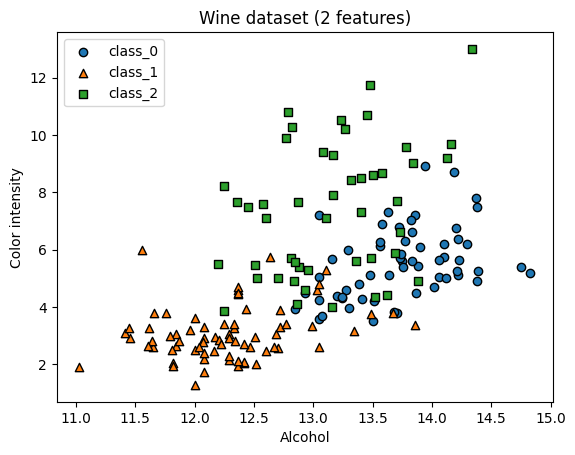

X2.shape: (178, 2)


In [ ]:
features_2d = ["alcohol", "color_intensity"]
idx = [wine.feature_names.index(f) for f in features_2d]
X2 = wine.data[:, idx]
y = wine.target

markers = ["o", "^", "s"]
for c in range(3):
    plt.scatter(X2[y == c, 0], X2[y == c, 1], marker=markers[c], edgecolor="k",
                label=wine.target_names[c])
plt.xlabel("Alcohol")
plt.ylabel("Color intensity")
plt.legend()
plt.title("Wine dataset (2 features)")
plt.show()
print(f"X2.shape: {X2.shape}")

### Step A3: Train a k-NN classifier (k = 7) with scikit-learn

> **Code explained:** Splits the 2-feature data into train and test sets (`stratify` keeps class ratios equal), trains a k-NN with k=7 and prints test predictions and accuracy. `fit` just stores the data; prediction is done by voting among neighbours.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X2, y, stratify=y, random_state=3)

clf = KNeighborsClassifier(n_neighbors=7)
clf.fit(X_train, y_train)

print(f"Test set predictions: {clf.predict(X_test)}")
print(f"Actual test labels  : {y_test}")
print(f"\nTest set accuracy: {clf.score(X_test, y_test):.2f}")

Test set predictions: [0 1 0 1 2 0 1 1 0 2 0 2 0 0 2 0 1 1 1 0 0 0 2 0 2 1 0 1 2 0 1 0 2 1 0 0 2
 1 1 1 0 1 1 1 2]
Actual test labels  : [0 1 0 1 2 0 1 0 0 2 2 2 0 0 2 1 1 1 1 0 2 0 2 2 2 1 0 1 2 0 1 0 2 1 0 0 2
 1 1 1 0 1 1 1 1]

Test set accuracy: 0.87


### Step A4: Decision boundaries for k = 1, 7, 25
Small k → jagged boundary (high complexity, overfitting). Large k → smooth boundary (low complexity).

> **Code explained:** Trains k-NN for three values of k and paints the decision boundary of each. Small k gives a jagged boundary (overfits), large k gives a smooth one (may underfit).

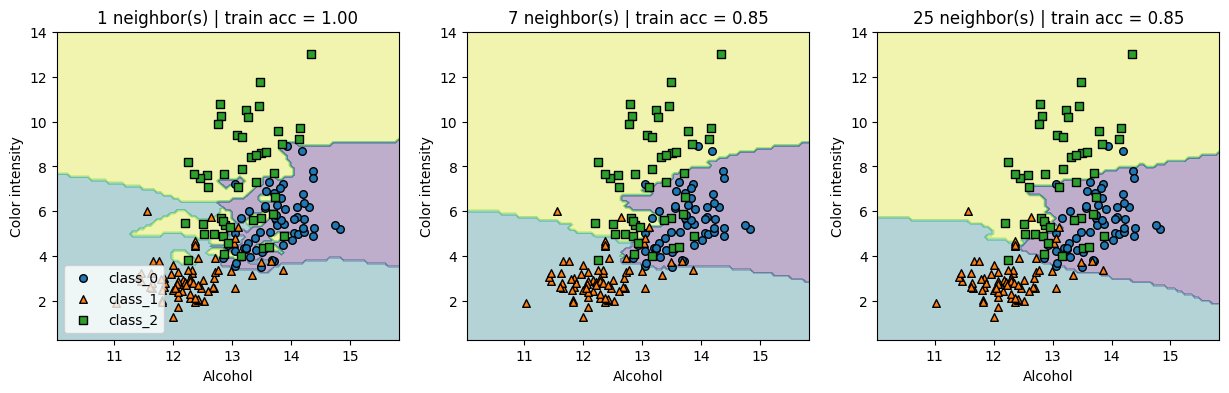

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for n_neighbors, ax in zip([1, 7, 25], axes):
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X2, y)
    DecisionBoundaryDisplay.from_estimator(clf, X2, response_method="predict",
                                           alpha=0.35, ax=ax)
    for c in range(3):
        ax.scatter(X2[y == c, 0], X2[y == c, 1], marker=markers[c], edgecolor="k", s=30,
                   label=wine.target_names[c])
    ax.set_title(f"{n_neighbors} neighbor(s) | train acc = {clf.score(X2, y):.2f}")
    ax.set_xlabel("Alcohol")
    ax.set_ylabel("Color intensity")
axes[0].legend(loc=3)
plt.show()

### Step A5: Model complexity — training vs test accuracy (all 13 features)
**Variation:** we plot the curve twice — on raw features and on standardised features — to see how much scaling matters for k-NN.

> **Code explained:** Uses all 13 features and loops over k = 1 to 25, once on raw data and once with `StandardScaler`. Plotting train vs test accuracy shows how model complexity and scaling affect k-NN.

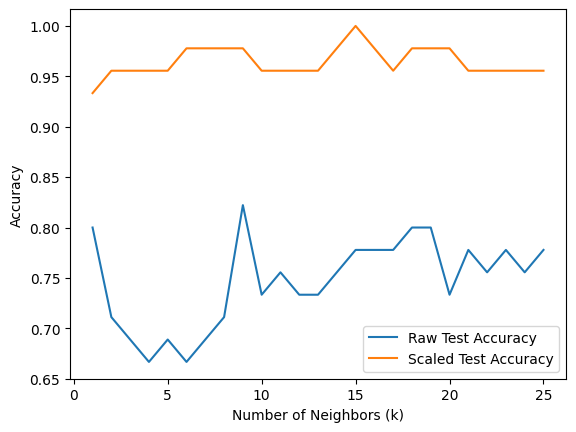

Best Raw Accuracy: 0.822
Best Scaled Accuracy: 1.0
Best k: 15


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(wine.data, wine.target,
                                                    stratify=wine.target, random_state=12)
neighbors_settings = range(1, 26)
# Store accuracy
raw_train, raw_test = [], []
scaled_train, scaled_test = [], []

# Test k values from 1 to 25
for k in range(1, 26):
    # Without scaling
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    raw_train.append(model.score(X_train, y_train))
    raw_test.append(model.score(X_test, y_test))

    # With scaling
    model = make_pipeline(StandardScaler(),
                          KNeighborsClassifier(n_neighbors=k))
    model.fit(X_train, y_train)
    scaled_train.append(model.score(X_train, y_train))
    scaled_test.append(model.score(X_test, y_test))

# Plot accuracy
plt.plot(range(1, 26), raw_test, label="Raw Test Accuracy")
plt.plot(range(1, 26), scaled_test, label="Scaled Test Accuracy")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Print best accuracy
best_k = np.argmax(scaled_test) + 1

print("Best Raw Accuracy:", round(max(raw_test), 3))
print("Best Scaled Accuracy:", round(max(scaled_test), 3))
print("Best k:", best_k)

**Observation:** compare the two plots and the printed best accuracies. On raw data `proline` (values in the hundreds/thousands) dominates the distance, so the other features are almost ignored. After `StandardScaler` every feature counts equally and accuracy is clearly higher.

### Step A6: Predict the cultivar of a new wine

> **Code explained:** Builds the final pipeline (scaler + k-NN with the best k found) and predicts the cultivar of a brand-new wine. `predict_proba` shows what share of the neighbours voted for each class.

In [ ]:
final_clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
final_clf.fit(X_train, y_train)

new_wine = np.array([[13.6, 1.9, 2.4, 16.5, 105, 2.9, 3.0, 0.28, 2.0, 5.6, 1.05, 3.1, 1150]])
pred = final_clf.predict(new_wine)[0]
print(f"Predicted cultivar: {wine.target_names[pred]}")
print(f"Class probabilities (share of the {best_k} neighbours): {final_clf.predict_proba(new_wine).round(2)}")

Predicted cultivar: class_0
Class probabilities (share of the 15 neighbours): [[1. 0. 0.]]


---
# Part B — k-NN Regression on a Synthetic Wave Dataset

We create our own one-feature regression dataset:

$$y = \sin(2x) + 0.2x + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.25^2)$$

### Step B1: Generate and plot the data

> **Code explained:** Creates our own regression data: a sine wave plus a slight upward trend plus random noise. A one-feature dataset is easy to plot, so we can see what the model learns.

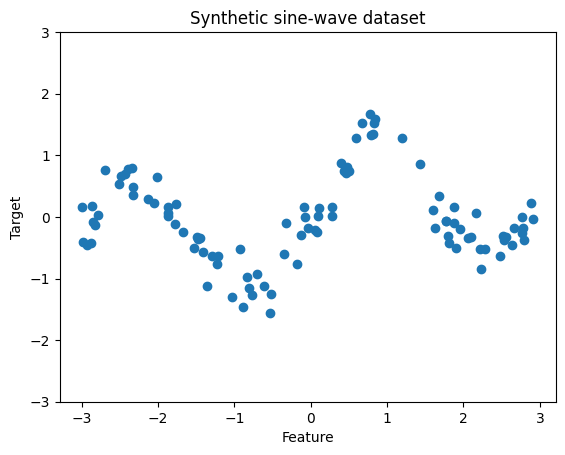

X.shape: (100, 1)


In [ ]:
rng = np.random.RandomState(5)
n_samples = 100
X = np.sort(rng.uniform(-3, 3, n_samples)).reshape(-1, 1)
y = np.sin(2 * X).ravel() + 0.2 * X.ravel() + rng.normal(0, 0.25, n_samples)

plt.plot(X, y, "o")
plt.ylim(-3, 3)
plt.xlabel("Feature")
plt.ylabel("Target")
plt.title("Synthetic sine-wave dataset")
plt.show()
print(f"X.shape: {X.shape}")

### Step B2: Train `KNeighborsRegressor` (k = 4)
The prediction is the **mean** of the targets of the k nearest training points.

> **Code explained:** Splits the wave data, trains `KNeighborsRegressor` (k=4) and prints the R² score. The prediction here is the **average** of the k nearest targets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=4)

reg = KNeighborsRegressor(n_neighbors=4)
reg.fit(X_train, y_train)

print(f"Test set predictions:\n{reg.predict(X_test).round(3)}")
print(f"\nTest set R^2: {reg.score(X_test, y_test):.2f}")

Test set predictions:
[ 0.047  0.62  -0.066  0.533  1.41  -0.188 -0.163 -0.066 -1.227 -0.195
 -0.798 -0.186 -0.173 -0.58   0.62  -1.203  0.62  -0.613 -1.297 -0.158
 -0.106 -0.147 -0.176 -0.097 -0.404]

Test set R^2: 0.80


### Step B3: Predictions for k = 1, 4, 12
**Variation:** the top row uses `weights='uniform'` (plain mean), the bottom row uses `weights='distance'` (closer neighbours count more).

> **Code explained:** Draws the fitted curve for k = 1, 4 and 12, with `uniform` weights (top row) and `distance` weights (bottom row). Distance weighting gives closer neighbours more say.

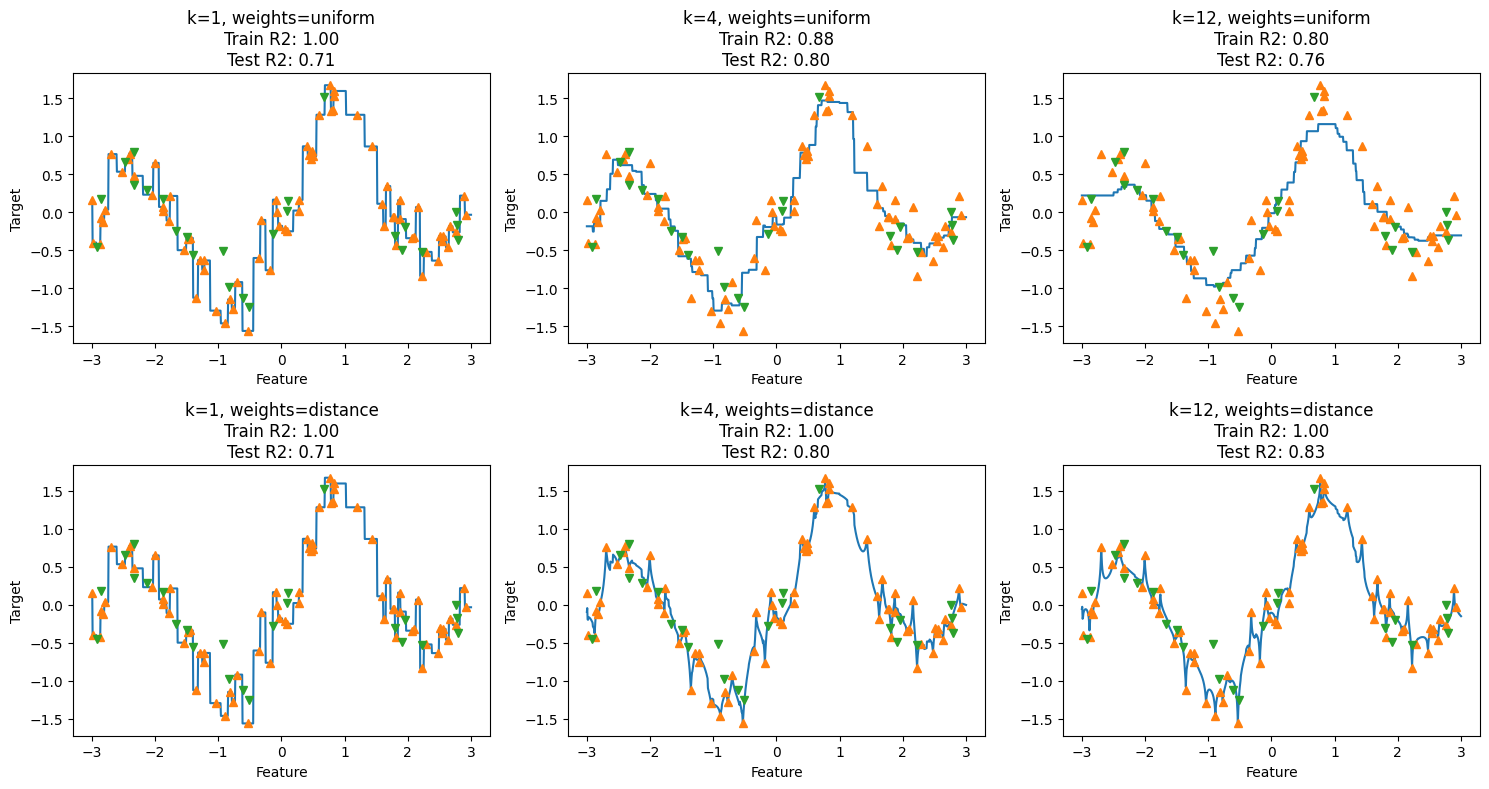

In [ ]:
line = np.linspace(-3, 3, 1000).reshape(-1, 1)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

k_values = [1, 4, 12]
weights = ["uniform", "distance"]

for i in range(2):
    for j in range(3):
        model = KNeighborsRegressor(
            n_neighbors=k_values[j],
            weights=weights[i]
        )
        model.fit(X_train, y_train)

        axes[i, j].plot(line, model.predict(line))
        axes[i, j].plot(X_train, y_train, "^")
        axes[i, j].plot(X_test, y_test, "v")

        axes[i, j].set_title(
            f"k={k_values[j]}, weights={weights[i]}\n"
            f"Train R2: {model.score(X_train, y_train):.2f}\n"
            f"Test R2: {model.score(X_test, y_test):.2f}"
        )
        axes[i, j].set_xlabel("Feature")
        axes[i, j].set_ylabel("Target")

plt.tight_layout()
plt.show()

With `weights='distance'` the training R² is always 1.0 (each training point is its own nearest neighbour at distance 0), so the test score is the one to compare.

### Step B4: R² against k

> **Code explained:** Computes train and test R² for k = 1 to 20 and plots them, then reports the k with the best test R². Small k = wiggly/overfit, large k = too flat.

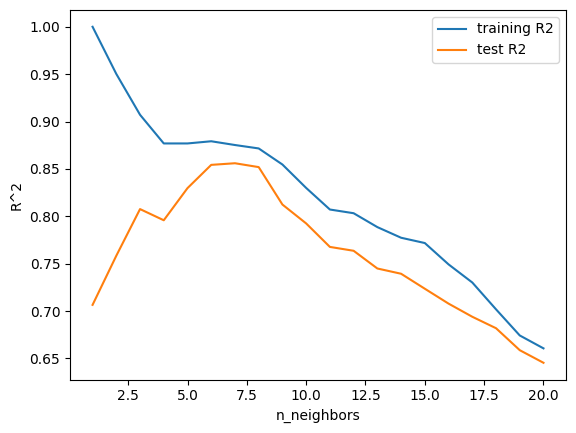

Best k on test set = 7 (R2 = 0.856)


In [ ]:
ks = range(1, 21)
train_r2, test_r2 = [], []
for k in ks:
    reg = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    train_r2.append(reg.score(X_train, y_train))
    test_r2.append(reg.score(X_test, y_test))

plt.plot(ks, train_r2, label="training R2")
plt.plot(ks, test_r2, label="test R2")
plt.xlabel("n_neighbors")
plt.ylabel("R^2")
plt.legend()
plt.show()

best_k = int(np.argmax(test_r2)) + 1
print(f"Best k on test set = {best_k} (R2 = {max(test_r2):.3f})")

### Step B5: Predict for new points

> **Code explained:** Predicts for three new x values with the best k and compares with the true noise-free value. This is a quick sanity check of how close the model gets.

In [ ]:
reg = KNeighborsRegressor(n_neighbors=best_k).fit(X_train, y_train)
X_new = np.array([[-2.0], [0.5], [1.5]])
for x_val, pred in zip(X_new.ravel(), reg.predict(X_new)):
    true_val = np.sin(2 * x_val) + 0.2 * x_val
    print(f"x = {x_val:5.1f} -> predicted y = {pred:6.3f} (noise-free true value = {true_val:6.3f})")

x =  -2.0 -> predicted y =  0.221 (noise-free true value =  0.357)
x =   0.5 -> predicted y =  0.760 (noise-free true value =  0.941)
x =   1.5 -> predicted y =  0.329 (noise-free true value =  0.441)


### Which distance metric is best for k-NN?
k-NN needs a definition of 'distance'. Until now we used the default (Euclidean). Here we try **Manhattan** (sum of absolute differences) and **Chebyshev** (largest single difference) too.

> **Code explained:** For each metric we build a *scaled* k-NN pipeline (k=7) and measure accuracy with 5-fold cross-validation, which is more reliable than a single split. The table lists mean accuracy and its spread; the last lines print which metric won.

In [ ]:
from sklearn.model_selection import cross_val_score

metrics = ["euclidean", "manhattan", "chebyshev"]
rows = []

for metric in metrics:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=7, metric=metric)
    )

    scores = cross_val_score(model, wine.data, wine.target, cv=5)
    rows.append([metric, scores.mean(), scores.std()])

table = pd.DataFrame(
    rows,
    columns=["metric", "mean CV accuracy", "std"]
).round(3)

print(table.to_string(index=False))

best = table.loc[table["mean CV accuracy"].idxmax()]
spread = table["mean CV accuracy"].max() - table["mean CV accuracy"].min()

print(f"\nConclusion: '{best['metric']}' gave the best mean CV accuracy "
      f"({best['mean CV accuracy']:.3f}); the gap between the best "
      f"and the worst metric is {spread:.3f}.")

   metric  mean CV accuracy   std
euclidean             0.967 0.021
manhattan             0.955 0.042
chebyshev             0.916 0.032

Conclusion: 'euclidean' gave the best mean CV accuracy (0.967); the gap between the best and the worst metric is 0.051.


**Conclusion:** Euclidean and Manhattan distance give very similar accuracy, while Chebyshev (which looks only at the single largest feature difference and ignores the rest) is noticeably weaker on Wine. The metric matters less than **scaling the features** and choosing a sensible **k**, but it is still worth testing.

---
## Lab 1 summary
| | Part A (Wine, classification) | Part B (wave, regression) |
|---|---|---|
| Prediction rule | majority vote of k neighbours | mean (or distance-weighted mean) of k neighbours |
| Metric | accuracy | R² |
| Key lesson | scale features before k-NN | small k overfits, large k underfits |
| Our addition | distance-metric comparison (Euclidean / Manhattan / Chebyshev) | — |

---

# Lab 2 — Linear Regression

Linear regression fits a straight line (or plane) $y = \theta_0 + \theta_1 x$ by minimising the squared error.

| Part | Data | Task |
|---|---|---|
| A | Diabetes dataset (real, 442 patients) | predict disease progression from **BMI** |
| B | Synthetic *City Wellbeing Survey* (two CSV files) | predict a city's **happiness score** from **average income** |

**Our own addition (inside Part A):** we repeat the train/test split **20 times** to check whether a simple model (BMI only) or a multiple regression is really better, not just lucky on one split.

> **Code explained:** Imports the libraries and sets Matplotlib label sizes so plots are readable. `LinearRegression` comes from `sklearn.linear_model`, and `r2_score`/`mean_squared_error` are for evaluation.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn.linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# To plot pretty figures directly within Jupyter
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

---
# Part A — Diabetes Progression vs BMI

**Problem Statement:** Train a Linear Regression model that predicts a patient's **disease progression score** from their **Body Mass Index (BMI)**, then predict for a new patient with BMI 28.

### Step A1: Load and explore the data

> **Code explained:** Loads the Diabetes dataset as a DataFrame (`scaled=False` keeps original units such as BMI in kg/m²) and shows its shape and first rows.

In [ ]:
from sklearn.datasets import load_diabetes

# scaled=False gives the original units (BMI in kg/m^2, blood pressure in mm Hg, ...)
diabetes = load_diabetes(as_frame=True, scaled=False)
df = diabetes.frame
print(df.shape)
df.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


> **Code explained:** Summary statistics of a few columns (BMI, blood pressure, s5 and the target). It tells us the typical ranges before modelling.

In [ ]:
df[["bmi", "bp", "s5", "target"]].describe().round(2)

,bmi,bp,s5,target
count,442.00,442.00,442.00,442.00
mean,26.38,94.65,4.64,152.13
std,4.42,13.83,0.52,77.09
min,18.00,62.00,3.26,25.00
25%,23.20,84.00,4.28,87.00
50%,25.70,93.00,4.62,140.50
75%,29.28,105.00,5.00,211.50
max,42.20,133.00,6.11,346.00


> **Code explained:** Turns BMI and the target into column vectors, draws a scatter plot and prints the correlation. A clear upward cloud and a positive correlation suggest a linear model is reasonable.

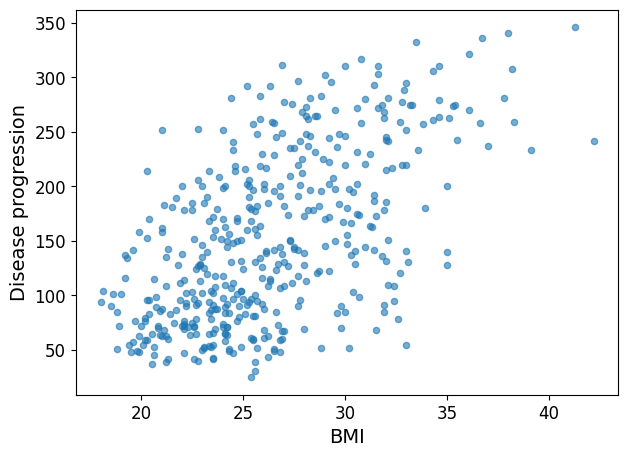

Correlation between BMI and progression: 0.586


In [ ]:
# Prepare the data (same style as the lab: column vectors with np.c_)
X = np.c_[df["bmi"]]
y = np.c_[df["target"]]

# Visualize the data
df.plot(kind="scatter", x="bmi", y="target", alpha=0.6, figsize=(7, 5))
plt.xlabel("BMI")
plt.ylabel("Disease progression")
plt.show()

print(f"Correlation between BMI and progression: {df['bmi'].corr(df['target']):.3f}")

### Step A2: Model selection, training and prediction

> **Code explained:** Creates the `LinearRegression` model, trains it with `fit`, and prints the intercept and slope. The slope says how much the progression score changes per +1 BMI. Then it predicts for a new patient.

In [ ]:
# Select a linear model
model = sklearn.linear_model.LinearRegression()

# Train the model
model.fit(X, y)

theta0, theta1 = model.intercept_[0], model.coef_[0][0]
print(f"Intercept (theta0) = {theta0:.2f}")
print(f"Slope     (theta1) = {theta1:.2f}  -> each +1 BMI adds ~{theta1:.1f} to the progression score")

# Make a prediction for a new patient with BMI = 28.0
X_new = [[28.0]]
print(f"\nPredicted progression for BMI 28.0: {model.predict(X_new)[0][0]:.1f}")

Intercept (theta0) = -117.77
Slope     (theta1) = 10.23  -> each +1 BMI adds ~10.2 to the progression score

Predicted progression for BMI 28.0: 168.8


> **Code explained:** Plots the data, the fitted red line and the new patient's prediction (black star). A visual check that the line follows the trend.

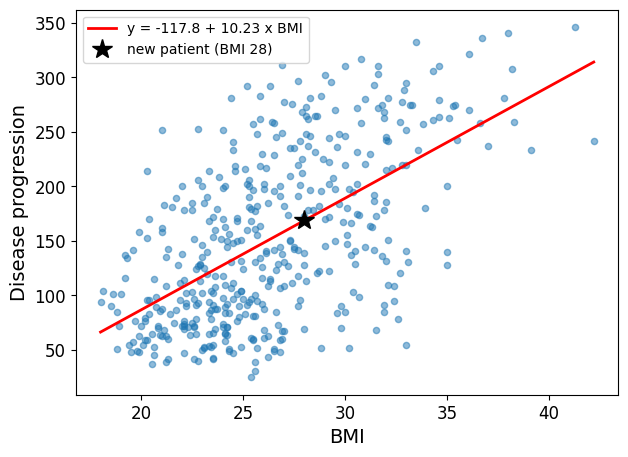

In [ ]:
# Plot the fitted line
df.plot(kind="scatter", x="bmi", y="target", alpha=0.5, figsize=(7, 5))
bmi_line = np.linspace(df["bmi"].min(), df["bmi"].max(), 100).reshape(-1, 1)
plt.plot(bmi_line, model.predict(bmi_line), "r-", linewidth=2,
         label=f"y = {theta0:.1f} + {theta1:.2f} x BMI")
plt.plot(28.0, model.predict([[28.0]])[0][0], "k*", markersize=15, label="new patient (BMI 28)")
plt.xlabel("BMI")
plt.ylabel("Disease progression")
plt.legend()
plt.show()

### Step A3: Evaluate on a test set and try multiple regression
BMI alone explains only part of the variation. Let's check the R² on unseen data and see whether adding blood pressure (`bp`) and the serum measurements `s5` and `s3` helps.

> **Code explained:** Splits the data into train/test and fits two models: BMI only vs BMI + blood pressure + two blood-serum features. Test R² and RMSE show whether extra features help on unseen data.

In [ ]:
train_df, test_df = train_test_split(df, test_size=0.25, random_state=7)

for features in (["bmi"], ["bmi", "bp", "s5", "s3"]):
    lin = sklearn.linear_model.LinearRegression()
    lin.fit(train_df[features], train_df["target"])
    pred = lin.predict(test_df[features])
    rmse = np.sqrt(mean_squared_error(test_df["target"], pred))
    print(f"Features {features}: test R2 = {r2_score(test_df['target'], pred):.3f}, test RMSE = {rmse:.1f}")

Features ['bmi']: test R2 = 0.370, test RMSE = 61.3
Features ['bmi', 'bp', 's5', 's3']: test R2 = 0.507, test RMSE = 54.2


### Is the result stable across different splits?
One train/test split can be lucky or unlucky. Here we repeat the split with 20 different random seeds and compare **BMI only** against **BMI + bp + s5 + s3**.

> **Code explained:** The loop splits the data 20 times, fits both models on each training part and stores the test R². The box plot shows the spread of R² for each model, and the printed lines give the mean and standard deviation.

BMI only: Mean R2 = 0.328 Std = 0.083
Multiple: Mean R2 = 0.47 Std = 0.06


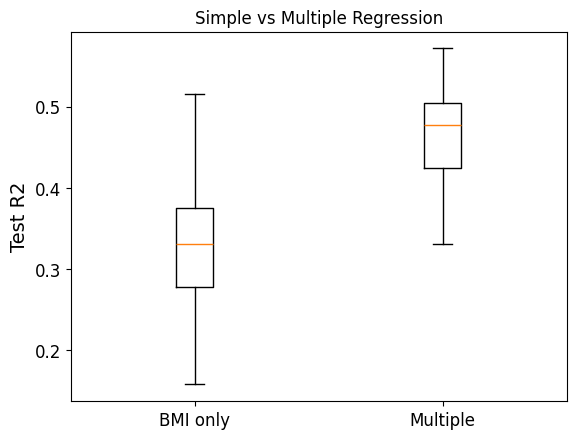


Multiple regression performed better in 20 out of 20 splits.


In [ ]:
from sklearn.linear_model import LinearRegression

simple = []
multiple = []

for i in range(20):
    train, test = train_test_split(df, test_size=0.25, random_state=i)

    model1 = LinearRegression()
    model1.fit(train[["bmi"]], train["target"])
    simple.append(r2_score(test["target"], model1.predict(test[["bmi"]])))

    model2 = LinearRegression()
    model2.fit(train[["bmi", "bp", "s5", "s3"]], train["target"])
    multiple.append(r2_score(test["target"], model2.predict(test[["bmi", "bp", "s5", "s3"]])))

print("BMI only: Mean R2 =", round(np.mean(simple), 3),
      "Std =", round(np.std(simple), 3))

print("Multiple: Mean R2 =", round(np.mean(multiple), 3),
      "Std =", round(np.std(multiple), 3))

plt.boxplot([simple, multiple])
plt.xticks([1, 2], ["BMI only", "Multiple"])
plt.ylabel("Test R2")
plt.title("Simple vs Multiple Regression")
plt.show()

wins = sum(m > s for m, s in zip(multiple, simple))
print("\nMultiple regression performed better in", wins, "out of 20 splits.")

**Conclusion:** adding more features gives a higher R² on almost every split, and its spread is no larger, so the improvement is real and not luck. Even so, a large part of the variation stays unexplained, because disease progression depends on many other things.

---
# Part B — City Happiness vs Average Monthly Income

**Problem Statement:** A (synthetic) *City Wellbeing Survey* reports several indicators per city in **long format**, split by group (`TOT`, `MEN`, `WOMEN`). A second file holds each city's **average monthly income (₹)**. Merge the two, train a linear model, and predict the happiness of a city that is not in the survey.

### Step B0: Understand `pivot` with a small example

> **Code explained:** Teaches `pivot` vs `pivot_table` with a tiny example. `pivot_table` can average duplicate rows, which plain `pivot` cannot.

In [ ]:
demo = pd.DataFrame({"city": ["Pune", "Pune", "Pune", "Surat", "Surat", "Surat"],
                     "indicator": ["Happiness", "Commute", "Happiness", "Happiness", "Commute", "Commute"],
                     "value": [6.8, 42, 7.0, 6.1, 35, 39]})
print("Original long dataframe")
print(demo)
print("\nReshaped with pivot_table (mean of duplicates)")
print(demo.pivot_table(index="city", columns="indicator", values="value", aggfunc="mean"))

Original long dataframe
    city  indicator  value
0   Pune  Happiness    6.8
1   Pune    Commute   42.0
2   Pune  Happiness    7.0
3  Surat  Happiness    6.1
4  Surat    Commute   35.0
5  Surat    Commute   39.0

Reshaped with pivot_table (mean of duplicates)
indicator  Commute  Happiness
city                         
Pune          42.0        6.9
Surat         37.0        6.1


### Step B1: Create the two raw data files
We generate the two files once and save them to `datasets/citystats/`, so the rest of the notebook reads them from disk exactly like downloaded data.

> **Code explained:** Generates two raw files like the real-world OECD/IMF ones: a *long format* survey file and a tab-separated income file with numbers stored as text with commas. They are saved to disk so we can load them like real downloads.

In [ ]:
datapath = os.path.join("datasets", "citystats", "")
os.makedirs(datapath, exist_ok=True)

rng = np.random.RandomState(13)
cities = ["Ahmedabad", "Bengaluru", "Bhopal", "Bhubaneswar", "Chandigarh", "Chennai", "Coimbatore",
          "Dehradun", "Delhi", "Goa", "Guwahati", "Hyderabad", "Indore", "Jaipur", "Kochi", "Kolkata",
          "Lucknow", "Ludhiana", "Madurai", "Mangaluru", "Mumbai", "Mysuru", "Nagpur", "Patna", "Pune",
          "Raipur", "Ranchi", "Shimla", "Surat", "Thiruvananthapuram", "Vadodara", "Varanasi",
          "Visakhapatnam", "Gurugram", "Noida"]
n = len(cities)
income = rng.uniform(15000, 95000, n).round(-2)
happiness = (3.8 + 3.0 * (income - 15000) / 80000 + rng.normal(0, 0.3, n)).clip(1, 10)

# Two "outlier" cities: very high income but average happiness (long working hours!)
income[-2:] = [175000, 195000]
happiness[-2:] = [6.4, 6.0]

air_quality = rng.uniform(40, 250, n).round()
commute_mins = rng.uniform(20, 75, n).round()

rows = []
for i, city in enumerate(cities):
    for indicator, value in [("Happiness score", happiness[i]),
                             ("Air quality index", air_quality[i]),
                             ("Commute time (mins)", commute_mins[i])]:
        rows.append([city, indicator, "TOT", round(value, 2)])
        rows.append([city, indicator, "MEN", round(value * rng.uniform(0.95, 1.05), 2)])
        rows.append([city, indicator, "WOMEN", round(value * rng.uniform(0.95, 1.05), 2)])
survey = pd.DataFrame(rows, columns=["City", "Indicator", "GROUP", "Value"])
survey.to_csv(datapath + "city_wellbeing_long.csv", index=False)

income_table = pd.DataFrame({"City": cities,
                             "Region": ["India"] * n,
                             "2025": [f"{v:,.0f}" for v in income],   # stored as text with commas
                             "Estimates Start After": [2024] * n})
income_table.to_csv(datapath + "city_income.tsv", sep="\t", index=False)
print(os.listdir(datapath))

['city_wellbeing_long.csv', 'city_income.tsv']


### Step B2: Load, merge and prepare the data

> **Code explained:** A reusable function that filters the 'TOT' rows, pivots long data to wide, merges with the income table, sorts, and removes outliers using the IQR rule. It then loads both files and builds `X` and `y`.

In [ ]:
def prepare_city_stats(survey, income):
    survey = survey[survey["GROUP"] == "TOT"]
    survey = survey.pivot(index="City", columns="Indicator", values="Value")

    income = income.rename(columns={"2025": "Avg monthly income"})
    income = income.set_index("City")

    full_city_stats = pd.merge(survey, income, left_index=True, right_index=True)
    full_city_stats = full_city_stats.sort_values("Avg monthly income")

    q1 = full_city_stats["Avg monthly income"].quantile(0.25)
    q3 = full_city_stats["Avg monthly income"].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)

    removed = full_city_stats[full_city_stats["Avg monthly income"] > upper]
    print("Removed outliers:", list(removed.index))
    city_stats = full_city_stats[full_city_stats["Avg monthly income"] <= upper]
    return city_stats[["Avg monthly income", "Happiness score"]], full_city_stats


survey_raw = pd.read_csv(datapath + "city_wellbeing_long.csv")
income_raw = pd.read_csv(datapath + "city_income.tsv", delimiter="\t", thousands=",")

city_stats, full_city_stats = prepare_city_stats(survey_raw, income_raw)

X = np.c_[city_stats["Avg monthly income"]]
y = np.c_[city_stats["Happiness score"]]

print(city_stats.head())

Removed outliers: ['Gurugram', 'Noida']
          Avg monthly income  Happiness score
City                                         
Surat                  15700             3.45
Madurai                15800             3.50
Pune                   17600             3.88
Guwahati               17800             4.32
Indore                 19700             4.03


> **Code explained:** Scatter plot of income vs happiness with the removed outliers in red and some city names labelled. This shows why the outliers are suspicious.

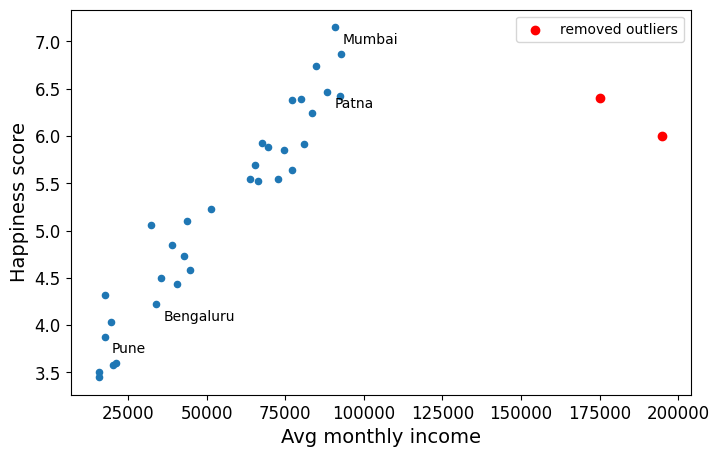

In [ ]:
# Visualize the data (outliers shown in red)
ax = city_stats.plot(kind="scatter", x="Avg monthly income", y="Happiness score", figsize=(8, 5))
outliers = full_city_stats.drop(city_stats.index)
ax.scatter(outliers["Avg monthly income"], outliers["Happiness score"], color="red", label="removed outliers")
for city in ["Patna", "Pune", "Mumbai", "Bengaluru"]:
    if city in city_stats.index:
        ax.annotate(city, (city_stats.loc[city, "Avg monthly income"], city_stats.loc[city, "Happiness score"]),
                    xytext=(5, -12), textcoords="offset points")
plt.legend()
plt.show()

### Step B3: Model selection, training and prediction

> **Code explained:** Trains linear regression on the cleaned cities, prints the parameters and training R², and predicts happiness for a city that is not in the survey.

In [ ]:
# Select a linear model
model = sklearn.linear_model.LinearRegression()

# Train the model
model.fit(X, y)
print(f"theta0 = {model.intercept_[0]:.3f}, theta1 = {model.coef_[0][0]:.7f}")
print(f"R^2 on the training cities = {model.score(X, y):.3f}")

# Make a prediction for Kolhapur (not in the survey)
X_new = [[46000]]  # Kolhapur's average monthly income
print(f"\nPredicted happiness for Kolhapur (Linear Regression): {model.predict(X_new)[0][0]:.2f}")

theta0 = 3.102, theta1 = 0.0000390
R^2 on the training cities = 0.928

Predicted happiness for Kolhapur (Linear Regression): 4.89


> **Code explained:** Replaces the linear model by k-NN regression (k=5) for the same city and prints the nearest cities used. It shows how a different model type reasons about the same input.

In [ ]:
# Variation: replace the linear model by k-NN regression (k = 5)
import sklearn.neighbors
knn_model = sklearn.neighbors.KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X, y)
print(f"Predicted happiness for Kolhapur (5-NN regression): {knn_model.predict(X_new)[0][0]:.2f}")

# Which 5 cities were used?
dist, ind = knn_model.kneighbors(X_new)
print("Nearest cities by income:", list(city_stats.index[ind[0]]))

Predicted happiness for Kolhapur (5-NN regression): 4.82
Nearest cities by income: ['Kochi', 'Mangaluru', 'Ludhiana', 'Chennai', 'Nagpur']


> **Code explained:** Plots two fitted lines: one trained without outliers and one with all cities. It makes the effect of outliers on a linear model very visible.

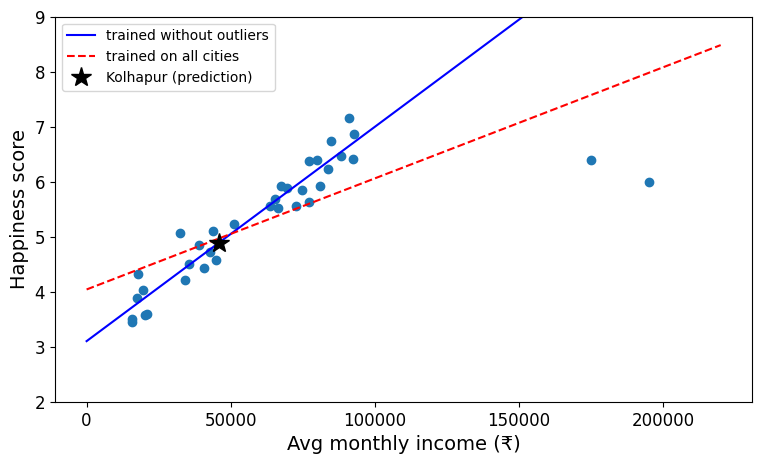

In [ ]:
# Plot the fitted line with and without the outliers
x_line = np.linspace(0, 220000, 200).reshape(-1, 1)
model_all = sklearn.linear_model.LinearRegression().fit(
    np.c_[full_city_stats["Avg monthly income"]], np.c_[full_city_stats["Happiness score"]])

plt.figure(figsize=(9, 5))
plt.scatter(full_city_stats["Avg monthly income"], full_city_stats["Happiness score"], c="tab:blue")
plt.plot(x_line, model.predict(x_line), "b-", label="trained without outliers")
plt.plot(x_line, model_all.predict(x_line), "r--", label="trained on all cities")
plt.plot(46000, model.predict(X_new)[0][0], "k*", markersize=15, label="Kolhapur (prediction)")
plt.xlabel("Avg monthly income (₹)")
plt.ylabel("Happiness score")
plt.ylim(2, 9)
plt.legend()
plt.show()

**Observation:** the two very rich outlier cities pull the red line down and make it flatter. Removing them gives a model that fits the typical cities better — but the model should not be trusted for incomes far outside the training range.

---
## Lab 2 summary
| | Part A | Part B |
|---|---|---|
| Data preparation | none needed | filter `TOT` → `pivot` → `merge` → sort → IQR outlier removal |
| Extra comparison | simple vs multiple regression (+ 20-split stability check) | Linear Regression vs 5-NN regression |

---

# Lab 3 — End-to-End Machine-Learning Project

This lab walks through the full ML workflow twice: **get data → split → explore → clean → encode/scale → train models → fine-tune → test**.

| | Project A | Project B |
|---|---|---|
| Data | Synthetic **used-car** listings (4,000 cars) | Synthetic **Pune flat** listings (3,500 flats) |
| Target | `selling_price_lakhs` | `price_lakhs` |
| Categorical columns | `fuel_type`, `transmission` | `locality`, `parking` |
| Missing values | `max_power_bhp` | `bathrooms`, `dist_station_km` |

Both datasets are generated here and saved to CSV, so the rest reads them with `pd.read_csv` like a real file.

**Our own addition (end of Project A):** a **baseline model** that always predicts the average price. If our model can't beat that, it is useless — so it is a good reality check.

> **Code explained:** Imports everything needed for the whole project: pandas/NumPy, splitting tools, imputer, encoders, scalers, pipelines, several regression models and metrics. It also defines `display_scores`, a small helper to print cross-validation results.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from zlib import crc32

from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

os.makedirs("datasets", exist_ok=True)

def display_scores(scores):
    print("Scores:", scores.round(3))
    print("Mean:", round(scores.mean(), 3))
    print("Standard Deviation:", round(scores.std(), 3))

---
# Project A — Used-Car Price Prediction

**Problem Statement:** Predict the selling price (₹ lakhs) of a used car from its year, kilometres driven, engine size, power, seats, number of owners, fuel type and transmission.

### Step A0: Generate the dataset and save it as CSV

> **Code explained:** Generates 4,000 fake used cars: year, km driven, engine size, power, owners, fuel and transmission, then builds the price from a depreciation formula plus noise. 80 power values are blanked out on purpose to practise handling missing data. The result is saved to CSV.

In [ ]:
np.random.seed(2024)
n = 4000

year = np.random.randint(2010, 2025, n)
age = 2026 - year

fuel_type = np.random.choice(["Petrol", "Diesel", "CNG"], n, p=[0.55, 0.35, 0.10])
transmission = np.random.choice(["Manual", "Automatic"], n, p=[0.72, 0.28])
engine_cc = np.random.choice([800, 1000, 1200, 1500, 1800, 2000, 2500], n)

max_power = (engine_cc * 0.075 + np.random.normal(0, 8, n)).clip(35).round(1)
km_driven = (np.random.randint(2000, 15000, n) * age).clip(500)
owner_count = np.random.choice([1, 2, 3, 4], n, p=[0.60, 0.27, 0.10, 0.03])
seats = np.random.choice([5, 7], n, p=[0.82, 0.18])

price = (2.5 + 0.08 * max_power) * (0.88 ** age)
price = price * np.where(transmission == "Automatic", 1.12, 1)
price = price * np.where(fuel_type == "Diesel", 1.08, 1)
price = price * np.where(fuel_type == "CNG", 0.92, 1)
price = price * (0.95 ** (owner_count - 1))
price = price * np.exp(np.random.normal(0, 0.12, n))

cars = pd.DataFrame({
    "car_id": range(100001, 100001 + n),
    "year": year,
    "km_driven": km_driven,
    "engine_cc": engine_cc,
    "max_power_bhp": max_power,
    "seats": seats,
    "owner_count": owner_count,
    "fuel_type": fuel_type,
    "transmission": transmission,
    "selling_price_lakhs": price.round(2)
})

cars.loc[np.random.choice(n, 80, replace=False), "max_power_bhp"] = np.nan

cars.to_csv("datasets/used_cars.csv", index=False)

print(cars.head())

   car_id  year  km_driven  engine_cc  max_power_bhp  seats  owner_count  \
0  100001  2018      91168        800           58.2      7            1   
1  100002  2020      65814       1800          130.2      5            3   
2  100003  2010     105360       2500          185.4      5            1   
3  100004  2010     182960       1800          113.9      5            1   
4  100005  2021      24490       2000          152.2      7            1   

  fuel_type transmission  selling_price_lakhs  
0    Petrol    Automatic                 2.37  
1    Diesel       Manual                 6.31  
2    Diesel       Manual                 2.21  
3    Diesel    Automatic                 1.84  
4    Diesel       Manual                 9.61  


### Step A1: Load and take a quick look at the data

> **Code explained:** Loads the CSV with `pd.read_csv` and shows the first 5 rows — the first look at any dataset.

In [ ]:
cars = pd.read_csv("datasets/used_cars.csv")
cars.head()

,car_id,year,km_driven,engine_cc,max_power_bhp,seats,owner_count,fuel_type,transmission,selling_price_lakhs
0,100001,2018,91168,800,58.2,7,1,Petrol,Automatic,2.37
1,100002,2020,65814,1800,130.2,5,3,Diesel,Manual,6.31
2,100003,2010,105360,2500,185.4,5,1,Diesel,Manual,2.21
3,100004,2010,182960,1800,113.9,5,1,Diesel,Automatic,1.84
4,100005,2021,24490,2000,152.2,7,1,Diesel,Manual,9.61


> **Code explained:** `info()` lists every column, its type and the number of non-null values. It reveals which columns have missing data and which are text.

In [ ]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   car_id               4000 non-null   int64  
 1   year                 4000 non-null   int64  
 2   km_driven            4000 non-null   int64  
 3   engine_cc            4000 non-null   int64  
 4   max_power_bhp        3920 non-null   float64
 5   seats                4000 non-null   int64  
 6   owner_count          4000 non-null   int64  
 7   fuel_type            4000 non-null   object 
 8   transmission         4000 non-null   object 
 9   selling_price_lakhs  4000 non-null   float64
dtypes: float64(2), int64(6), object(2)
memory usage: 312.6+ KB


> **Code explained:** Counts the categories in the two text columns. We need to know them before choosing an encoder.

In [ ]:
print(cars["fuel_type"].value_counts(), "\n")
print(cars["transmission"].value_counts())

fuel_type
Petrol    2241
Diesel    1365
CNG        394
Name: count, dtype: int64 

transmission
Manual       2887
Automatic    1113
Name: count, dtype: int64


> **Code explained:** `describe()` gives count, mean, std and quartiles for numeric columns, which helps spot odd ranges.

In [ ]:
cars.describe().round(2)

,car_id,year,km_driven,engine_cc,max_power_bhp,seats,owner_count,selling_price_lakhs
count,4000.00,4000.00,4000.00,4000.00,3920.00,4000.00,4000.00,4000.00
mean,102000.50,2016.94,76645.41,1524.35,114.41,5.34,1.56,4.38
std,1154.84,4.35,53033.00,548.37,41.91,0.76,0.80,2.83
min,100001.00,2010.00,4072.00,800.00,37.70,5.00,1.00,0.65
25%,101000.75,2013.00,34080.00,1000.00,78.18,5.00,1.00,2.22
50%,102000.50,2017.00,62444.00,1500.00,111.15,5.00,1.00,3.57
75%,103000.25,2021.00,110739.00,2000.00,145.22,5.00,2.00,5.80
max,104000.00,2024.00,239264.00,2500.00,210.80,7.00,4.00,20.46


> **Code explained:** Draws a histogram of every numeric column to see the shape of each distribution (skewed? capped?).

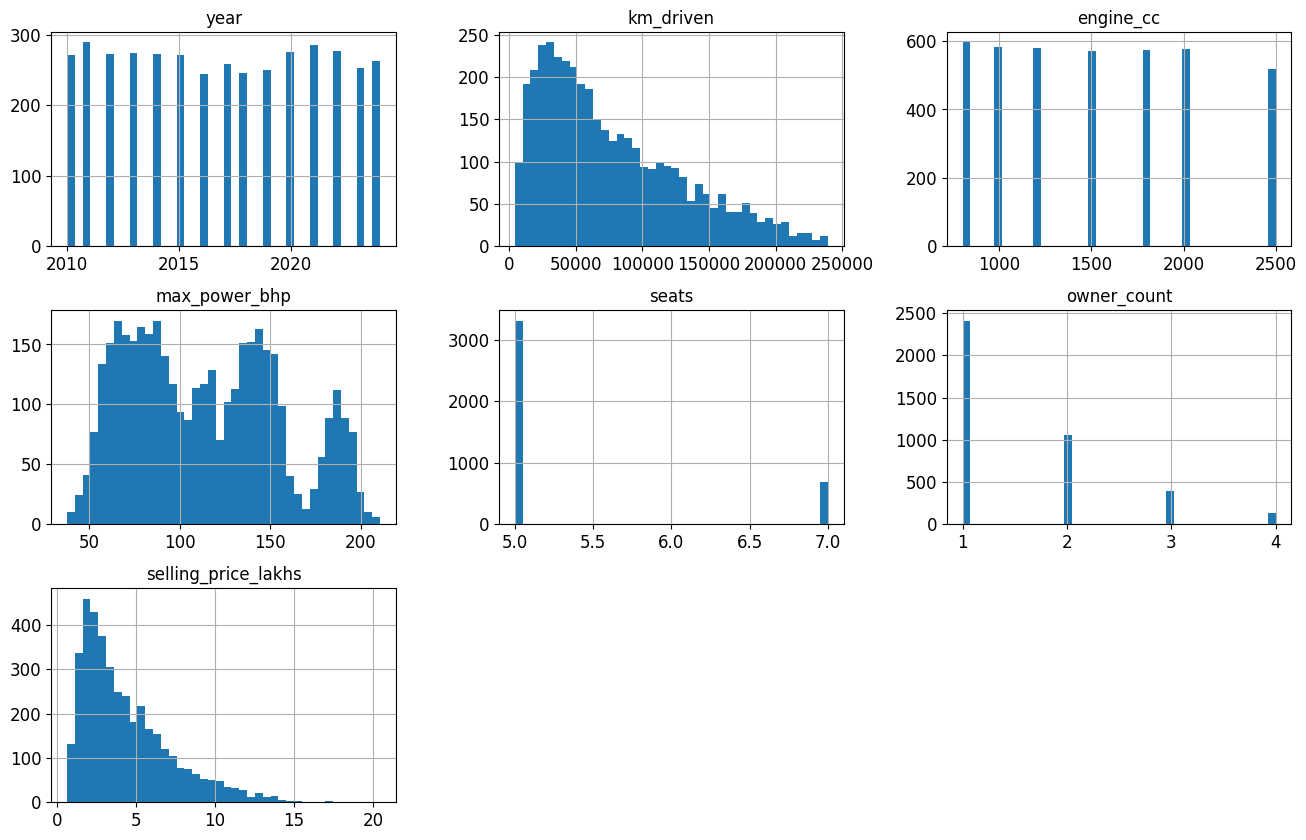

In [ ]:
cars.drop(columns="car_id").hist(bins=40, figsize=(16, 10))
plt.show()

### Step A2: Test set generation
**(a) Hash-based split using a stable identifier.** Our cars already have a unique `car_id`, so we can use it to decide, in a repeatable way, which rows are test rows.

> **Code explained:** Defines a **hash-based split** using `car_id`: each id is hashed with CRC32 and goes to test if the hash is small enough. The same car always stays in the same set, even if new rows are added later.

In [ ]:
def test_set_check(identifier, test_ratio):
    return crc32(np.int64(identifier)) & 0xffffffff < test_ratio * 2**32

def split_train_test_by_id(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: test_set_check(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

train_set, test_set = split_train_test_by_id(cars, 0.25, "car_id")
print(len(train_set), "train +", len(test_set), "test")

2999 train + 1001 test


**(b) Stratified sampling.** The car's age is the strongest driver of price (depreciation), so we make sure the test set has the same mix of car ages as the full data.

> **Code explained:** Creates an `age_cat` column (5 age groups) and uses `StratifiedShuffleSplit` so the test set has the same age mix as the whole data. It prints both proportions to prove it, then drops the helper column.

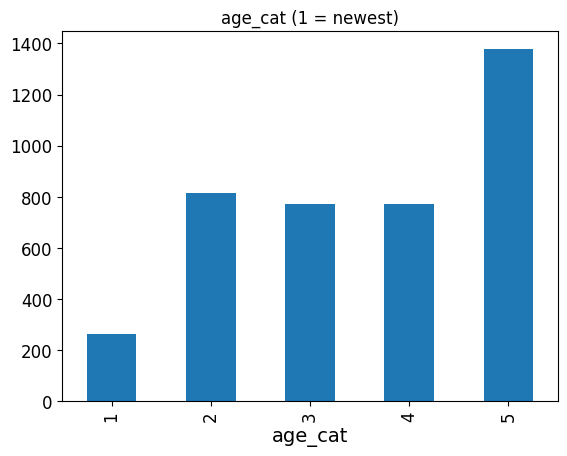

Test set proportions:
 age_cat
1    0.065
2    0.204
3    0.193
4    0.193
5    0.345
Name: count, dtype: float64

Full data proportions:
 age_cat
1    0.0655
2    0.2040
3    0.1928
4    0.1932
5    0.3445
Name: count, dtype: float64


In [ ]:
cars["age_cat"] = pd.cut(2026 - cars["year"], bins=[0, 2, 5, 8, 11, np.inf], labels=[1, 2, 3, 4, 5])
cars["age_cat"].value_counts().sort_index().plot(kind="bar", title="age_cat (1 = newest)")
plt.show()

split = StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=7)
for train_index, test_index in split.split(cars, cars["age_cat"]):
    strat_train_set = cars.loc[train_index]
    strat_test_set = cars.loc[test_index]

print("Test set proportions:\n", (strat_test_set["age_cat"].value_counts() / len(strat_test_set)).sort_index().round(4))
print("\nFull data proportions:\n", (cars["age_cat"].value_counts() / len(cars)).sort_index().round(4))

for set_ in (strat_train_set, strat_test_set):
    set_.drop("age_cat", axis=1, inplace=True)

### Step A3: Discover and visualise the data to gain insights

> **Code explained:** Scatter plot of year vs km driven, coloured by price and sized by engine size, on a copy of the training data. A copy keeps the original safe from changes.

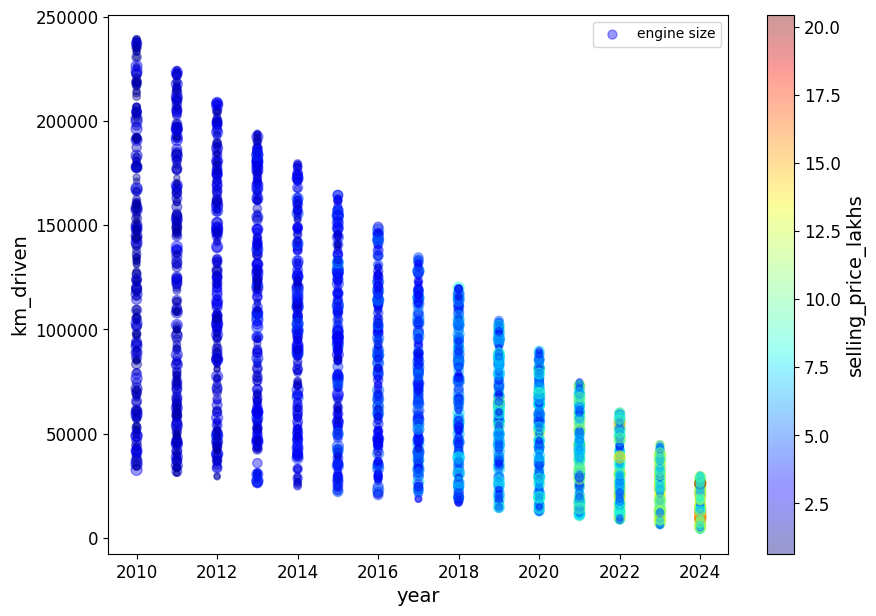

In [ ]:
cars_explore = strat_train_set.copy()

cars_explore.plot(kind="scatter", x="year", y="km_driven", alpha=0.4,
                  s=cars_explore["engine_cc"] / 40, label="engine size",
                  c="selling_price_lakhs", cmap=plt.get_cmap("jet"), colorbar=True, figsize=(10, 7))
plt.legend()
plt.show()

> **Code explained:** Computes the correlation of every numeric column with the price. It ranks which features matter most.

In [ ]:
corr_matrix = cars_explore.select_dtypes(include=[np.number]).drop(columns="car_id").corr()
corr_matrix["selling_price_lakhs"].sort_values(ascending=False)

,selling_price_lakhs
selling_price_lakhs,1.000000
year,0.798553
max_power_bhp,0.418855
engine_cc,0.417259
seats,0.009939
owner_count,-0.094119
km_driven,-0.551587


> **Code explained:** A scatter matrix of price against power, year and km. It shows relationships between several variables at once.

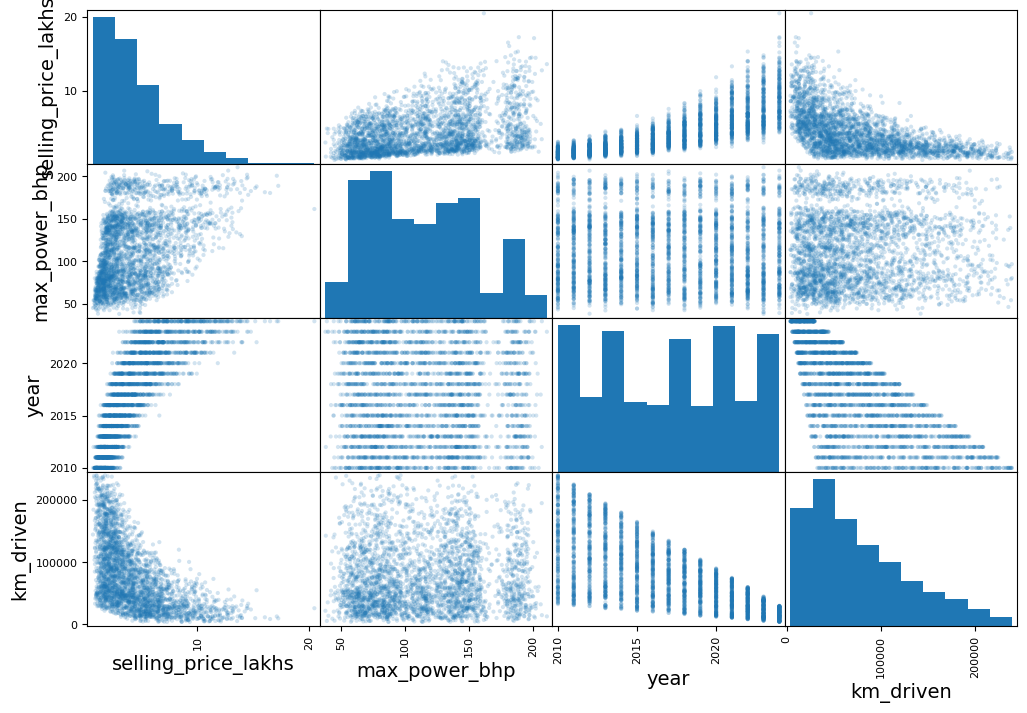

In [ ]:
from pandas.plotting import scatter_matrix
attributes = ["selling_price_lakhs", "max_power_bhp", "year", "km_driven"]
scatter_matrix(cars_explore[attributes], figsize=(12, 8), alpha=0.2)
plt.show()

**Experimenting with attribute combinations.** Total kilometres alone mixes up "old car" and "heavily used car". Kilometres **per year** separates the two. Power per litre of engine is another candidate.

> **Code explained:** Tests new combined features: car age, km per year and power per litre. Checking correlation tells us whether the new attribute is more useful than the raw ones.

In [ ]:
cars_explore["car_age"] = 2026 - cars_explore["year"]
cars_explore["km_per_year"] = cars_explore["km_driven"] / cars_explore["car_age"]
cars_explore["power_per_litre"] = cars_explore["max_power_bhp"] / (cars_explore["engine_cc"] / 1000)

corr_matrix = cars_explore.select_dtypes(include=[np.number]).drop(columns="car_id").corr()
corr_matrix["selling_price_lakhs"].sort_values(ascending=False)

,selling_price_lakhs
selling_price_lakhs,1.000000
year,0.798553
max_power_bhp,0.418855
engine_cc,0.417259
power_per_litre,0.067806
seats,0.009939
km_per_year,-0.012322
owner_count,-0.094119
km_driven,-0.551587
car_age,-0.798553


### Step A4: Prepare the data for ML algorithms

> **Code explained:** Separates features (`cars_X`) from the label (`cars_labels`), dropping the id, and counts missing values in each column.

In [ ]:
cars_X = strat_train_set.drop(["selling_price_lakhs", "car_id"], axis=1)
cars_labels = strat_train_set["selling_price_lakhs"].copy()

# Data cleaning: max_power_bhp has missing values
print("Missing values per column:\n", cars_X.isna().sum())

Missing values per column:
 year              0
km_driven         0
engine_cc         0
max_power_bhp    54
seats             0
owner_count       0
fuel_type         0
transmission      0
dtype: int64


> **Code explained:** Fills missing values with the **median** using `SimpleImputer`. We fit it, compare its stored medians to pandas medians, transform the data, and confirm that no gaps remain.

In [ ]:
cars_num = cars_X.drop(["fuel_type", "transmission"], axis=1)

imputer = SimpleImputer(strategy="median")
imputer.fit(cars_num)
print("imputer.statistics_:", imputer.statistics_)
print("median values      :", cars_num.median().values)

X = imputer.transform(cars_num)
cars_tr = pd.DataFrame(X, columns=cars_num.columns, index=cars_num.index)
print("Missing after imputing:", int(cars_tr.isna().sum().sum()))

imputer.statistics_: [2.01700e+03 6.23415e+04 1.50000e+03 1.10100e+02 5.00000e+00 1.00000e+00]
median values      : [2.01700e+03 6.23415e+04 1.50000e+03 1.10100e+02 5.00000e+00 1.00000e+00]
Missing after imputing: 0


**Handling categorical attributes**

> **Code explained:** Shows two ways of encoding text: `OrdinalEncoder` (codes 0,1,2) and `OneHotEncoder` (one 0/1 column per category). One-hot is safer when categories have no natural order.

In [ ]:
cars_cat = cars_X[["fuel_type", "transmission"]]

ordinal_encoder = OrdinalEncoder()
print("Ordinal encoded:\n", ordinal_encoder.fit_transform(cars_cat)[:5])
print(ordinal_encoder.categories_)

cat_encoder = OneHotEncoder()
cars_cat_1hot = cat_encoder.fit_transform(cars_cat)
print("\nOne-hot encoded (sparse -> dense):\n", cars_cat_1hot.toarray()[:5])
print(cat_encoder.get_feature_names_out())

Ordinal encoded:
 [[2. 1.]
 [2. 1.]
 [1. 1.]
 [2. 1.]
 [2. 0.]]
[array(['CNG', 'Diesel', 'Petrol'], dtype=object), array(['Automatic', 'Manual'], dtype=object)]

One-hot encoded (sparse -> dense):
 [[0. 0. 1. 0. 1.]
 [0. 0. 1. 0. 1.]
 [0. 1. 0. 0. 1.]
 [0. 0. 1. 0. 1.]
 [0. 0. 1. 1. 0.]]
['fuel_type_CNG' 'fuel_type_Diesel' 'fuel_type_Petrol'
 'transmission_Automatic' 'transmission_Manual']


**Custom transformer** that adds our combined attributes (`car_age`, `km_per_year`, and optionally `power_per_litre`).

> **Code explained:** A **custom transformer** class that adds `car_age`, `km_per_year` and optionally `power_per_litre`. Following the `fit/transform` pattern lets it plug into a scikit-learn pipeline.

In [ ]:
# column positions inside cars_num: year, km_driven, engine_cc, max_power_bhp, seats, owner_count
year_ix, km_ix, engine_ix, power_ix = 0, 1, 2, 3

class UsedCarFeatureAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_power_per_litre=True):
        self.add_power_per_litre = add_power_per_litre

    def fit(self, X, y=None):
        return self  # nothing to learn

    def transform(self, X, y=None):
        car_age = 2026 - X[:, year_ix]
        km_per_year = X[:, km_ix] / car_age
        if self.add_power_per_litre:
            power_per_litre = X[:, power_ix] / (X[:, engine_ix] / 1000)
            return np.c_[X, car_age, km_per_year, power_per_litre]
        return np.c_[X, car_age, km_per_year]

attr_adder = UsedCarFeatureAdder(add_power_per_litre=False)
print(attr_adder.transform(cars_tr.values)[:3].round(1))

[[2.01500e+03 1.32055e+05 1.50000e+03 9.96000e+01 5.00000e+00 1.00000e+00
  1.10000e+01 1.20050e+04]
 [2.01900e+03 4.42050e+04 2.50000e+03 1.75500e+02 5.00000e+00 1.00000e+00
  7.00000e+00 6.31500e+03]
 [2.01100e+03 2.24820e+05 8.00000e+02 5.13000e+01 5.00000e+00 2.00000e+00
  1.50000e+01 1.49880e+04]]


**Transformation pipelines**

> **Code explained:** Builds the full preprocessing: a numeric pipeline (impute → add attributes → scale with `RobustScaler`) and a `ColumnTransformer` that also one-hot encodes the text columns. One call prepares all the data.

In [ ]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("attribs_adder", UsedCarFeatureAdder()),
    ("robust_scaler", RobustScaler()),
])

num_attribs = list(cars_num)
cat_attribs = ["fuel_type", "transmission"]

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(), cat_attribs),
])

cars_prepared = full_pipeline.fit_transform(cars_X)
print("Prepared shape:", cars_prepared.shape)
print(cars_prepared[:3].round(2))

Prepared shape: (3000, 14)
[[-0.25  0.92  0.   -0.16  0.    0.    0.25  0.53 -1.21  0.    0.    1.
   0.    1.  ]
 [ 0.25 -0.24  1.    0.98  0.    0.   -0.25 -0.32 -0.67  0.    0.    1.
   0.    1.  ]
 [-0.75  2.14 -0.7  -0.89  0.    1.    0.75  0.97 -1.53  0.    1.    0.
   0.    1.  ]]


### Step A5: Select and train models

> **Code explained:** Trains a `LinearRegression` on the prepared data, predicts on five rows and prints the training RMSE (average error in lakhs).

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(cars_prepared, cars_labels)

some_data = cars_X.iloc[:5]
some_labels = cars_labels.iloc[:5]
print("Predictions:", lin_reg.predict(full_pipeline.transform(some_data)).round(2))
print("Labels:     ", list(some_labels))

lin_rmse = np.sqrt(mean_squared_error(cars_labels, lin_reg.predict(cars_prepared)))
print("\nLinear Regression training RMSE (lakhs):", round(lin_rmse, 3))

Predictions: [ 2.96  7.42 -0.53  4.17  8.63]
Labels:      [2.79, 6.28, 0.97, 3.87, 11.35]

Linear Regression training RMSE (lakhs): 1.091


> **Code explained:** Trains a `DecisionTreeRegressor` and checks its training RMSE. A value near 0 means it memorised the training data.

In [ ]:
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(cars_prepared, cars_labels)
tree_rmse = np.sqrt(mean_squared_error(cars_labels, tree_reg.predict(cars_prepared)))
print("Decision Tree training RMSE:", tree_rmse)

Decision Tree training RMSE: 7.021666937153402e-18


Training error of 0 means the tree has memorised the training data. **K-fold cross-validation** gives an honest estimate.

> **Code explained:** Uses 5-fold **cross-validation** to get honest RMSE scores for the tree and for linear regression. `display_scores` prints the fold scores, mean and std.

In [ ]:
scores = cross_val_score(tree_reg, cars_prepared, cars_labels, scoring="neg_mean_squared_error", cv=5)
print("Decision Tree")
display_scores(np.sqrt(-scores))

lin_scores = cross_val_score(lin_reg, cars_prepared, cars_labels, scoring="neg_mean_squared_error", cv=5)
print("\nLinear Regression")
display_scores(np.sqrt(-lin_scores))

Decision Tree
Scores: [1.029 0.966 1.029 1.03  1.08 ]
Mean: 1.027
Standard Deviation: 0.036

Linear Regression
Scores: [1.042 1.06  1.1   1.114 1.155]
Mean: 1.094
Standard Deviation: 0.04


> **Code explained:** Trains a `RandomForestRegressor` (many trees averaged) and shows its training RMSE and its cross-validated RMSE.

In [ ]:
forest_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
forest_reg.fit(cars_prepared, cars_labels)
print("Random Forest training RMSE:", round(np.sqrt(mean_squared_error(cars_labels, forest_reg.predict(cars_prepared))), 3))

forest_scores = cross_val_score(forest_reg, cars_prepared, cars_labels, scoring="neg_mean_squared_error", cv=5)
print("\nRandom Forest")
display_scores(np.sqrt(-forest_scores))

Random Forest training RMSE: 0.283

Random Forest
Scores: [0.716 0.675 0.742 0.794 0.831]
Mean: 0.752
Standard Deviation: 0.055


### Step A6: Fine-tune with Grid Search and evaluate on the test set
We search over a small grid of Random Forest settings and then test the best one on data it has never seen.

> **Code explained:** `GridSearchCV` tries every combination of `n_estimators` and `max_features` with 5-fold CV and prints the RMSE for each, plus the best combination.

In [ ]:
param_grid = {"n_estimators": [50, 150], "max_features": [3, 5, 8]}
grid_search = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), param_grid, cv=5,
                           scoring="neg_mean_squared_error", return_train_score=True)
grid_search.fit(cars_prepared, cars_labels)

print("Best parameters:", grid_search.best_params_)
cvres = grid_search.cv_results_
for mean_score, params in zip(cvres["mean_test_score"], cvres["params"]):
    print(round(np.sqrt(-mean_score), 4), params)

Best parameters: {'max_features': 5, 'n_estimators': 150}
0.7467 {'max_features': 3, 'n_estimators': 50}
0.736 {'max_features': 3, 'n_estimators': 150}
0.737 {'max_features': 5, 'n_estimators': 50}
0.7323 {'max_features': 5, 'n_estimators': 150}
0.741 {'max_features': 8, 'n_estimators': 50}
0.7435 {'max_features': 8, 'n_estimators': 150}


> **Code explained:** Lists the importance of each feature in the best forest. This shows which columns (including our new ones) drive the price.

In [ ]:
feature_names = num_attribs + ["car_age", "km_per_year", "power_per_litre"] + \
                list(full_pipeline.named_transformers_["cat"].get_feature_names_out(cat_attribs))
importances = grid_search.best_estimator_.feature_importances_
sorted(zip(importances.round(3), feature_names), reverse=True)

[(np.float64(0.316), 'year'),
 (np.float64(0.3), 'car_age'),
 (np.float64(0.138), 'max_power_bhp'),
 (np.float64(0.101), 'engine_cc'),
 (np.float64(0.083), 'km_driven'),
 (np.float64(0.018), 'power_per_litre'),
 (np.float64(0.017), 'km_per_year'),
 (np.float64(0.007), 'owner_count'),
 (np.float64(0.005), 'transmission_Manual'),
 (np.float64(0.005), 'transmission_Automatic'),
 (np.float64(0.005), 'fuel_type_Diesel'),
 (np.float64(0.002), 'seats'),
 (np.float64(0.002), 'fuel_type_Petrol'),
 (np.float64(0.002), 'fuel_type_CNG')]

> **Code explained:** The final exam: transforms the **test set** with the already-fitted pipeline (`transform` only, never `fit`) and prints the test RMSE and R² of the tuned forest.

In [ ]:
final_model = grid_search.best_estimator_

X_test = strat_test_set.drop(["selling_price_lakhs", "car_id"], axis=1)
y_test = strat_test_set["selling_price_lakhs"].copy()
X_test_prepared = full_pipeline.transform(X_test)      # transform only, never fit on the test set!
final_predictions = final_model.predict(X_test_prepared)

final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
print(f"Final test RMSE: {final_rmse:.3f} lakhs")
print(f"Final test R2  : {r2_score(y_test, final_predictions):.3f}")

Final test RMSE: 0.733 lakhs
Final test R2  : 0.933


### Does the model beat a 'dumb' baseline?
A **baseline** always predicts the same value (the training mean). It costs nothing to build and tells us how much real skill our model has.

> **Code explained:** `DummyRegressor(strategy="mean")` is trained like any other model and scored on the same test set. We then compute by what percentage our tuned forest lowers the RMSE compared with it.

In [ ]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean").fit(cars_prepared, cars_labels)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline.predict(X_test_prepared)))
improvement = 100 * (baseline_rmse - final_rmse) / baseline_rmse

print(f"Baseline (always predict the mean) RMSE : {baseline_rmse:.3f} lakhs")
print(f"Tuned Random Forest RMSE                : {final_rmse:.3f} lakhs")
print(f"\nConclusion: our model reduces the error by {improvement:.0f}% compared with the baseline.")

Baseline (always predict the mean) RMSE : 2.832 lakhs
Tuned Random Forest RMSE                : 0.733 lakhs

Conclusion: our model reduces the error by 74% compared with the baseline.


**Conclusion:** the tuned model's error is far below the baseline's, so it has learned real patterns (age, power, mileage...) and is not just guessing the average price.

---
# Project B — Pune Flat Price Prediction

**Problem Statement:** Predict the sale price (₹ lakhs) of a flat in Pune from its area, bedrooms, bathrooms, building age, floor, distance to the nearest station, locality and parking availability.

### Step B0: Generate the dataset and save it as CSV

> **Code explained:** Generates 3,500 fake Pune flats (price depends on area, locality rate, age, floor, distance to station, parking) with some missing values, and saves them to CSV.

In [ ]:
np.random.seed(77)
n = 3500

localities = ["Kothrud", "Baner", "Viman Nagar", "Wakad", "Hinjewadi", "Hadapsar"]
rates = [13500, 12500, 12000, 8800, 7800, 8200]

locality = np.random.choice(localities, n)
bedrooms = np.random.choice([1, 2, 3, 4], n)

area_sqft = (bedrooms * np.random.normal(420, 50, n) + 180).clip(350).round()
bathrooms = (bedrooms + np.random.choice([-1, 0, 0, 1], n)).clip(1, 5)

building_age = np.random.randint(0, 31, n)
total_floors = np.random.choice([4, 7, 12, 18, 25], n)
floor = np.random.randint(0, 25, n)

dist_station_km = np.random.gamma(2, 1.4, n).round(2)
parking = np.random.choice(["Yes", "No"], n)

base_rate = np.array([rates[localities.index(l)] for l in locality])

price = area_sqft * base_rate / 100000
price = price * (1 - 0.008 * building_age)
price = price * (1 + 0.004 * floor)
price = price * np.where(parking == "Yes", 1.05, 1)
price = price * np.exp(np.random.normal(0, 0.10, n))

flats = pd.DataFrame({
    "area_sqft": area_sqft,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms.astype(float),
    "building_age": building_age,
    "floor": floor,
    "total_floors": total_floors,
    "dist_station_km": dist_station_km,
    "locality": locality,
    "parking": parking,
    "price_lakhs": price.round(2)
})

flats.loc[np.random.choice(n, 100, replace=False), "bathrooms"] = np.nan
flats.loc[np.random.choice(n, 70, replace=False), "dist_station_km"] = np.nan

flats.to_csv("datasets/pune_flats.csv", index=False)

print(flats.head())

   area_sqft  bedrooms  bathrooms  building_age  floor  total_floors  \
0      996.0         2        2.0            10     14             7   
1     1025.0         2        2.0            28     14             4   
2      563.0         1        1.0            12     18             7   
3     1184.0         3        4.0             0     10            25   
4     2104.0         4        4.0            19     14             7   

   dist_station_km   locality parking  price_lakhs  
0             3.70  Hinjewadi     Yes        70.02  
1             4.73  Hinjewadi     Yes        73.77  
2             3.35      Wakad     Yes        50.29  
3             2.37   Hadapsar      No        99.37  
4             0.96    Kothrud      No       228.78  


### Step B1: Load and take a quick look

> **Code explained:** Loads the flats CSV and shows the first rows.

In [ ]:
flats = pd.read_csv("datasets/pune_flats.csv")
flats.head()

,area_sqft,bedrooms,bathrooms,building_age,floor,total_floors,dist_station_km,locality,parking,price_lakhs
0,996.0,2,2.0,10,14,7,3.70,Hinjewadi,Yes,70.02
1,1025.0,2,2.0,28,14,4,4.73,Hinjewadi,Yes,73.77
2,563.0,1,1.0,12,18,7,3.35,Wakad,Yes,50.29
3,1184.0,3,4.0,0,10,25,2.37,Hadapsar,No,99.37
4,2104.0,4,4.0,19,14,7,0.96,Kothrud,No,228.78


> **Code explained:** `info()` for the flats data: column types and missing values.

In [ ]:
flats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   area_sqft        3500 non-null   float64
 1   bedrooms         3500 non-null   int64  
 2   bathrooms        3400 non-null   float64
 3   building_age     3500 non-null   int64  
 4   floor            3500 non-null   int64  
 5   total_floors     3500 non-null   int64  
 6   dist_station_km  3430 non-null   float64
 7   locality         3500 non-null   object 
 8   parking          3500 non-null   object 
 9   price_lakhs      3500 non-null   float64
dtypes: float64(4), int64(4), object(2)
memory usage: 273.6+ KB


> **Code explained:** Counts localities and parking values and prints numeric summary statistics in one go.

In [ ]:
print(flats["locality"].value_counts(), "\n")
print(flats["parking"].value_counts())
flats.describe().round(2)

locality
Hinjewadi      660
Viman Nagar    600
Kothrud        583
Hadapsar       564
Baner          556
Wakad          537
Name: count, dtype: int64 

parking
Yes    1791
No     1709
Name: count, dtype: int64


,area_sqft,bedrooms,bathrooms,building_age,floor,total_floors,dist_station_km,price_lakhs
count,3500.00,3500.00,3400.00,3500.00,3500.00,3500.00,3430.00,3500.00
mean,1225.99,2.49,2.57,14.91,11.78,13.07,2.80,121.68
std,491.14,1.12,1.23,8.97,7.22,7.50,1.95,60.19
min,435.00,1.00,1.00,0.00,0.00,4.00,0.01,27.37
25%,715.75,1.00,2.00,7.00,6.00,7.00,1.35,74.32
50%,1182.50,2.00,2.50,15.00,12.00,12.00,2.37,111.72
75%,1612.25,3.00,4.00,23.00,18.00,18.00,3.80,157.91
max,2559.00,4.00,5.00,30.00,24.00,25.00,17.77,393.44


> **Code explained:** Histograms of all numeric columns of the flats data.

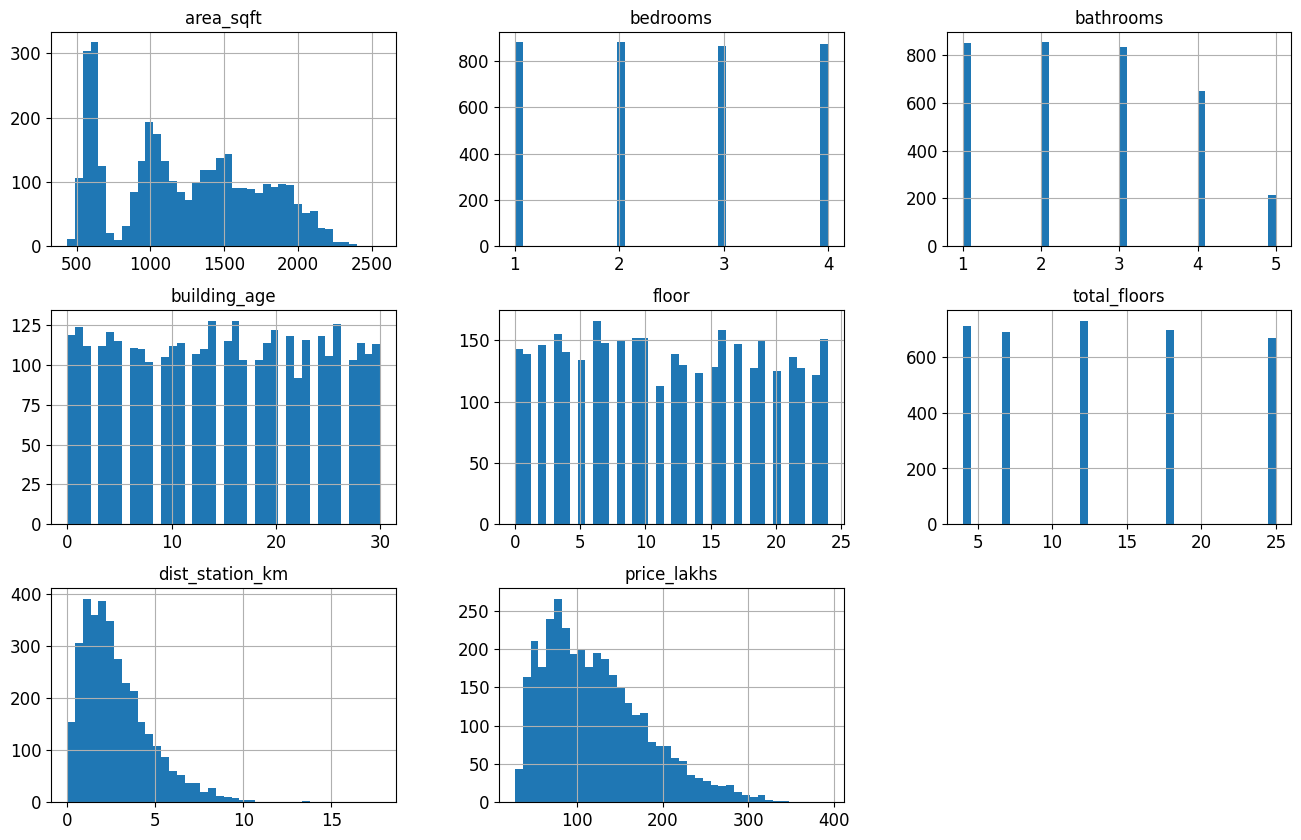

In [ ]:
flats.hist(bins=40, figsize=(16, 10))
plt.show()

### Step B2: Test set generation — random vs stratified (sampling-bias table)
Area is the strongest driver of price, so we stratify on an **area category** and compare how well each method preserves the true proportions.

> **Code explained:** Creates an `area_cat` column and compares **random vs stratified** test sets with a table that shows the percentage error of each against the true proportions. Stratified should be closer.

In [ ]:
flats["area_cat"] = pd.cut(flats["area_sqft"], bins=[0, 550, 800, 1100, 1500, np.inf], labels=[1, 2, 3, 4, 5])

random_train, random_test = train_test_split(flats, test_size=0.2, random_state=11)
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=11)
for train_index, test_index in split.split(flats, flats["area_cat"]):
    strat_train_set = flats.loc[train_index]
    strat_test_set = flats.loc[test_index]

def cat_proportions(data):
    return data["area_cat"].value_counts().sort_index() / len(data)

compare = pd.DataFrame({"Overall": cat_proportions(flats),
                        "Random": cat_proportions(random_test),
                        "Stratified": cat_proportions(strat_test_set)})
compare["Random %error"] = 100 * compare["Random"] / compare["Overall"] - 100
compare["Strat. %error"] = 100 * compare["Stratified"] / compare["Overall"] - 100
compare.round(3)

,Overall,Random,Stratified,Random %error,Strat. %error
area_cat,,,,,
1,0.043,0.053,0.043,22.517,-0.662
2,0.211,0.211,0.211,0.000,0.000
3,0.199,0.200,0.200,0.430,0.430
4,0.229,0.194,0.229,-15.106,-0.125
5,0.317,0.341,0.317,7.561,-0.090


> **Code explained:** Removes the helper `area_cat` column from both sets since it is no longer needed.

In [ ]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("area_cat", axis=1, inplace=True)

### Step B3: Discover and visualise the data

> **Code explained:** Scatter plot of price vs area coloured by building age. Shows the main trend and the effect of age.

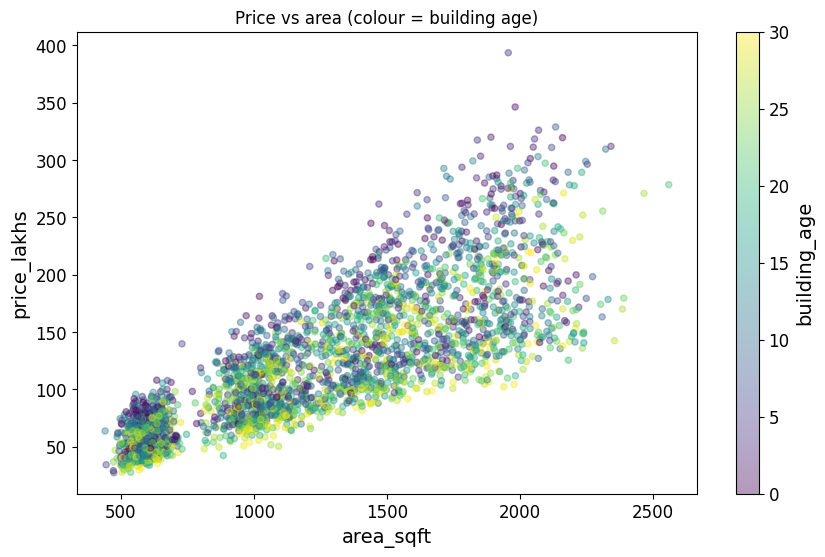

In [ ]:
flats_explore = strat_train_set.copy()
flats_explore.plot(kind="scatter", x="area_sqft", y="price_lakhs", alpha=0.4,
                   c="building_age", cmap=plt.get_cmap("viridis"), colorbar=True, figsize=(10, 6))
plt.title("Price vs area (colour = building age)")
plt.show()

> **Code explained:** Computes the median price per sq.ft for each locality and draws a bar chart. This reveals how strongly the location matters.

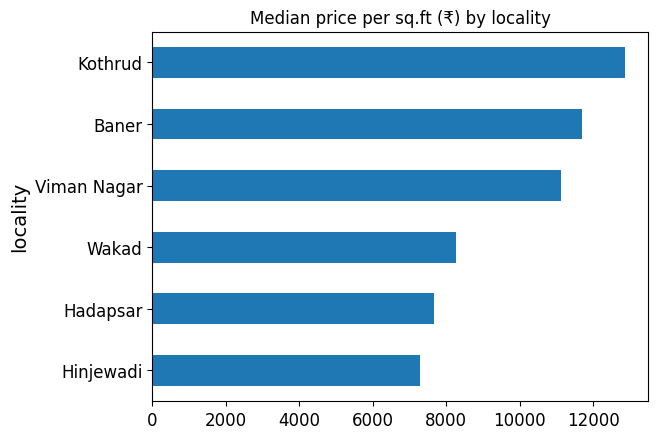

In [ ]:
(flats_explore.assign(rate=flats_explore["price_lakhs"] * 1e5 / flats_explore["area_sqft"])
 .groupby("locality")["rate"].median().sort_values()
 .plot(kind="barh", title="Median price per sq.ft (₹) by locality"))
plt.show()

> **Code explained:** Builds ratio features (area per bedroom, floor ratio, bathrooms per bedroom) and checks their correlation with price.

In [ ]:
flats_explore["area_per_bedroom"] = flats_explore["area_sqft"] / flats_explore["bedrooms"]
flats_explore["floor_ratio"] = flats_explore["floor"] / flats_explore["total_floors"]
flats_explore["bath_per_bed"] = flats_explore["bathrooms"] / flats_explore["bedrooms"]

corr_matrix = flats_explore.select_dtypes(include=[np.number]).corr()
corr_matrix["price_lakhs"].sort_values(ascending=False)

,price_lakhs
price_lakhs,1.000000
area_sqft,0.815583
bedrooms,0.789477
bathrooms,0.664951
floor,0.067711
floor_ratio,0.059064
dist_station_km,-0.000970
total_floors,-0.020084
building_age,-0.163944
bath_per_bed,-0.201455


### Step B4: Prepare the data

> **Code explained:** Splits features and labels for the flats, separates the numeric columns and counts the missing values.

In [ ]:
flats_X = strat_train_set.drop("price_lakhs", axis=1)
flats_labels = strat_train_set["price_lakhs"].copy()
flats_num = flats_X.drop(["locality", "parking"], axis=1)
print("Missing values:\n", flats_X.isna().sum())

Missing values:
 area_sqft           0
bedrooms            0
bathrooms          75
building_age        0
floor               0
total_floors        0
dist_station_km    56
locality            0
parking             0
dtype: int64


> **Code explained:** A second custom transformer, `FlatAttributesAdder`, that adds the three ratio features. The comments list the column positions it relies on.

In [ ]:
# column positions inside flats_num:
# area_sqft, bedrooms, bathrooms, building_age, floor, total_floors, dist_station_km
area_ix, bed_ix, bath_ix, floor_ix, total_floor_ix = 0, 1, 2, 4, 5

class FlatAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_bath_per_bed=True):
        self.add_bath_per_bed = add_bath_per_bed

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        area_per_bedroom = X[:, area_ix] / X[:, bed_ix]
        floor_ratio = X[:, floor_ix] / X[:, total_floor_ix]
        if self.add_bath_per_bed:
            bath_per_bed = X[:, bath_ix] / X[:, bed_ix]
            return np.c_[X, area_per_bedroom, floor_ratio, bath_per_bed]
        return np.c_[X, area_per_bedroom, floor_ratio]

**Variation:** three branches in one `ColumnTransformer`:
- numeric columns → impute (median) → add attributes → **MinMax** scaling
- `locality` (no natural order) → **One-Hot** encoding
- `parking` (binary No/Yes) → **Ordinal** encoding (No = 0, Yes = 1 is meaningful here)

> **Code explained:** One `ColumnTransformer` with three branches: numeric (impute → add features → `MinMaxScaler`), `locality` (one-hot) and `parking` (ordinal No=0/Yes=1). It prints the final shape and feature names.

In [ ]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("attribs_adder", FlatAttributesAdder()),
    ("minmax_scaler", MinMaxScaler()),
])

num_attribs = list(flats_num)
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("locality", OneHotEncoder(), ["locality"]),
    ("parking", OrdinalEncoder(categories=[["No", "Yes"]]), ["parking"]),
])

flats_prepared = full_pipeline.fit_transform(flats_X)
print("Prepared shape:", flats_prepared.shape)
flat_feature_names = (num_attribs + ["area_per_bedroom", "floor_ratio", "bath_per_bed"]
                      + list(full_pipeline.named_transformers_["locality"].get_feature_names_out())
                      + ["parking"])
print(flat_feature_names)
print(flats_prepared[:2].round(2))

Prepared shape: (2800, 17)
['area_sqft', 'bedrooms', 'bathrooms', 'building_age', 'floor', 'total_floors', 'dist_station_km', 'area_per_bedroom', 'floor_ratio', 'bath_per_bed', 'locality_Baner', 'locality_Hadapsar', 'locality_Hinjewadi', 'locality_Kothrud', 'locality_Viman Nagar', 'locality_Wakad', 'parking']
[[0.27 0.33 0.   0.87 0.58 1.   0.08 0.48 0.09 0.   1.   0.   0.   0.
  0.   0.   1.  ]
 [0.04 0.   0.   0.07 0.88 1.   0.09 0.54 0.14 0.33 0.   0.   0.   1.
  0.   0.   1.  ]]


### Step B5: Train and compare models with 5-fold cross-validation

> **Code explained:** Trains four models (Linear, Decision Tree, Random Forest, Gradient Boosting), measures training RMSE and 5-fold CV RMSE for each, and puts everything in a sorted table.

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, random_state=42),
}
rows = []
for name, model in models.items():
    model.fit(flats_prepared, flats_labels)
    train_rmse = np.sqrt(mean_squared_error(flats_labels, model.predict(flats_prepared)))
    cv_rmse = np.sqrt(-cross_val_score(model, flats_prepared, flats_labels,
                                       scoring="neg_mean_squared_error", cv=5))
    rows.append([name, train_rmse, cv_rmse.mean(), cv_rmse.std()])

results = pd.DataFrame(rows, columns=["Model", "Train RMSE", "CV RMSE (mean)", "CV RMSE (std)"]).round(3)
results.sort_values("CV RMSE (mean)")

,Model,Train RMSE,CV RMSE (mean),CV RMSE (std)
3,Gradient Boosting,12.313,15.008,0.494
2,Random Forest,5.987,15.972,0.754
0,Linear Regression,18.597,18.727,0.954
1,Decision Tree,0.000,21.638,1.046


**Reading the table:** compare *Train RMSE* with *CV RMSE*.
- A model with a tiny train error but a much larger CV error is **overfitting** (typically the single Decision Tree).
- A model with similar train and CV error but a higher overall error is **underfitting** (typically Linear Regression, because price depends on area × locality rate, a multiplicative effect).
- The ensembles (Random Forest, Gradient Boosting) usually give the lowest CV error.

### Step B6: Evaluate the best model on the test set

> **Code explained:** Picks the model with the lowest CV RMSE, evaluates it on the test set (RMSE and R²) and plots predicted vs actual price. Points near the red line mean good predictions.

Best model: Gradient Boosting
Test RMSE : 15.051 lakhs
Test R2   : 0.937


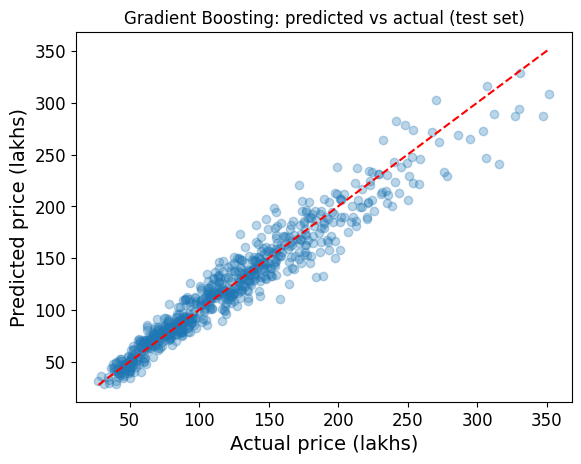

In [ ]:
best_name = results.sort_values("CV RMSE (mean)").iloc[0]["Model"]
final_model = models[best_name]

X_test = strat_test_set.drop("price_lakhs", axis=1)
y_test = strat_test_set["price_lakhs"].copy()
final_predictions = final_model.predict(full_pipeline.transform(X_test))

print(f"Best model: {best_name}")
print(f"Test RMSE : {np.sqrt(mean_squared_error(y_test, final_predictions)):.3f} lakhs")
print(f"Test R2   : {r2_score(y_test, final_predictions):.3f}")

plt.scatter(y_test, final_predictions, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price (lakhs)")
plt.ylabel("Predicted price (lakhs)")
plt.title(f"{best_name}: predicted vs actual (test set)")
plt.show()

> **Code explained:** Predicts the price of one new flat listing by running it through the same fitted pipeline and model.

In [ ]:
# Predict the price of a new listing
new_flat = pd.DataFrame([{"area_sqft": 950, "bedrooms": 2, "bathrooms": 2, "building_age": 8, "floor": 5,
                          "total_floors": 7, "dist_station_km": 2.4, "locality": "Wakad", "parking": "Yes"}])
print(f"Predicted price: ₹{final_model.predict(full_pipeline.transform(new_flat))[0]:.1f} lakhs")

Predicted price: ₹83.5 lakhs


---
## Lab 3 summary — the steps of an end-to-end ML project, applied twice
| Step | Project A (used cars) | Project B (Pune flats) |
|---|---|---|
| Split | hash on `car_id` + stratified on age | random vs stratified on area (bias table) |
| Explore | year × km scatter coloured by price | price vs area, rate by locality |
| New attributes | `car_age`, `km_per_year`, `power_per_litre` | `area_per_bedroom`, `floor_ratio`, `bath_per_bed` |
| Clean | median imputer | median imputer |
| Encode | One-Hot | One-Hot + Ordinal |
| Scale | RobustScaler | MinMaxScaler |
| Models | LR, DT, RF (5-fold CV) + Grid Search | LR, DT, RF, GBR (5-fold CV) |
| Final | test RMSE / R² + baseline comparison | test RMSE / R² + new-listing prediction |

---

# Lab 4 — Hyper-Parameter Tuning for k-NN (`GridSearchCV` + `Pipeline`)

Hyper-parameters (k, weights, distance power...) are *not* learned from data — we have to choose them. **Grid Search** tries every combination with cross-validation and keeps the best one.

| | Part A | Part B |
|---|---|---|
| Task | Classification | Regression |
| Data | Handwritten Digits (8×8 images, 64 features) | Synthetic **credit-limit** data (features on very different scales) |
| Tuned | scaler, PCA components, k, weights, p | scaler, k, weights, p |
| Scoring | accuracy | R² and RMSE |

**Our own addition (end of lab):** a **model comparison** — the tuned k-NN against a tuned **Decision Tree** on the credit-limit data.

> **Code explained:** Imports `time` to measure search time, the search tools (`GridSearchCV`, `RandomizedSearchCV`, `ParameterGrid`), both k-NN models, three scalers, PCA, `Pipeline` and metrics.

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, ParameterGrid
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, classification_report, ConfusionMatrixDisplay,
                             r2_score, mean_squared_error)

---
# Part A — Tuning a k-NN Classifier on Handwritten Digits

### Step A1: Load and look at the data

> **Code explained:** Loads the Digits dataset (1,797 images of 8×8 pixels = 64 features) and displays the first ten digits to get a feel for the data.

X shape: (1797, 64) | classes: [0 1 2 3 4 5 6 7 8 9]


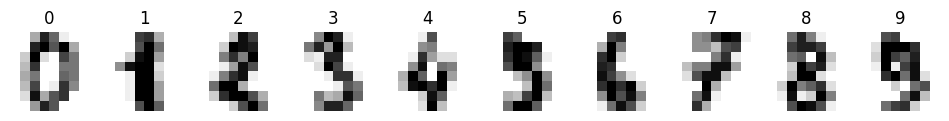

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
X, y = digits.data, digits.target
print("X shape:", X.shape, "| classes:", np.unique(y))

fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.imshow(image, cmap=plt.cm.gray_r)
    ax.set_title(label)
    ax.axis("off")
plt.show()

> **Code explained:** Splits into 70% train and 30% test (stratified) and prints the square-root-of-N rule of thumb for k — only a starting point, not a final answer.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=7)
N = len(X_train)
print(f"Training samples N = {N}")
print(f"Rule of thumb starting point: k = sqrt(N) = {np.sqrt(N):.1f}")

Training samples N = 1257
Rule of thumb starting point: k = sqrt(N) = 35.5


### Step A2: Build the pipeline and the hyper-parameter grid
Scaling → PCA → k-NN. Grid Search tries the **Cartesian product** of all values.

All 64 pixel features are already on the same 0–16 scale, so we let Grid Search decide whether a scaler helps at all (`"passthrough"` skips the step).

> **Code explained:** Builds a **pipeline** (scaler → PCA → k-NN) and a **parameter grid**. Names like `knn__n_neighbors` mean 'parameter of the step called knn'. The scaler itself is also tuned, and `"passthrough"` means 'skip this step'. It prints how many combinations and fits will be run.

In [ ]:
# 1. Pipeline: scaling + dimensionality reduction + k-NN
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(random_state=42)),
    ("knn", KNeighborsClassifier()),
])

# 2. Hyper-parameter grid
param_grid = {
    "scaler": [StandardScaler(), MinMaxScaler(), "passthrough"],  # "passthrough" = skip this step
    "pca__n_components": [15, 25, 40],
    "knn__n_neighbors": list(range(1, 14, 2)),   # odd numbers 1..15 to avoid ties
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],                            # 1 = Manhattan, 2 = Euclidean
}

n_combinations = len(ParameterGrid(param_grid))
cv = 5
print(f"Combinations = 3 x 3 x 7 x 2 x 2 = {n_combinations}")
print(f"Model fits with {cv}-fold CV = {n_combinations} x {cv} = {n_combinations * cv} (+1 final refit)")

Combinations = 3 x 3 x 7 x 2 x 2 = 252
Model fits with 5-fold CV = 252 x 5 = 1260 (+1 final refit)


### Step A3: Run Grid Search with 5-fold cross-validation

> **Code explained:** Runs `GridSearchCV` with 5-fold CV on all combinations (`n_jobs=-1` uses all CPU cores). It prints the time taken, the best parameters and the best CV accuracy.

In [ ]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=cv,
                           scoring="accuracy", n_jobs=-1, return_train_score=True)
start = time.time()
grid_search.fit(X_train, y_train)
print(f"Search time: {time.time() - start:.1f} s")

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

Search time: 65.4 s
Best Parameters: {'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'uniform', 'pca__n_components': 40, 'scaler': 'passthrough'}
Best Cross-Validation Score: 0.9865


> **Code explained:** Puts `cv_results_` in a DataFrame and shows the top 10 combinations. Comparing train and CV scores also reveals overfitting.

In [ ]:
results = pd.DataFrame(grid_search.cv_results_)
results["scaler"] = results["param_scaler"].apply(lambda s: type(s).__name__ if s != "passthrough" else "none")
cols = ["scaler", "param_pca__n_components", "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
        "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
results[cols].sort_values("rank_test_score").head(10)

,scaler,param_pca__n_components,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_train_score,mean_test_score,std_test_score,rank_test_score
62,none,40,3,uniform,2,0.990852,0.986476,0.001944,1
71,none,40,3,distance,2,1.000000,0.985686,0.005375,2
61,MinMaxScaler,40,3,uniform,2,0.990255,0.985683,0.003167,3
70,MinMaxScaler,40,3,distance,2,1.000000,0.984892,0.006818,4
106,MinMaxScaler,40,5,distance,2,1.000000,0.983299,0.005821,5
89,none,40,5,distance,1,1.000000,0.983299,0.004625,5
59,none,25,3,uniform,2,0.989857,0.983299,0.005821,5
107,none,40,5,distance,2,1.000000,0.983295,0.003880,8
58,MinMaxScaler,25,3,uniform,2,0.990056,0.982508,0.009242,9
53,none,40,3,distance,1,1.000000,0.982508,0.005360,9


### Step A4: Visualise the effect of k (bias-variance trade-off)
We fix PCA components and `p` at their best values and plot CV accuracy against k for both weighting schemes.

> **Code explained:** Fixes the best scaler, PCA size and p, then plots CV accuracy against k for both weighting schemes (plus training accuracy). It shows the bias–variance trade-off of k.

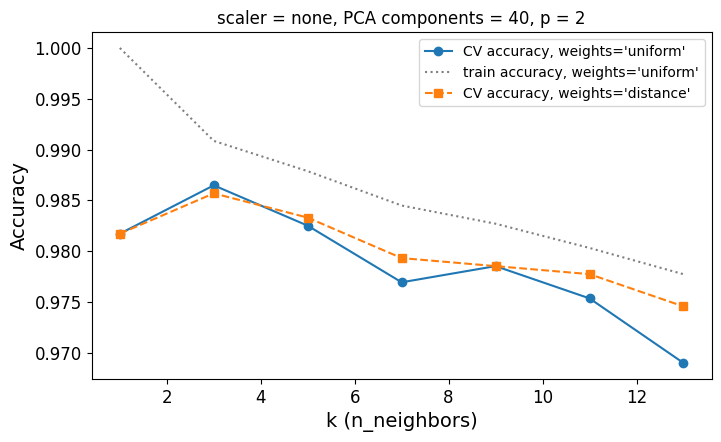

In [ ]:
best = grid_search.best_params_
best_scaler = "none" if best["scaler"] == "passthrough" else type(best["scaler"]).__name__
subset = results[(results["scaler"] == best_scaler) &
                 (results["param_pca__n_components"] == best["pca__n_components"]) &
                 (results["param_knn__p"] == best["knn__p"])]

fig, ax = plt.subplots(figsize=(8, 4.5))
for w, style in [("uniform", "o-"), ("distance", "s--")]:
    s = subset[subset["param_knn__weights"] == w].sort_values("param_knn__n_neighbors")
    ax.plot(s["param_knn__n_neighbors"], s["mean_test_score"], style, label=f"CV accuracy, weights='{w}'")
    if w == "uniform":
        ax.plot(s["param_knn__n_neighbors"], s["mean_train_score"], ":", color="gray",
                label="train accuracy, weights='uniform'")
ax.set_xlabel("k (n_neighbors)")
ax.set_ylabel("Accuracy")
ax.set_title(f"scaler = {best_scaler}, PCA components = {best['pca__n_components']}, p = {best['knn__p']}")
ax.legend()
plt.show()

**Observations**
- k = 1 gives training accuracy 1.0 (each point is its own neighbour) — the high-variance end of the trade-off.
- The rule of thumb k = √N is only a starting point; compare it with the k that cross-validation chose in `best_params_` above.
- With `weights='distance'` the training accuracy is always 1.0, so only the CV score is meaningful.

### Step A5: Evaluate the refitted best model on the test set
`GridSearchCV` automatically refits the best pipeline on the **whole training set** (`best_estimator_`).

> **Code explained:** Takes the refitted best pipeline (`best_estimator_`), predicts on the test set and prints test accuracy and a per-class report.

In [ ]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred))

Test accuracy: 0.9907

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        54
           1       1.00      1.00      1.00        55
           2       1.00      1.00      1.00        53
           3       0.96      1.00      0.98        55
           4       1.00      1.00      1.00        54
           5       0.98      0.98      0.98        55
           6       0.98      1.00      0.99        54
           7       1.00      1.00      1.00        54
           8       0.98      1.00      0.99        52
           9       1.00      0.93      0.96        54

    accuracy                           0.99       540
   macro avg       0.99      0.99      0.99       540
weighted avg       0.99      0.99      0.99       540



> **Code explained:** Draws the confusion matrix on the test set — which digits get mixed up.

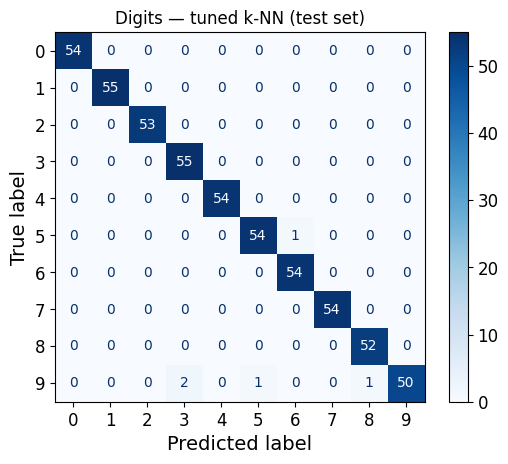

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Digits — tuned k-NN (test set)")
plt.show()

> **Code explained:** Trains a plain default k-NN (no scaling, no PCA) as a **baseline** and compares its test accuracy with the tuned pipeline.

In [ ]:
# Baseline: untuned k-NN (default k=5, no scaling, no PCA) for comparison
baseline = KNeighborsClassifier().fit(X_train, y_train)
print(f"Untuned k-NN test accuracy: {baseline.score(X_test, y_test):.4f}")
print(f"Tuned pipeline test accuracy: {best_model.score(X_test, y_test):.4f}")

Untuned k-NN test accuracy: 0.9889
Tuned pipeline test accuracy: 0.9907


**What did tuning tell us here?**
- Look at which scaler `best_params_` picked. All pixels share one scale, so scaling often brings little here; it matters much more when features have *different* units (see Part B).
- Compare the tuned and the untuned test accuracy above. On an easy dataset like this the default k-NN is already close, and a difference of one or two images is just noise. The real benefit of tuning is a trustworthy CV estimate and a more compact model (PCA components instead of 64 raw pixels).

---
# Part B — Tuning a k-NN Regressor on Credit-Limit Data

**Problem Statement:** A bank wants to predict the credit-card limit (₹) to offer a customer from their **age**, **annual income (₹)**, **credit score** (300–900) and **number of existing loans**. Income is in lakhs of rupees while loans are 0–5, so the scale problem is obvious.

### Step B1: Generate the data

> **Code explained:** Generates the credit-limit dataset: age, income (in lakhs of ₹), credit score and number of loans, with the limit depending on all of them plus noise. `describe()` shows how different the scales are.

In [ ]:
rng = np.random.default_rng(8)
n = 1200
age = rng.integers(21, 65, n)
annual_income = rng.lognormal(mean=np.log(800000), sigma=0.45, size=n).round(-3)
credit_score = rng.normal(720, 60, n).clip(300, 900).round()
existing_loans = rng.poisson(1.2, n)

credit_limit = (0.25 * annual_income * (credit_score / 750) ** 3
                * (1 - 0.08 * existing_loans).clip(0.4)
                * (1 + 0.004 * (age - 21))
                * np.exp(rng.normal(0, 0.12, n))).round(-3)

credit = pd.DataFrame({"age": age, "annual_income": annual_income, "credit_score": credit_score,
                       "existing_loans": existing_loans, "credit_limit": credit_limit})
credit.describe().round(1)

,age,annual_income,credit_score,existing_loans,credit_limit
count,1200.0,1200.0,1200.0,1200.0,1200.0
mean,42.4,873106.7,719.8,1.2,193619.2
std,12.5,429409.8,61.1,1.1,115256.8
min,21.0,198000.0,541.0,0.0,24000.0
25%,32.0,575000.0,678.0,0.0,116000.0
50%,42.0,785500.0,719.0,1.0,165500.0
75%,53.0,1068000.0,762.0,2.0,241000.0
max,64.0,3314000.0,900.0,7.0,910000.0


> **Code explained:** Splits features and target into train and test sets (75/25).

In [ ]:
X = credit.drop(columns="credit_limit")
y = credit["credit_limit"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=3)

### Step B2: Why scaling is critical for k-NN

> **Code explained:** Trains k-NN (k=5) on raw features and on scaled features and compares test R². This proves that distance-based models need scaling when features have very different units.

In [ ]:
unscaled = KNeighborsRegressor(n_neighbors=5).fit(X_train, y_train)
scaled = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=5))]).fit(X_train, y_train)

print(f"k=5 WITHOUT scaling: test R2 = {unscaled.score(X_test, y_test):.3f}")
print(f"k=5 WITH scaling   : test R2 = {scaled.score(X_test, y_test):.3f}")

k=5 WITHOUT scaling: test R2 = 0.657
k=5 WITH scaling   : test R2 = 0.883


Without scaling, the distance is almost entirely the difference in `annual_income` (values like 8,00,000), so credit score, age and loans are ignored.

### Step B3: Grid Search — the scaler is also a hyper-parameter
For regression, k can be even or odd (no voting ties). We score with **two metrics** and refit using R².

> **Code explained:** A grid search for the regressor in which the **scaler is a hyper-parameter** (Standard, MinMax or Robust). It scores two metrics (R² and RMSE) at once, and `refit="r2"` says which metric picks the final model.

In [ ]:
reg_pipeline = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])

reg_param_grid = {
    "scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()],
    "knn__n_neighbors": list(range(1, 26)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
n_comb = len(ParameterGrid(reg_param_grid))
print(f"Combinations = 3 x 25 x 2 x 2 = {n_comb} -> {n_comb * 5} fits")

reg_search = GridSearchCV(reg_pipeline, reg_param_grid, cv=5, n_jobs=-1,
                          scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"},
                          refit="r2")
start = time.time()
reg_search.fit(X_train, y_train)
grid_time = time.time() - start

print(f"Search time: {grid_time:.1f} s")
print(f"Best Parameters: {reg_search.best_params_}")
print(f"Best CV R2: {reg_search.best_score_:.4f}")
best_idx = reg_search.best_index_
print(f"CV RMSE of that model: ₹{-reg_search.cv_results_['mean_test_rmse'][best_idx]:,.0f}")

Combinations = 3 x 25 x 2 x 2 = 300 -> 1500 fits
Search time: 17.5 s
Best Parameters: {'knn__n_neighbors': 6, 'knn__p': 2, 'knn__weights': 'distance', 'scaler': RobustScaler()}
Best CV R2: 0.9002
CV RMSE of that model: ₹35,835


> **Code explained:** Plots the validation curve (mean CV R² vs k) for each scaler and weighting scheme, so we can see how the choice of scaler and weights changes the curve.

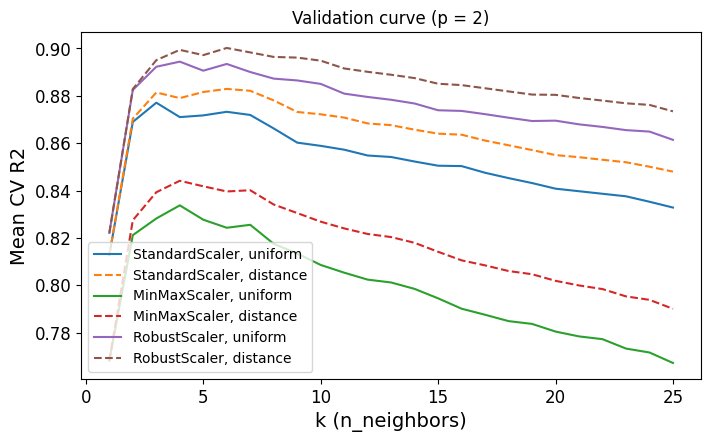

In [ ]:
reg_results = pd.DataFrame(reg_search.cv_results_)
reg_results["scaler_name"] = reg_results["param_scaler"].apply(lambda s: type(s).__name__)
bp = reg_search.best_params_

fig, ax = plt.subplots(figsize=(8, 4.5))
for scaler_name in ["StandardScaler", "MinMaxScaler", "RobustScaler"]:
    for w, style in [("uniform", "-"), ("distance", "--")]:
        s = reg_results[(reg_results["scaler_name"] == scaler_name) &
                        (reg_results["param_knn__weights"] == w) &
                        (reg_results["param_knn__p"] == bp["knn__p"])].sort_values("param_knn__n_neighbors")
        ax.plot(s["param_knn__n_neighbors"], s["mean_test_r2"], style, label=f"{scaler_name}, {w}")
ax.set_xlabel("k (n_neighbors)")
ax.set_ylabel("Mean CV R2")
ax.set_title(f"Validation curve (p = {bp['knn__p']})")
ax.legend()
plt.show()

### Step B4: Randomized Search — a cheaper alternative
Grid Search has limitations: its cost grows exponentially with the number of hyper-parameters, and it can only test the values you list. `RandomizedSearchCV` samples a fixed number of random combinations from **distributions**, so k can be any integer in a range.

> **Code explained:** **Randomized search** tries only 25 random combinations (k can be any integer in a range). It is much cheaper than the grid and usually gets close to the best result.

In [ ]:
from scipy.stats import randint

rand_search = RandomizedSearchCV(
    reg_pipeline,
    param_distributions={"scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()],
                         "knn__n_neighbors": randint(1, 31),
                         "knn__weights": ["uniform", "distance"],
                         "knn__p": [1, 2]},
    n_iter=25, cv=5, scoring="r2", random_state=5, n_jobs=-1)
start = time.time()
rand_search.fit(X_train, y_train)
print(f"Randomized search: {25 * 5} fits in {time.time() - start:.1f} s (grid search: {n_comb * 5} fits in {grid_time:.1f} s)")
print(f"Best params: {rand_search.best_params_}")
print(f"Best CV R2 : {rand_search.best_score_:.4f}  (grid search: {reg_search.best_score_:.4f})")

Randomized search: 125 fits in 1.2 s (grid search: 1500 fits in 17.5 s)
Best params: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance', 'scaler': RobustScaler()}
Best CV R2 : 0.8914  (grid search: 0.9002)


### Step B5: Final evaluation and a prediction

> **Code explained:** Evaluates the best grid-search model on the test set (R² and RMSE in ₹) and predicts a limit for a new customer.

In [ ]:
final_reg = reg_search.best_estimator_
pred = final_reg.predict(X_test)
print(f"Test R2  : {r2_score(y_test, pred):.4f}")
print(f"Test RMSE: ₹{np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

new_customer = pd.DataFrame([{"age": 35, "annual_income": 950000, "credit_score": 740, "existing_loans": 2}])
print(f"\nSuggested credit limit for the new customer: ₹{final_reg.predict(new_customer)[0]:,.0f}")

Test R2  : 0.9047
Test RMSE: ₹36,591

Suggested credit limit for the new customer: ₹196,970


### Tuned k-NN vs tuned Decision Tree



I compare two very different models on the same credit-limit data, giving each a fair chance by tuning both with Grid Search.

> **Code explained:** A grid search over `max_depth` and `min_samples_leaf` tunes the tree (trees need no scaling). We then put the tuned k-NN and the tuned tree side by side with their CV R², test R² and test RMSE. The last lines print which model wins.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

tree_search = GridSearchCV(DecisionTreeRegressor(random_state=0),
                           {"max_depth": [3, 5, 7, 9, 12, None], "min_samples_leaf": [1, 5, 10, 20]},
                           cv=5, scoring="r2", n_jobs=-1)
tree_search.fit(X_train, y_train)
tree_pred = tree_search.best_estimator_.predict(X_test)

compare_models = pd.DataFrame({
    "Model": ["Tuned k-NN", "Tuned Decision Tree"],
    "CV R2": [reg_search.best_score_, tree_search.best_score_],
    "Test R2": [r2_score(y_test, pred), r2_score(y_test, tree_pred)],
    "Test RMSE (Rs)": [np.sqrt(mean_squared_error(y_test, pred)), np.sqrt(mean_squared_error(y_test, tree_pred))],
}).round(3)
print(compare_models.to_string(index=False))
print("Best tree parameters:", tree_search.best_params_)

winner = compare_models.sort_values("Test R2", ascending=False).iloc[0]
print(f"\nConclusion: {winner['Model']} has the higher test R2 ({winner['Test R2']}).")

              Model  CV R2  Test R2  Test RMSE (Rs)
         Tuned k-NN  0.900    0.905       36590.983
Tuned Decision Tree  0.846    0.878       41461.719
Best tree parameters: {'max_depth': 12, 'min_samples_leaf': 5}

Conclusion: Tuned k-NN has the higher test R2 (0.905).


**Conclusion:** the table shows which model generalises better on this data. A distance-based model (k-NN) depends on good scaling, while a tree splits on one feature at a time and doesn't care about scale — so the winner here is a trade-off between smoothness (k-NN) and simplicity (tree).

---
## Lab 4 summary
| | Part A (Digits) | Part B (Credit limit) |
|---|---|---|
| Problem | classification (10 classes) | regression |
| Grid size | 252 combinations × 5 folds | 300 combinations × 5 folds |
| Extra preprocessing | scaler on/off + PCA | scaler choice tuned (3 scalers) |
| k values | odd only (avoid voting ties) | any k (prediction is an average) |
| Scoring | accuracy | R² (refit) + RMSE |
| Our addition | — | tuned k-NN vs tuned Decision Tree |

---

# Lab 5 — Decision Tree Classification with Graphviz

A decision tree asks a series of yes/no questions about the features (e.g. `credit_score <= 700?`) and ends in a class. Graphviz lets us **draw** the learned tree.

| | Part A | Part B |
|---|---|---|
| Data | Wine (real, 3 classes, 13 features) | Synthetic **loan-approval** data (2 classes, 6 features) |
| Impurity measure | `entropy` | `gini` |
| Control of tree size | `max_depth` | `max_depth` + `min_samples_leaf` |

**Our own addition (end of lab):** a **gini vs entropy** comparison on the loan data, tested with cross-validation for tree depths 2 to 7.

## Step 1: Verify that the Graphviz package is installed correctly
(`view=False` so that no external window pops up; the graph is displayed inline instead.)

> **Code explained:** Checks that the Graphviz Python package and the Graphviz program are installed by drawing and rendering a tiny two-node graph. If this prints 'Verification successful', drawing trees will work.

Verification successful! The graph has been rendered to test-output/round-trip.gv.png


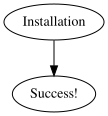

In [ ]:
import graphviz

dot = graphviz.Digraph(comment="Test Graph")
dot.node("A", "Installation")
dot.node("B", "Success!")
dot.edge("A", "B")

try:
    dot.render("test-output/round-trip.gv", view=False, format="png")
    print("Verification successful! The graph has been rendered to test-output/round-trip.gv.png")
except Exception as e:
    print(f"Verification failed: {e}")
dot

> **Code explained:** Imports NumPy, Pandas, Matplotlib, the Graphviz `Source` class, the decision-tree tools (`export_graphviz`, `export_text`), the splitter and accuracy metric.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from graphviz import Source
from sklearn.tree import DecisionTreeClassifier, export_graphviz, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

---
# Part A — Wine Cultivar Classification

## Step A2: Load the Wine dataset and check the feature names and target class values

> **Code explained:** Loads the Wine dataset and prints its feature names, class names and shape.

In [ ]:
from sklearn.datasets import load_wine

wine = load_wine()
print(f"Feature Names: {wine['feature_names']}")
print(f"Target Class Values: {wine['target_names']}")
print(f"Data shape: {wine.data.shape}")

Feature Names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target Class Values: ['class_0' 'class_1' 'class_2']
Data shape: (178, 13)


## Step A3: Train Decision Tree Classifiers
We train trees of increasing depth (all using **entropy** as the impurity measure) and compare them with a fully grown tree.

> **Code explained:** Splits into train/test and trains trees with depth 1, 2, 3, 4 and unlimited (all using `entropy`). The table compares depth, number of leaves and train/test accuracy to show how depth affects overfitting.

In [ ]:
X = wine.data
y = wine.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=3)

rows = []
for depth in [1, 2, 3, 4, None]:
    model = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": "None (full)" if depth is None else depth,
                 "actual depth": model.get_depth(), "leaves": model.get_n_leaves(),
                 "train acc": round(model.score(X_train, y_train), 3),
                 "test acc": round(model.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,max_depth,actual depth,leaves,train acc,test acc
0,1,1,2,0.617,0.556
1,2,2,4,0.977,0.911
2,3,3,5,1.000,0.933
3,4,3,5,1.000,0.933
4,None (full),3,5,1.000,0.933


Look at the *test acc* column: a shallow tree is often almost as accurate as the fully grown tree, while being much easier to read. (With only about 45 test wines, one wrong prediction changes accuracy by ~0.02, so small differences are noise.) We visualise the **depth-3** tree.

> **Code explained:** Trains the tree we will draw: `max_depth=3` with entropy. A shallow tree is easy to read.

In [ ]:
tree_clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=42)
tree_clf.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

## Step A4: Visualise the learnt Decision Tree using Graphviz

> **Code explained:** Writes the tree to a `.dot` file with `export_graphviz` (coloured, rounded nodes with feature and class names) and displays it with `Source.from_file`.

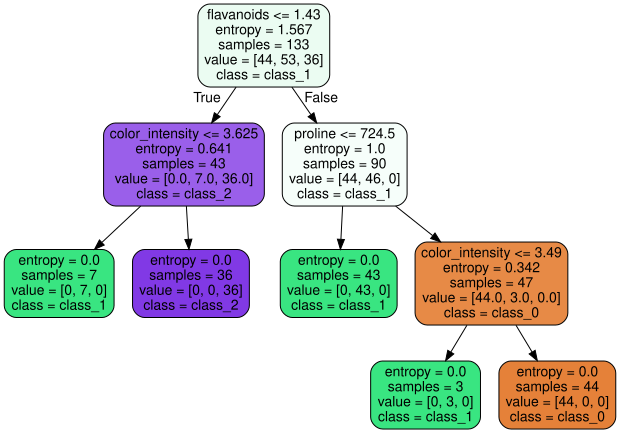

In [ ]:
export_graphviz(
    tree_clf,
    out_file="wine_tree_d3.dot",
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    rounded=True,
    filled=True,
)
Source.from_file("wine_tree_d3.dot")

**How to read a node:** the test (e.g. `feature <= value` at the root), the **entropy** of the node (0 = pure), the number of `samples` reaching it, the `value` = samples per class, and the majority `class`.

## Step A5: Which features matter?

> **Code explained:** Plots which features the tree used most (`feature_importances_`), keeping only non-zero ones.

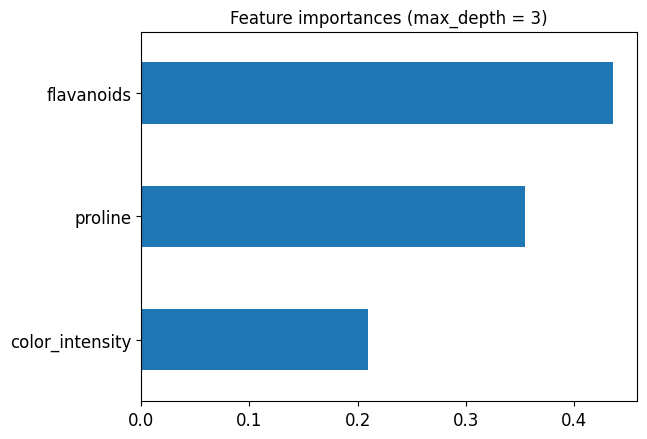

In [ ]:
importances = pd.Series(tree_clf.feature_importances_, index=wine.feature_names).sort_values()
importances[importances > 0].plot(kind="barh", title="Feature importances (max_depth = 3)")
plt.show()

> **Code explained:** Predicts the class of a new wine and shows `predict_proba`, which for a tree is just the class share inside the leaf where the sample lands.

In [ ]:
# Predict a new wine and show the class probabilities (= class share in the leaf it falls into)
new_wine = [[13.2, 3.0, 2.4, 21.0, 100, 1.5, 0.8, 0.45, 1.2, 7.0, 0.7, 1.7, 700]]
print("Predicted class :", wine.target_names[tree_clf.predict(new_wine)[0]])
probs = tree_clf.predict_proba(new_wine)[0]
print("Probabilities   :", {str(c): round(float(p), 3) for c, p in zip(wine.target_names, probs)})

Predicted class : class_2
Probabilities   : {'class_0': 0.0, 'class_1': 0.0, 'class_2': 1.0}


---
# Part B — Loan Approval (synthetic)

A bank approves a loan using (roughly) these hidden rules, with 5% of decisions flipped as noise:
- credit score ≥ 720 **and** loan-to-income ratio ≤ 2.5, **or**
- credit score ≥ 680 **and** ≥ 4 years of employment **and** loan-to-income ≤ 1.2,
- and never if the applicant already has 3 EMIs running.

Can a decision tree rediscover these rules from data?

## Step B2: Create the dataset and check the feature names and target class values

> **Code explained:** Generates 1,500 loan applicants and approves them using hidden rules (credit score, loan-to-income, years of employment, EMIs), flipping 5% of the decisions as noise. It also adds an **engineered feature**, `loan_to_income`. The question: can a tree rediscover the rules?

In [ ]:
rng = np.random.default_rng(9)
n = 1500
loans = pd.DataFrame({
    "credit_score": rng.integers(550, 851, n),
    "annual_income_lakhs": rng.uniform(3, 30, n).round(1),
    "loan_amount_lakhs": rng.uniform(1, 60, n).round(1),
    "employment_years": rng.integers(0, 21, n),
    "existing_emis": rng.integers(0, 4, n),
})
loans["loan_to_income"] = (loans["loan_amount_lakhs"] / loans["annual_income_lakhs"]).round(2)  # engineered feature

lti = loans["loan_to_income"]
approved = (((loans["credit_score"] >= 720) & (lti <= 2.5)) |
            ((loans["credit_score"] >= 680) & (loans["employment_years"] >= 4) & (lti <= 1.2)))
approved &= loans["existing_emis"] < 3
noise = rng.random(n) < 0.05
loans["approved"] = np.where(noise, ~approved, approved).astype(int)

feature_names = list(loans.columns[:-1])
class_names = ["Rejected", "Approved"]
print(f"Feature Names: {feature_names}")
print(f"Target Class Values: {class_names}")
print(loans["approved"].value_counts().rename({0: "Rejected", 1: "Approved"}))
loans.head()

Feature Names: ['credit_score', 'annual_income_lakhs', 'loan_amount_lakhs', 'employment_years', 'existing_emis', 'loan_to_income']
Target Class Values: ['Rejected', 'Approved']
approved
Rejected    1107
Approved     393
Name: count, dtype: int64


,credit_score,annual_income_lakhs,loan_amount_lakhs,employment_years,existing_emis,loan_to_income,approved
0,676,23.8,20.5,18,0,0.86,0
1,811,23.9,49.2,5,0,2.06,1
2,839,8.3,6.4,20,1,0.77,1
3,636,27.9,8.1,6,3,0.29,0
4,584,24.0,11.2,6,3,0.47,0


## Step B3: Train the Decision Tree Classifier (gini, pruned)

> **Code explained:** Trains a pruned tree (`max_depth=4`, `min_samples_leaf=20`) and an unrestricted tree and compares leaves, train accuracy and test accuracy. This shows overfitting versus pruning.

In [ ]:
X = loans[feature_names]
y = loans["approved"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=2)

loan_tree = DecisionTreeClassifier(criterion="gini", max_depth=4, min_samples_leaf=20, random_state=42)
loan_tree.fit(X_train, y_train)

full_loan_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print(f"Pruned tree      : leaves = {loan_tree.get_n_leaves():3d}, "
      f"train acc = {loan_tree.score(X_train, y_train):.3f}, test acc = {loan_tree.score(X_test, y_test):.3f}")
print(f"Unrestricted tree: leaves = {full_loan_tree.get_n_leaves():3d}, "
      f"train acc = {full_loan_tree.score(X_train, y_train):.3f}, test acc = {full_loan_tree.score(X_test, y_test):.3f}")

Pruned tree      : leaves =  14, train acc = 0.933, test acc = 0.936
Unrestricted tree: leaves = 107, train acc = 1.000, test acc = 0.878


The unrestricted tree reaches ~100% training accuracy by memorising the noisy labels (5% flipped), which usually costs it some test accuracy — classic overfitting. The pruned tree is smaller and normally generalises as well or better.

## Step B4: Visualise the tree with Graphviz and save it as PNG

> **Code explained:** Exports the pruned tree to a DOT string (`out_file=None`), renders it to a PNG file and displays it.

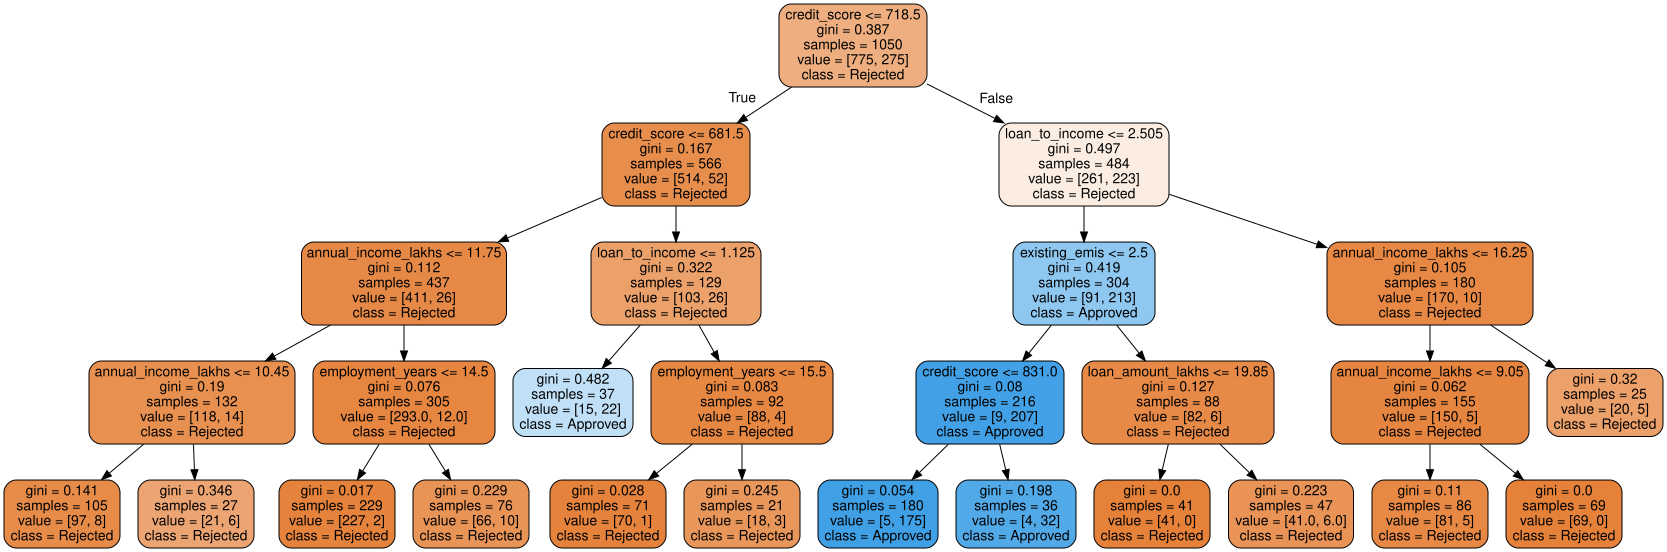

In [ ]:
dot_data = export_graphviz(
    loan_tree,
    out_file=None,              # return the DOT source as a string instead of writing a file
    feature_names=feature_names,
    class_names=class_names,
    rounded=True,
    filled=True,
    proportion=False,
)
loan_graph = Source(dot_data)
loan_graph.render("loan_tree_pruned", format="png", cleanup=True)   # -> loan_tree_pruned.png
loan_graph

## Step B5: The same tree as text rules

> **Code explained:** Prints the same tree as plain text rules with `export_text`, handy for reports.

In [ ]:
print(export_text(loan_tree, feature_names=feature_names, decimals=2))

|--- credit_score <= 718.50
|   |--- credit_score <= 681.50
|   |   |--- annual_income_lakhs <= 11.75
|   |   |   |--- annual_income_lakhs <= 10.45
|   |   |   |   |--- class: 0
|   |   |   |--- annual_income_lakhs >  10.45
|   |   |   |   |--- class: 0
|   |   |--- annual_income_lakhs >  11.75
|   |   |   |--- employment_years <= 14.50
|   |   |   |   |--- class: 0
|   |   |   |--- employment_years >  14.50
|   |   |   |   |--- class: 0
|   |--- credit_score >  681.50
|   |   |--- loan_to_income <= 1.12
|   |   |   |--- class: 1
|   |   |--- loan_to_income >  1.12
|   |   |   |--- employment_years <= 15.50
|   |   |   |   |--- class: 0
|   |   |   |--- employment_years >  15.50
|   |   |   |   |--- class: 0
|--- credit_score >  718.50
|   |--- loan_to_income <= 2.50
|   |   |--- existing_emis <= 2.50
|   |   |   |--- credit_score <= 831.00
|   |   |   |   |--- class: 1
|   |   |   |--- credit_score >  831.00
|   |   |   |   |--- class: 1
|   |   |--- existing_emis >  2.50
|   |   |   

The top splits should use `credit_score` and `loan_to_income` (and `existing_emis`), which mirrors the hidden approval rules. The engineered `loan_to_income` feature matters: one split on it replaces many splits on loan amount and income separately.

## Step B6: Decide on new applications

> **Code explained:** Creates a small table of new applicants (computing `loan_to_income` for them), and predicts the decision and the approval probability of each.

In [ ]:
applicants = pd.DataFrame([
    {"credit_score": 780, "annual_income_lakhs": 15.0, "loan_amount_lakhs": 30.0, "employment_years": 6, "existing_emis": 1},
    {"credit_score": 690, "annual_income_lakhs": 20.0, "loan_amount_lakhs": 20.0, "employment_years": 9, "existing_emis": 0},
    {"credit_score": 640, "annual_income_lakhs": 8.0,  "loan_amount_lakhs": 40.0, "employment_years": 2, "existing_emis": 3},
])
applicants["loan_to_income"] = (applicants["loan_amount_lakhs"] / applicants["annual_income_lakhs"]).round(2)

applicants["decision"] = [class_names[p] for p in loan_tree.predict(applicants[feature_names])]
applicants["P(approved)"] = loan_tree.predict_proba(applicants[feature_names])[:, 1].round(2)
applicants

,credit_score,annual_income_lakhs,loan_amount_lakhs,employment_years,existing_emis,loan_to_income,decision,P(approved)
0,780,15.0,30.0,6,1,2.0,Approved,0.97
1,690,20.0,20.0,9,0,1.0,Approved,0.59
2,640,8.0,40.0,2,3,5.0,Rejected,0.08


### Gini or Entropy?

Both are ways to measure how 'mixed' a node is. Does the choice change how good the tree is? We test both for several depths.

> **Code explained:** For depths 2 to 7 and for each criterion we run 5-fold cross-validation on the loan data and store the mean accuracy. The line plot compares the two criteria, and the last lines print the averages and the best depth.

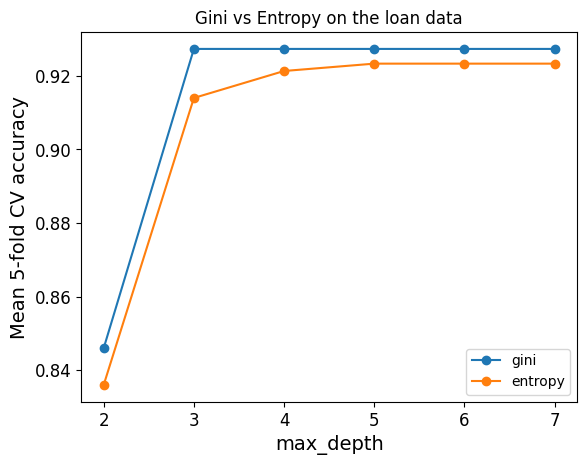

Average CV accuracy -> gini: 0.914 | entropy: 0.907

Conclusion: the best single result is 'gini' at depth 3 (0.927); the two criteria differ by only 0.007 on average.


In [ ]:
from sklearn.model_selection import cross_val_score

depth_range = range(2, 8)
cv_results = {"gini": [], "entropy": []}
for crit in cv_results:
    for d in depth_range:
        tree_cv = DecisionTreeClassifier(criterion=crit, max_depth=d, min_samples_leaf=20, random_state=0)
        cv_results[crit].append(cross_val_score(tree_cv, X, y, cv=5).mean())

for crit, scores in cv_results.items():
    plt.plot(list(depth_range), scores, marker="o", label=crit)
plt.xlabel("max_depth")
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("Gini vs Entropy on the loan data")
plt.legend()
plt.show()

avg = {c: float(np.mean(s)) for c, s in cv_results.items()}
best_c = max(cv_results, key=lambda c: max(cv_results[c]))
best_d = list(depth_range)[int(np.argmax(cv_results[best_c]))]
print(f"Average CV accuracy -> gini: {avg['gini']:.3f} | entropy: {avg['entropy']:.3f}")
print(f"\nConclusion: the best single result is '{best_c}' at depth {best_d} "
      f"({max(cv_results[best_c]):.3f}); the two criteria differ by only {abs(avg['gini'] - avg['entropy']):.3f} on average.")

**Conclusion:** gini and entropy give almost the same accuracy, and the curves follow the same shape. The **depth** of the tree matters much more than the criterion: too shallow underfits, too deep starts memorising the noise.

---
## Lab 5 summary
| | Part A (Wine) | Part B (Loans) |
|---|---|---|
| Classes | 3 cultivars | Rejected / Approved |
| Impurity | entropy | gini |
| Graphviz route | `export_graphviz(out_file="wine_tree_d3.dot")` → `Source.from_file` | `export_graphviz(out_file=None)` → `Source(...)` → `.render()` to PNG |
| Lesson | a shallow tree is readable and nearly as accurate | pruning stops the tree from memorising noisy labels |
| Our addition | — | gini vs entropy across depths 2–7 (cross-validated) |

---

# Lab 6 — Linear Regression vs Logistic Regression vs Decision Trees

Four mini-experiments, each done on a synthetic dataset (A) and a real one (B):

| Part | Dataset A (synthetic) | Dataset B (real, sklearn) |
|---|---|---|
| 1. Linear regression | $y = 0.5x + 1.2\sin(x) + \varepsilon$ | Diabetes: progression vs BMI |
| 2. Logistic regression | 2 overlapping Gaussian blobs | Breast cancer: mean perimeter & mean texture |
| 3. Decision-tree regression | same data as part 1 | same data as part 1 |
| 4. Decision-tree classification | 3-class synthetic data | Breast cancer (all 30 features) |

Every model is trained on 70% of the data, tuned/checked on 15% (validation) and finally tested on 15%.

**Our own addition (end of Part B2):** we try several values of the logistic-regression regularisation strength **C** and compare the errors.

> **Code explained:** Imports the libraries and defines three helpers: `split_70_15_15` (random train/validation/test indices), `misclassification_pct` (percentage of wrong predictions) and `plot_decision_boundary` (colours the plane by predicted class).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import graphviz
from sklearn import linear_model, datasets, tree
from sklearn.metrics import mean_squared_error
%matplotlib inline

def split_70_15_15(n, rng):
    # Return train / validation / test index arrays (70% / 15% / 15%)
    idx = rng.permutation(n)
    n_train, n_val = int(n * 0.7), int(n * 0.15)
    return idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]

def misclassification_pct(model, X, y):
    return 100 * np.mean(model.predict(X) != y)

def plot_decision_boundary(model, X, y, xlabel, ylabel, title, labels=("class 0", "class 1")):
    h_x = (X[:, 0].max() - X[:, 0].min()) / 300
    h_y = (X[:, 1].max() - X[:, 1].min()) / 300
    x_min, x_max = X[:, 0].min() - 20 * h_x, X[:, 0].max() + 20 * h_x
    y_min, y_max = X[:, 1].min() - 20 * h_y, X[:, 1].max() + 20 * h_y
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h_x), np.arange(y_min, y_max, h_y))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure()
    plt.pcolormesh(xx, yy, Z, cmap=plt.cm.Paired, shading="auto")
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c="red", edgecolors="k", label=labels[0])
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c="blue", edgecolors="k", label=labels[1])
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.show()

---
# Dataset A — Synthetic Data

## A1. Linear regression

### Prepare data
We use one input feature and generate

$$y = 0.5x + 1.2\sin(x) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, 0.5^2), \quad x \in [-2\pi, 2\pi]$$

> **Code explained:** Creates synthetic data $y = 0.5x + 1.2\sin(x) + \text{noise}$ and plots it. The sine part is something a straight line cannot capture.

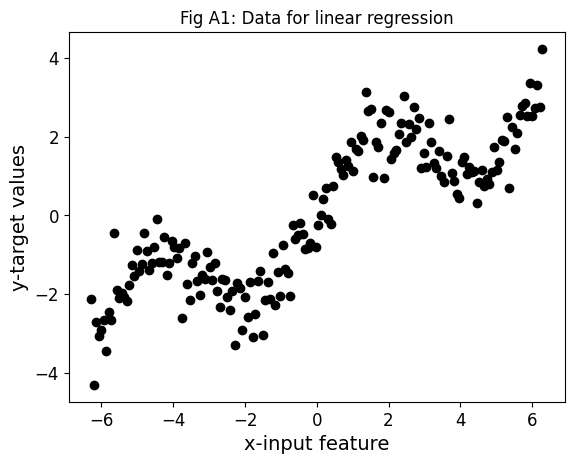

In [ ]:
rng = np.random.default_rng(3)
number_of_samples = 180
x = np.linspace(-2 * np.pi, 2 * np.pi, number_of_samples)
y = 0.5 * x + 1.2 * np.sin(x) + rng.normal(0, 0.5, x.shape)

plt.scatter(x, y, color="black")
plt.xlabel("x-input feature")
plt.ylabel("y-target values")
plt.title("Fig A1: Data for linear regression")
plt.show()

### Split into training (70%), validation (15%) and test (15%) sets

> **Code explained:** Splits the 180 points into train, validation and test sets. The validation set is for choosing settings, the test set only for the final check.

In [ ]:
train_idx, val_idx, test_idx = split_70_15_15(number_of_samples, rng)
reg_data_A = (x, y, train_idx, val_idx, test_idx)   # re-used in part A3
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]
print(f"train = {len(x_train)}, validation = {len(x_val)}, test = {len(x_test)}")

train = 125, validation = 27, test = 28


### Fit a line to the data
scikit-learn expects a 2-D feature matrix, so we reshape with `.reshape(-1, 1)` (instead of the deprecated `np.matrix`).

> **Code explained:** Fits a `LinearRegression` on the training set (reshaping x to 2-D, as scikit-learn requires), plots the line and prints slope and intercept.

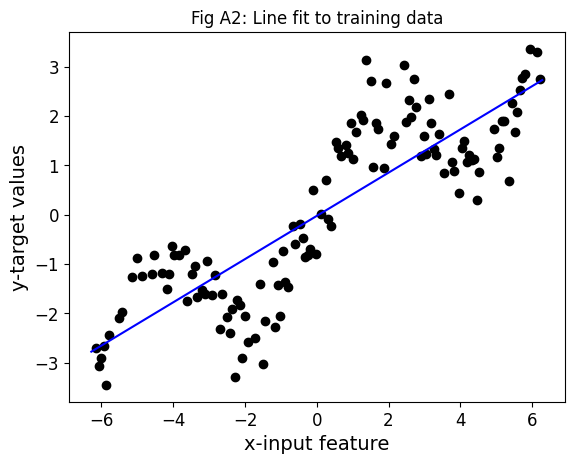

slope = 0.438, intercept = -0.025


In [ ]:
model = linear_model.LinearRegression()
model.fit(x_train.reshape(-1, 1), y_train)

plt.scatter(x_train, y_train, color="black")
plt.plot(x, model.predict(x.reshape(-1, 1)), color="blue")
plt.xlabel("x-input feature")
plt.ylabel("y-target values")
plt.title("Fig A2: Line fit to training data")
plt.show()
print(f"slope = {model.coef_[0]:.3f}, intercept = {model.intercept_:.3f}")

### Evaluate the model (MSE)

> **Code explained:** Computes validation and test MSE of the line. This is the number the decision tree must beat later.

In [ ]:
lin_val_mse_A = mean_squared_error(y_val, model.predict(x_val.reshape(-1, 1)))
lin_test_mse_A = mean_squared_error(y_test, model.predict(x_test.reshape(-1, 1)))
print("Validation MSE:", round(lin_val_mse_A, 4), "\nTest MSE:", round(lin_test_mse_A, 4))

Validation MSE: 0.8054 
Test MSE: 1.4601


The straight line captures the upward trend (0.5x) but misses the sine wave, so the MSE stays well above the noise level (0.5² = 0.25).

## A2. Logistic regression

### Prepare data
Two overlapping Gaussian blobs with 2 features.

> **Code explained:** Generates two overlapping blobs with `make_blobs`, splits them and plots the training points. They overlap on purpose, so perfect separation is impossible.

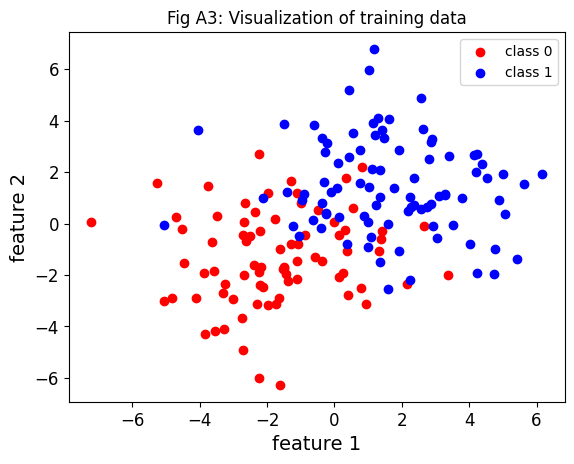

In [ ]:
X, Y = datasets.make_blobs(n_samples=240, centers=[(-1.5, -1.5), (1.5, 1.5)], cluster_std=2.0, random_state=5)
number_of_samples = len(Y)
train_idx, val_idx, test_idx = split_70_15_15(number_of_samples, rng)
x_train, y_train = X[train_idx], Y[train_idx]
x_val, y_val = X[val_idx], Y[val_idx]
x_test, y_test = X[test_idx], Y[test_idx]

plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1], color="red")
plt.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1], color="blue")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.legend(["class 0", "class 1"])
plt.title("Fig A3: Visualization of training data")
plt.show()

### Fit the logistic regression model
`C` is the inverse of the regularisation strength; `C = 1e3` means weak regularisation.

> **Code explained:** Fits `LogisticRegression` (large `C` = weak regularisation), prints the weights and bias and draws the decision boundary.

Weights: [[0.803 0.946]] Bias: [0.017]


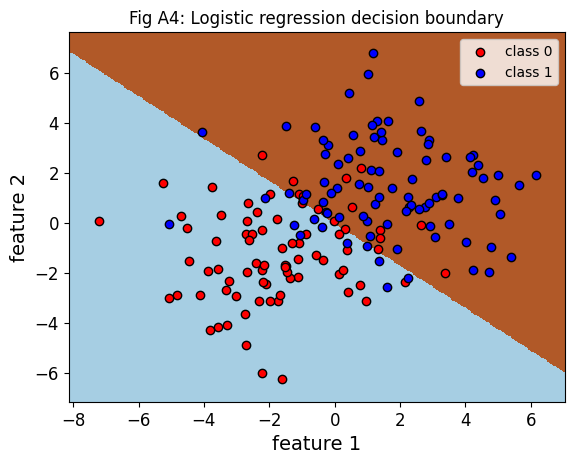

In [ ]:
log_model = linear_model.LogisticRegression(C=1e3)
log_model.fit(x_train, y_train)
print("Weights:", log_model.coef_.round(3), "Bias:", log_model.intercept_.round(3))

plot_decision_boundary(log_model, x_train, y_train, "feature 1", "feature 2",
                       "Fig A4: Logistic regression decision boundary")

> **Code explained:** Uses `predict_proba` to see the probability of class 1 for two new points: logistic regression gives probabilities, not just labels.

In [ ]:
# Variation: the probability output of logistic regression for two new points
new_points = np.array([[-2.0, -1.0], [2.5, 2.0]])
for p, prob in zip(new_points, log_model.predict_proba(new_points)[:, 1]):
    print(f"point {p}: P(class 1) = {prob:.3f}")

point [-2. -1.]: P(class 1) = 0.073
point [2.5 2. ]: P(class 1) = 0.980


### Evaluate the model

> **Code explained:** Prints the misclassification percentage on the training, validation and test sets.

In [ ]:
log_val_err_A = misclassification_pct(log_model, x_val, y_val)
log_test_err_A = misclassification_pct(log_model, x_test, y_test)
print(f"training misclassification percentage = {misclassification_pct(log_model, x_train, y_train):.2f} %")
print(f"validation misclassification percentage = {log_val_err_A:.2f} %")
print(f"test misclassification percentage = {log_test_err_A:.2f} %")

training misclassification percentage = 15.48 %
validation misclassification percentage = 22.22 %
test misclassification percentage = 16.67 %


Because the blobs **overlap**, no straight line can separate them perfectly — even the *training* error is above zero.

## A3. Decision tree regression
### Prepare data — the same data and the same split as A1
Re-using the A1 data and split means the tree's MSE can be compared directly with the linear model's MSE.

> **Code explained:** Re-uses the data and split from part A1 so that tree and line errors are comparable.

In [ ]:
x, y, train_idx, val_idx, test_idx = reg_data_A
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]

### Fit trees with `max_depth` = 1 … 10
A regression tree learns a **piece-wise constant** fit.

> **Code explained:** Fits regression trees with depth 1 to 10, plots each fit (piece-wise constant steps) and records train/validation/test MSE in a table.

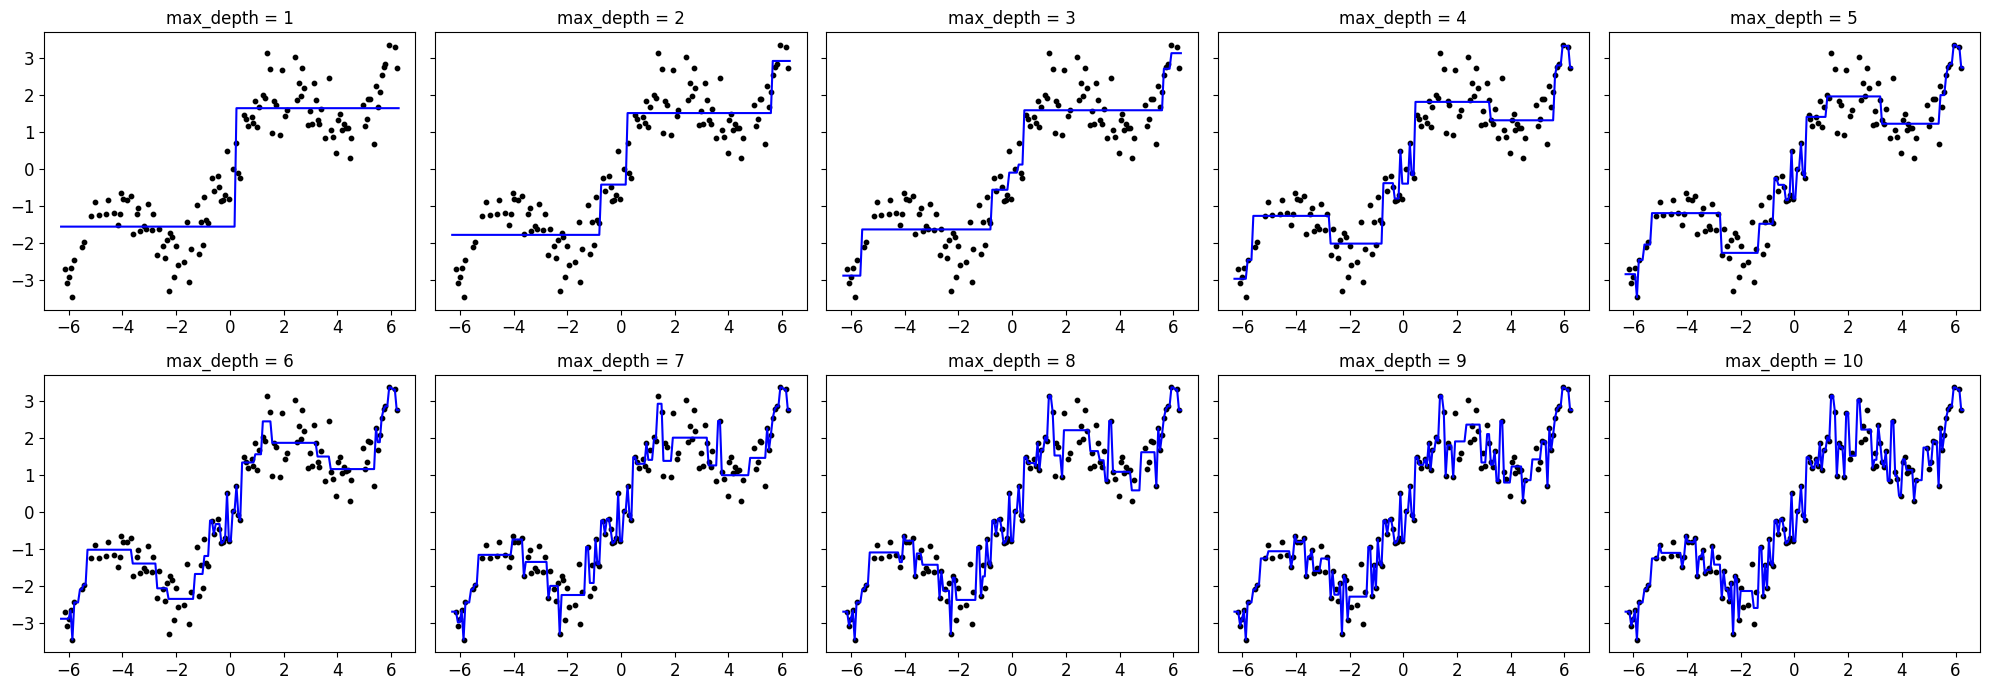

,max_depth,Training MSE,Validation MSE,Test MSE
0,1,0.6676,0.3704,1.3238
1,2,0.4583,0.3456,0.9363
2,3,0.3378,0.3205,0.8743
3,4,0.2460,0.3201,0.7850
4,5,0.1795,0.3232,0.7251
5,6,0.1538,0.3495,0.6727
6,7,0.0967,0.3073,0.8200
7,8,0.0639,0.3354,0.8156
8,9,0.0371,0.2298,0.8118
9,10,0.0163,0.2666,0.8205


In [ ]:
depths = np.arange(1, 11)
train_err, val_err, test_err = [], [], []
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)

for depth, ax in zip(depths, axes.ravel()):
    model = tree.DecisionTreeRegressor(max_depth=depth, random_state=0)
    model.fit(x_train.reshape(-1, 1), y_train)

    ax.scatter(x_train, y_train, color="black", s=10)
    ax.plot(x, model.predict(x.reshape(-1, 1)), color="blue")
    ax.set_title(f"max_depth = {depth}")

    train_err.append(mean_squared_error(y_train, model.predict(x_train.reshape(-1, 1))))
    val_err.append(mean_squared_error(y_val, model.predict(x_val.reshape(-1, 1))))
    test_err.append(mean_squared_error(y_test, model.predict(x_test.reshape(-1, 1))))
plt.tight_layout()
plt.show()

errors_A = pd.DataFrame({"max_depth": depths, "Training MSE": train_err,
                         "Validation MSE": val_err, "Test MSE": test_err}).round(4)
errors_A

> **Code explained:** Plots error vs depth and picks the depth with the lowest validation error, then compares its test MSE with the linear model.

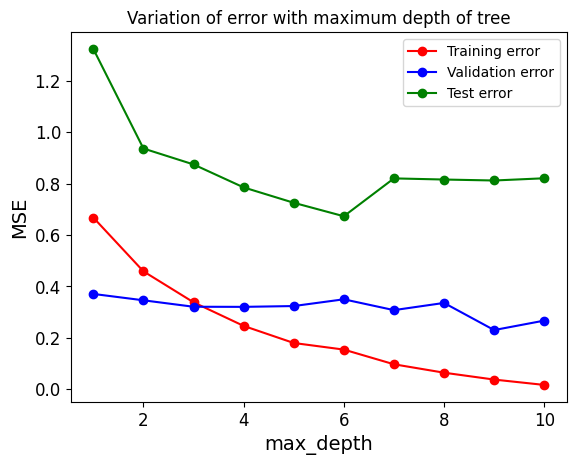

Best depth chosen on the validation set: 9
Test MSE  -> Decision tree (depth 9): 0.8118 | Linear regression: 1.4601


In [ ]:
plt.plot(depths, train_err, c="red", marker="o")
plt.plot(depths, val_err, c="blue", marker="o")
plt.plot(depths, test_err, c="green", marker="o")
plt.legend(["Training error", "Validation error", "Test error"])
plt.xlabel("max_depth")
plt.ylabel("MSE")
plt.title("Variation of error with maximum depth of tree")
plt.show()

best_depth_A = int(errors_A.loc[errors_A["Validation MSE"].idxmin(), "max_depth"])
tree_test_mse_A = float(errors_A.loc[errors_A["max_depth"] == best_depth_A, "Test MSE"].iloc[0])
print(f"Best depth chosen on the validation set: {best_depth_A}")
print(f"Test MSE  -> Decision tree (depth {best_depth_A}): {tree_test_mse_A:.4f} | Linear regression: {lin_test_mse_A:.4f}")

Training error keeps falling with depth, while validation/test error usually improves at first and then stops improving or rises once the tree starts fitting the noise (overfitting). Unlike the straight line, the tree can follow the sine wave.

## A4. Decision tree classification
### Prepare the data set — 3 classes, 4 features

> **Code explained:** Generates a 3-class dataset with 4 features and splits it 70/15/15.

In [ ]:
X, Y = datasets.make_classification(n_samples=360, n_features=4, n_informative=3, n_redundant=1,
                                    n_classes=3, n_clusters_per_class=1, class_sep=1.0, random_state=9)
feature_names_A = ["f1", "f2", "f3", "f4"]
class_names_A = ["class 0", "class 1", "class 2"]

number_of_samples = len(Y)
train_idx, val_idx, test_idx = split_70_15_15(number_of_samples, rng)
x_train, y_train = X[train_idx], Y[train_idx]
x_val, y_val = X[val_idx], Y[val_idx]
x_test, y_test = X[test_idx], Y[test_idx]

### Fit the model

> **Code explained:** Trains an unrestricted `DecisionTreeClassifier` and prints depth and number of leaves.

In [ ]:
clf_A = tree.DecisionTreeClassifier(random_state=0)
clf_A.fit(x_train, y_train)
print(f"Tree depth = {clf_A.get_depth()}, leaves = {clf_A.get_n_leaves()}")

Tree depth = 6, leaves = 15


### Visualise the model

> **Code explained:** Draws the trained tree with Graphviz (`export_graphviz` with `out_file=None` gives a string that `graphviz.Source` displays).

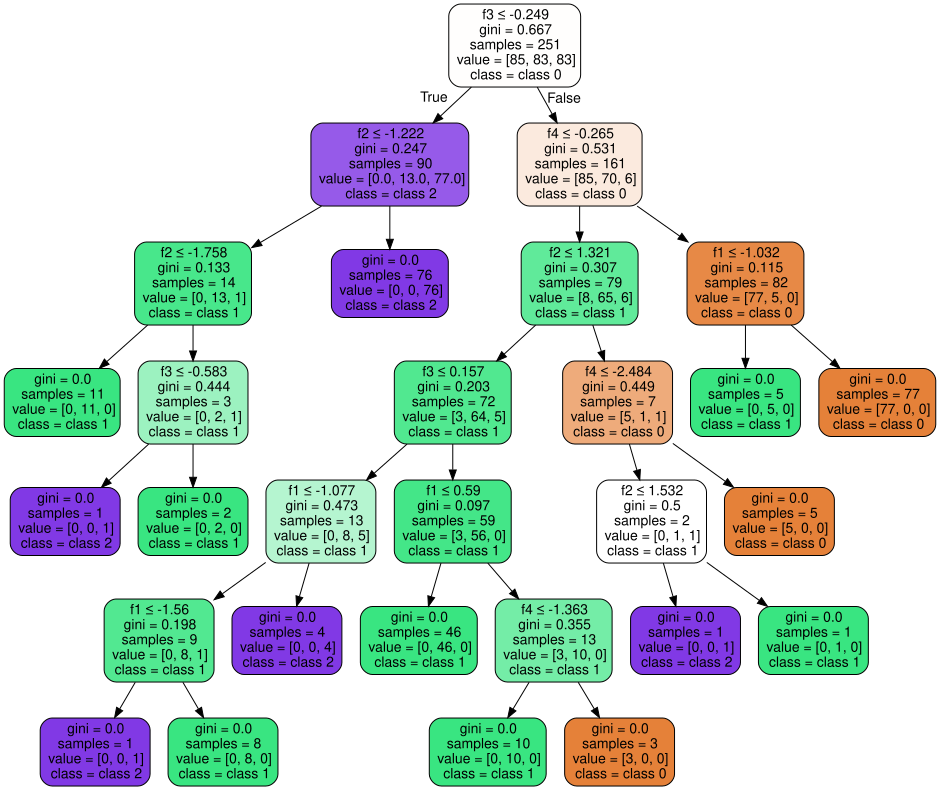

In [ ]:
dot_data = tree.export_graphviz(clf_A, out_file=None, feature_names=feature_names_A,
                                class_names=class_names_A, filled=True, rounded=True,
                                special_characters=True)
graphviz.Source(dot_data)

### Evaluate the model

> **Code explained:** Prints validation and test misclassification of the tree.

In [ ]:
print(f"validation misclassification percentage = {misclassification_pct(clf_A, x_val, y_val):.2f} %")
print(f"test misclassification percentage = {misclassification_pct(clf_A, x_test, y_test):.2f} %")

validation misclassification percentage = 3.70 %
test misclassification percentage = 7.27 %


---
# Dataset B — Real Data (Diabetes & Breast Cancer)

## B1. Linear regression — disease progression vs BMI

> **Code explained:** Dataset B, part 1: loads the real Diabetes data, plots BMI vs progression and creates the 70/15/15 split.

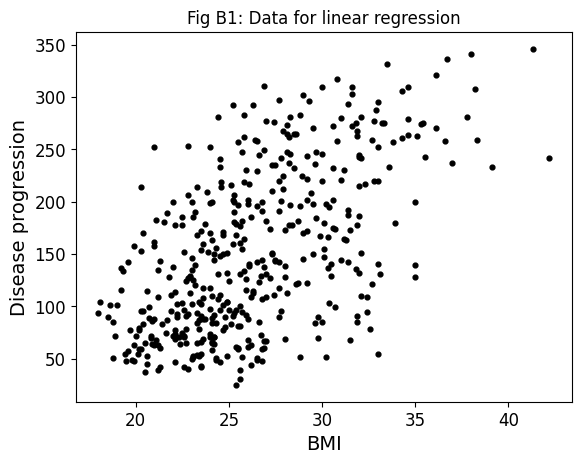

train = 309, validation = 66, test = 67


In [ ]:
rng = np.random.default_rng(5)
diabetes = datasets.load_diabetes(scaled=False)
x = diabetes.data[:, 2]          # BMI column
y = diabetes.target
number_of_samples = len(y)

plt.scatter(x, y, color="black", s=12)
plt.xlabel("BMI")
plt.ylabel("Disease progression")
plt.title("Fig B1: Data for linear regression")
plt.show()

train_idx, val_idx, test_idx = split_70_15_15(number_of_samples, rng)
reg_data_B = (train_idx, val_idx, test_idx)   # re-used in part B3
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]
print(f"train = {len(x_train)}, validation = {len(x_val)}, test = {len(x_test)}")

> **Code explained:** Fits a linear model on BMI, draws the line and prints validation and test MSE.

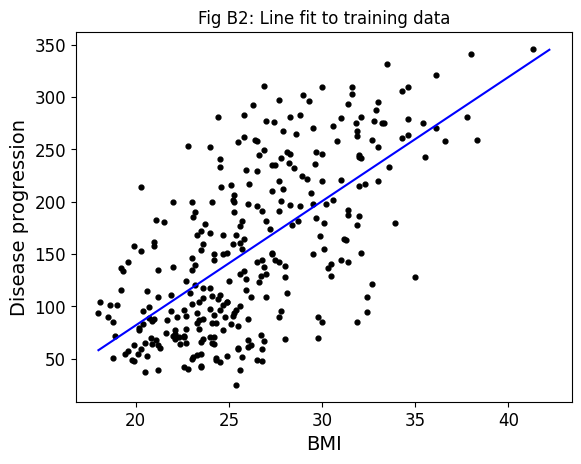

Validation MSE: 3884.4 
Test MSE: 5594.3


In [ ]:
model = linear_model.LinearRegression()
model.fit(x_train.reshape(-1, 1), y_train)

x_line = np.linspace(x.min(), x.max(), 200)
plt.scatter(x_train, y_train, color="black", s=12)
plt.plot(x_line, model.predict(x_line.reshape(-1, 1)), color="blue")
plt.xlabel("BMI")
plt.ylabel("Disease progression")
plt.title("Fig B2: Line fit to training data")
plt.show()

lin_val_mse_B = mean_squared_error(y_val, model.predict(x_val.reshape(-1, 1)))
lin_test_mse_B = mean_squared_error(y_test, model.predict(x_test.reshape(-1, 1)))
print("Validation MSE:", round(lin_val_mse_B, 1), "\nTest MSE:", round(lin_test_mse_B, 1))

## B2. Logistic regression — malignant vs benign tumours
Two features: **mean perimeter** and **mean texture**. In this dataset `0 = malignant`, `1 = benign`.

> **Code explained:** Loads the Breast Cancer data and keeps two features (mean perimeter, mean texture) to draw. Plots malignant vs benign training points.

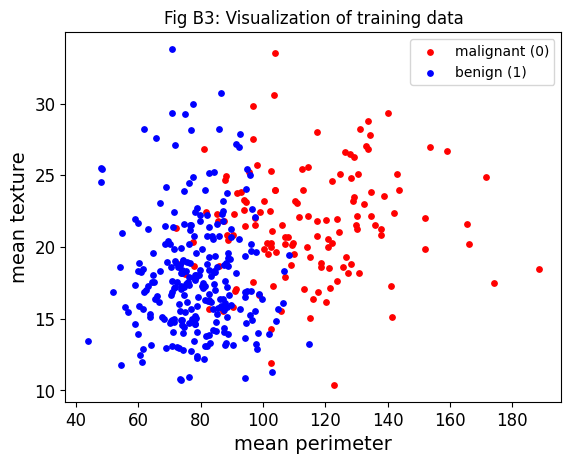

In [ ]:
cancer = datasets.load_breast_cancer()
X = cancer.data[:, [2, 1]]      # mean perimeter, mean texture
Y = cancer.target
number_of_samples = len(Y)
train_idx, val_idx, test_idx = split_70_15_15(number_of_samples, rng)
x_train, y_train = X[train_idx], Y[train_idx]
x_val, y_val = X[val_idx], Y[val_idx]
x_test, y_test = X[test_idx], Y[test_idx]

plt.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1], color="red", s=15)
plt.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1], color="blue", s=15)
plt.xlabel("mean perimeter")
plt.ylabel("mean texture")
plt.legend(["malignant (0)", "benign (1)"])
plt.title("Fig B3: Visualization of training data")
plt.show()

> **Code explained:** Fits a logistic regression on these two features, draws the boundary and reports validation and test misclassification.

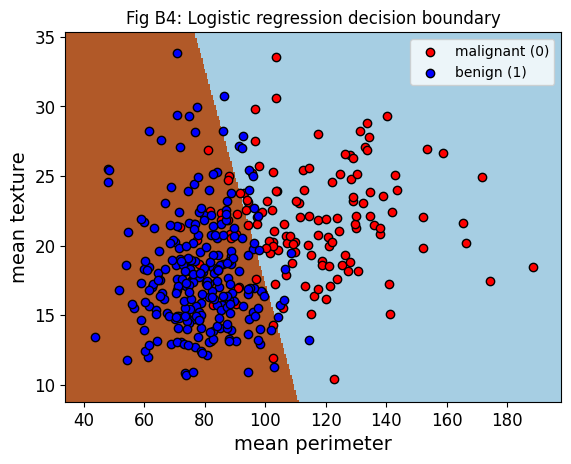

validation misclassification percentage = 9.41 %
test misclassification percentage = 5.81 %


In [ ]:
log_model = linear_model.LogisticRegression(C=1e3, max_iter=1000)
log_model.fit(x_train, y_train)
plot_decision_boundary(log_model, x_train, y_train, "mean perimeter", "mean texture",
                       "Fig B4: Logistic regression decision boundary",
                       labels=("malignant (0)", "benign (1)"))

log_val_err_B = misclassification_pct(log_model, x_val, y_val)
log_test_err_B = misclassification_pct(log_model, x_test, y_test)
print(f"validation misclassification percentage = {log_val_err_B:.2f} %")
print(f"test misclassification percentage = {log_test_err_B:.2f} %")

### How does the regularisation strength `C` change logistic regression?


Small `C` = strong regularisation (simple model); large `C` = weak regularisation (model fits the training data closely). We test several values on the breast-cancer data.

> **Code explained:** We loop over six values of `C`, train a logistic regression for each and store training, validation and test misclassification in a table. The last lines choose `C` by the lowest **validation** error (the test set stays untouched for the final report).

In [ ]:
import warnings
c_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # unscaled features can cause harmless convergence warnings
    for C in [0.001, 0.01, 0.1, 1, 10, 1000]:
        lr = linear_model.LogisticRegression(C=C, max_iter=5000).fit(x_train, y_train)
        c_rows.append([str(C), misclassification_pct(lr, x_train, y_train),
                       misclassification_pct(lr, x_val, y_val), misclassification_pct(lr, x_test, y_test)])

c_table = pd.DataFrame(c_rows, columns=["C", "train error %", "validation error %", "test error %"]).round(2)
print(c_table.to_string(index=False))

best_C = c_table.sort_values("validation error %").iloc[0]
print(f"\nConclusion: C = {best_C['C']} has the lowest validation error ({best_C['validation error %']}%); "
      f"its test error is {best_C['test error %']}%.")

    C  train error %  validation error %  test error %
0.001          10.55               10.59          8.14
 0.01          11.06               10.59          5.81
  0.1          11.06                9.41          5.81
    1          11.31                9.41          5.81
   10          11.31                9.41          5.81
 1000          11.31                9.41          5.81

Conclusion: C = 1 has the lowest validation error (9.41%); its test error is 5.81%.


**Conclusion:** extremely small `C` over-regularises the model and errors go up, while from a moderate `C` onwards the errors are almost flat. The decision boundary is a straight line anyway, so this model is stable once it is not over-regularised.

## B3. Decision tree regression — progression vs BMI
Same data and same split as B1, so the MSEs are comparable.

> **Code explained:** Part B3: decision-tree regression with depth 1–10 on the Diabetes data, using the same split as B1. It plots the fits and tabulates the errors.

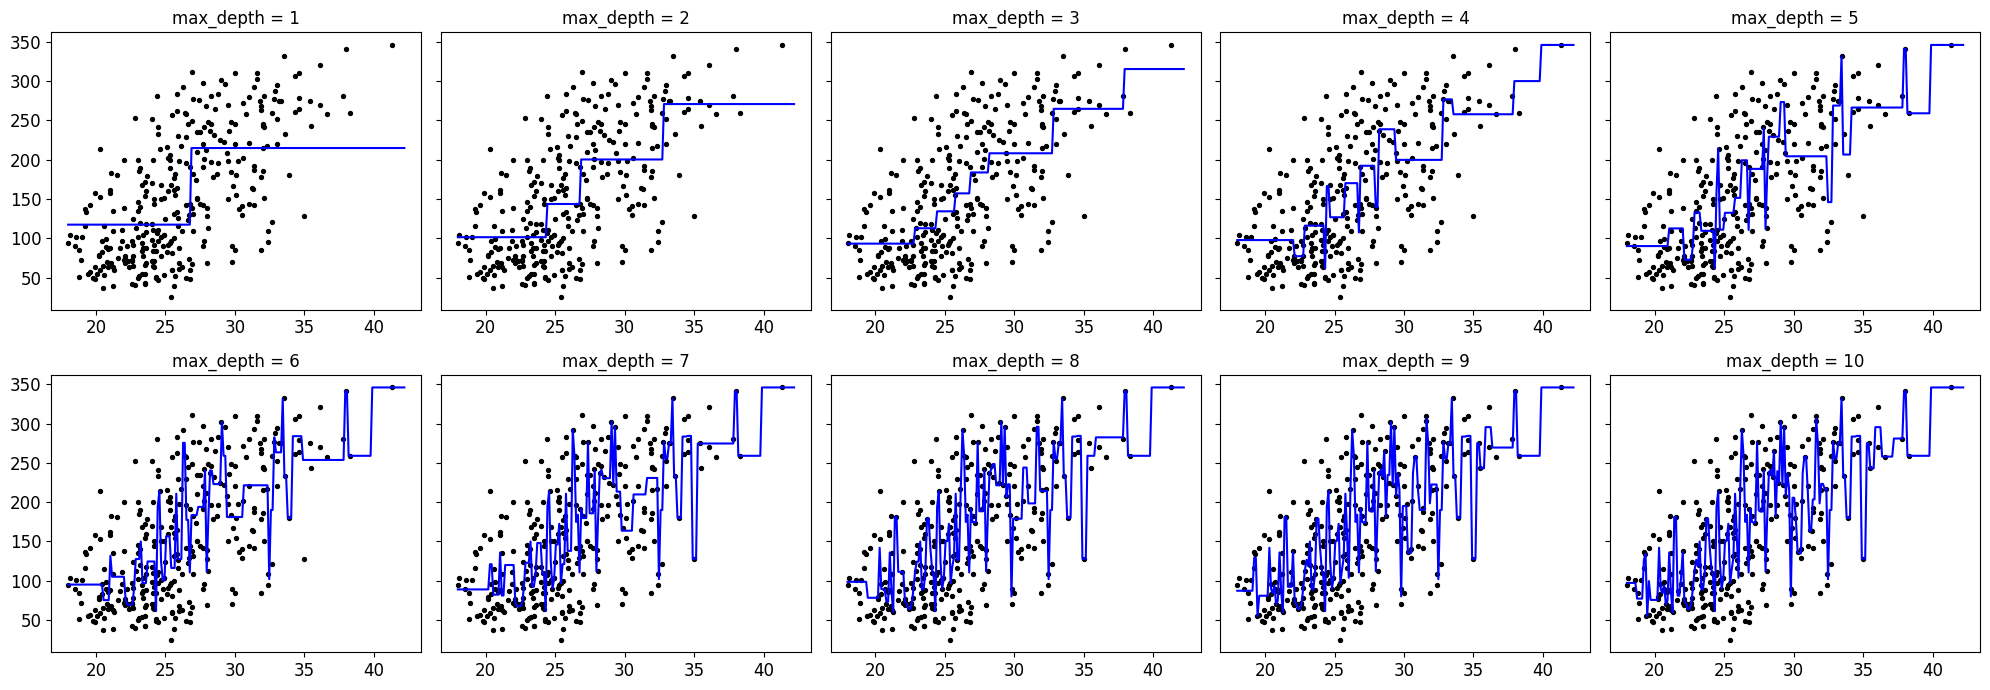

,max_depth,Training MSE,Validation MSE,Test MSE
0,1,4053.9,4249.8,5938.3
1,2,3479.2,4531.7,5277.8
2,3,3352.5,4503.1,5608.3
3,4,3113.3,5377.9,6167.7
4,5,2883.8,5549.1,6131.8
5,6,2574.7,5510.1,6477.9
6,7,2340.8,5536.7,6564.8
7,8,2145.4,5870.4,6767.1
8,9,2052.9,5959.5,6965.2
9,10,2032.6,6037.8,6989.5


In [ ]:
x = diabetes.data[:, 2]
y = diabetes.target
train_idx, val_idx, test_idx = reg_data_B
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]
x_test, y_test = x[test_idx], y[test_idx]

train_err, val_err, test_err = [], [], []
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)
for depth, ax in zip(depths, axes.ravel()):
    model = tree.DecisionTreeRegressor(max_depth=depth, random_state=0)
    model.fit(x_train.reshape(-1, 1), y_train)
    ax.scatter(x_train, y_train, color="black", s=8)
    ax.plot(x_line, model.predict(x_line.reshape(-1, 1)), color="blue")
    ax.set_title(f"max_depth = {depth}")
    train_err.append(mean_squared_error(y_train, model.predict(x_train.reshape(-1, 1))))
    val_err.append(mean_squared_error(y_val, model.predict(x_val.reshape(-1, 1))))
    test_err.append(mean_squared_error(y_test, model.predict(x_test.reshape(-1, 1))))
plt.tight_layout()
plt.show()

errors_B = pd.DataFrame({"max_depth": depths, "Training MSE": train_err,
                         "Validation MSE": val_err, "Test MSE": test_err}).round(1)
errors_B

> **Code explained:** Plots the error curves for the Diabetes trees and picks the best depth by validation MSE.

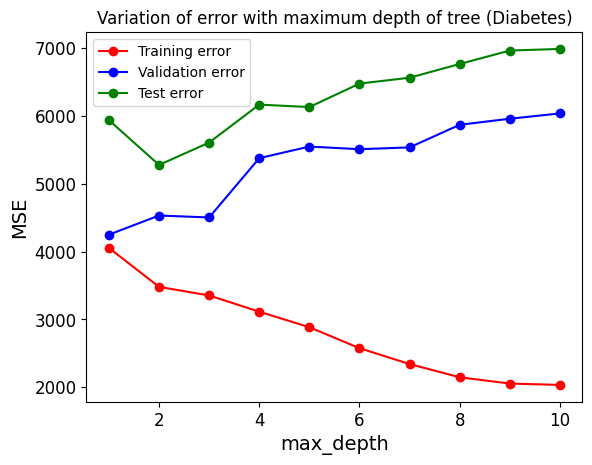

Best depth chosen on the validation set: 1


In [ ]:
plt.plot(depths, train_err, c="red", marker="o")
plt.plot(depths, val_err, c="blue", marker="o")
plt.plot(depths, test_err, c="green", marker="o")
plt.legend(["Training error", "Validation error", "Test error"])
plt.xlabel("max_depth")
plt.ylabel("MSE")
plt.title("Variation of error with maximum depth of tree (Diabetes)")
plt.show()

best_depth_B = int(errors_B.loc[errors_B["Validation MSE"].idxmin(), "max_depth"])
tree_test_mse_B = float(errors_B.loc[errors_B["max_depth"] == best_depth_B, "Test MSE"].iloc[0])
print(f"Best depth chosen on the validation set: {best_depth_B}")

On real data every model has a high MSE, because BMI explains only part of disease progression. A shallow tree chosen on the validation set performs about as well as the straight line (it does not clearly beat it), and deeper trees get clearly worse because they start fitting noise. With only ~66 validation and ~67 test patients, these curves are also noisy.

## B4. Decision tree classification — all 30 breast-cancer features

> **Code explained:** Part B4: trains a full tree and a depth-4 tree on all 30 breast-cancer features and compares depth, leaves and errors.

In [ ]:
X = cancer.data
Y = cancer.target
train_idx, val_idx, test_idx = split_70_15_15(len(Y), rng)
x_train, y_train = X[train_idx], Y[train_idx]
x_val, y_val = X[val_idx], Y[val_idx]
x_test, y_test = X[test_idx], Y[test_idx]

clf_full = tree.DecisionTreeClassifier(random_state=0).fit(x_train, y_train)
clf_d4 = tree.DecisionTreeClassifier(max_depth=4, random_state=0).fit(x_train, y_train)

for name, m in [("Full tree", clf_full), ("max_depth=4", clf_d4)]:
    print(f"{name:12s}: depth={m.get_depth()}, leaves={m.get_n_leaves():2d}, "
          f"val error={misclassification_pct(m, x_val, y_val):5.2f} %, "
          f"test error={misclassification_pct(m, x_test, y_test):5.2f} %")

Full tree   : depth=7, leaves=17, val error= 5.88 %, test error= 5.81 %
max_depth=4 : depth=4, leaves=11, val error= 8.24 %, test error= 3.49 %


> **Code explained:** Draws the depth-4 tree (the full tree would be too large to read).

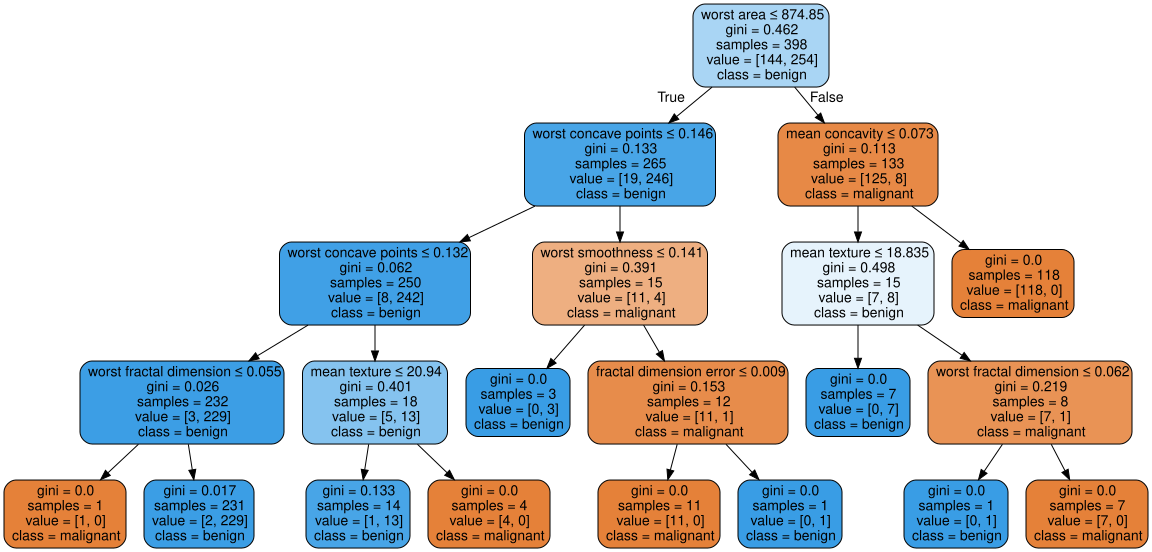

In [ ]:
# Visualise the depth-4 tree (the full tree is too large to read)
dot_data = tree.export_graphviz(clf_d4, out_file=None, feature_names=cancer.feature_names,
                                class_names=cancer.target_names, filled=True, rounded=True,
                                special_characters=True)
graphviz.Source(dot_data)

---
## Comparison summary

> **Code explained:** Collects the test errors of all models from both datasets into one comparison table.

In [ ]:
summary = pd.DataFrame({
    "Dataset A (synthetic)": [f"{lin_test_mse_A:.3f}", f"{tree_test_mse_A:.3f} (depth {best_depth_A})",
                              f"{log_test_err_A:.1f} %"],
    "Dataset B (real)": [f"{lin_test_mse_B:.1f}", f"{tree_test_mse_B:.1f} (depth {best_depth_B})",
                         f"{log_test_err_B:.1f} %"],
}, index=["Linear regression — test MSE", "Decision tree regression — test MSE",
          "Logistic regression — test misclassification"])
summary

,Dataset A (synthetic),Dataset B (real)
Linear regression — test MSE,1.460,5594.3
Decision tree regression — test MSE,0.812 (depth 9),5938.3 (depth 1)
Logistic regression — test misclassification,16.7 %,5.8 %


| | Linear regression | Logistic regression | Decision tree |
|---|---|---|---|
| Task | regression | classification | both |
| Parametric? | yes (slope + intercept) | yes (weights + bias) | no — structure grows with data |
| Decision boundary / fit | straight line / hyperplane | linear boundary, sigmoid gives probabilities | piece-wise constant, axis-parallel splits |
| Main risk | underfitting non-linear data | underfitting when classes aren't linearly separable | overfitting when depth is unlimited |
| Evaluated with | MSE | misclassification % | MSE / misclassification % |

---

# Lab 7 — Support Vector Machines (Linear and Non-Linear)

An SVM finds the boundary with the **widest margin** between classes. With kernels or polynomial features it can also draw curved boundaries.

| | Part A | Part B |
|---|---|---|
| Data | Wine (real) | `make_circles` (two rings, synthetic) |
| Linear SVM | detect `class_0` wines using proline & flavanoids | shows that a straight line **fails** on rings |
| Non-linear SVM | RBF/poly kernel on all 13 features | polynomial features, the kernel trick, RBF with different `gamma` and `C` |

**Our own addition (end of lab):** an **SVM vs k-NN** comparison on rings with increasing noise, to see which model copes better when the data gets messy.

> **Code explained:** Imports NumPy, Matplotlib, scikit-learn datasets, `Pipeline`, scalers, polynomial features, `LinearSVC` / `SVC` and the splitter.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import train_test_split

---
# Part A — Wine

## Problem Statement A1 — Linear SVM Classification
Load the Wine dataset, use the **proline** and **flavanoids** features, scale them, and train a linear SVM to detect **class_0** wines. Use the resulting model to classify sample wines.

> **Code explained:** Loads the Wine data, takes two features (proline and flavanoids) and makes a binary target: 1 for `class_0`, 0 for the rest. It prints the feature ranges to show how different the scales are.

In [ ]:
wine = datasets.load_wine()
print(wine["feature_names"][12], "and", wine["feature_names"][6])

X = wine["data"][:, (12, 6)]                      # proline, flavanoids
y = (wine["target"] == 0).astype(np.float64)      # class_0 has code 0  ->  1 = class_0, 0 = other

print("X range before scaling: proline", X[:, 0].min(), "-", X[:, 0].max(),
      "| flavanoids", X[:, 1].min(), "-", X[:, 1].max())

proline and flavanoids
X range before scaling: proline 278.0 - 1680.0 | flavanoids 0.34 - 5.08


> **Code explained:** Splits the data, builds a pipeline (scale → `LinearSVC`) and prints train/test accuracy. Then it classifies two sample wines. `C=0.5` controls how much margin violation is tolerated.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=5)

svm_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("linear_svc", LinearSVC(C=0.5, loss="hinge", random_state=42)),
])
svm_clf.fit(X_train, y_train)
print(f"Train accuracy: {svm_clf.score(X_train, y_train):.3f} | Test accuracy: {svm_clf.score(X_test, y_test):.3f}")

# Predict two sample wines: [proline, flavanoids]
samples = [[1250, 2.8], [450, 0.9]]
print(svm_clf.predict(samples))   # [1 -- class_0, 0 -- not class_0]

Train accuracy: 0.960 | Test accuracy: 0.963
[1. 0.]


### Visualising the margin: soft (C = 0.05) vs harder (C = 50)
The solid line is the decision boundary (decision function = 0); the dashed lines are the margin edges (±1). Points inside or beyond the margin are margin violations.

> **Code explained:** Defines a function that draws the decision boundary (solid line) and the margin edges (dashed lines), then trains a soft-margin (C=0.05) and a harder-margin (C=50) model and plots them side by side.

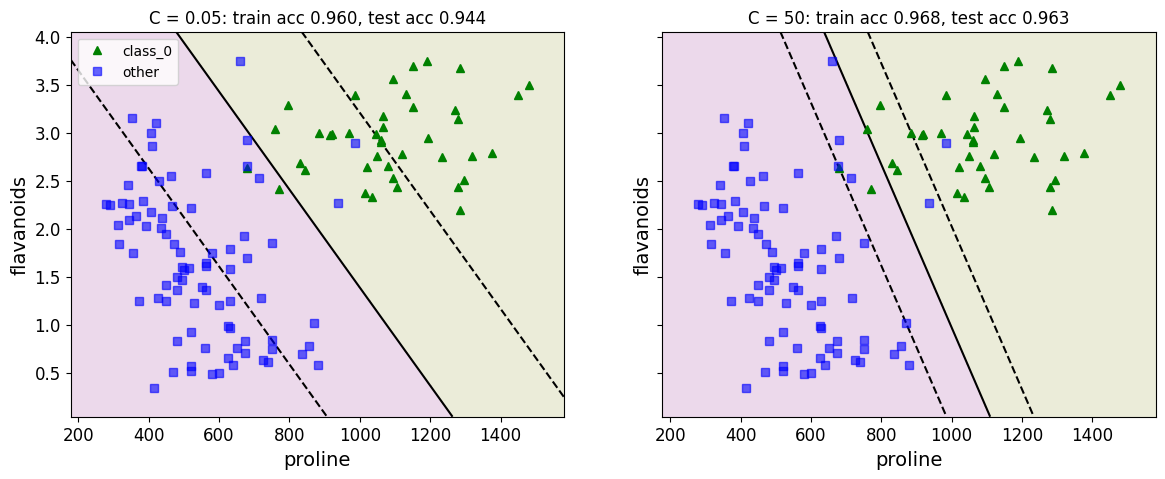

In [ ]:
def plot_svc_margin(clf, X, y, ax, title):
    x0s = np.linspace(X[:, 0].min() - 100, X[:, 0].max() + 100, 300)
    x1s = np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 300)
    x0, x1 = np.meshgrid(x0s, x1s)
    grid = np.c_[x0.ravel(), x1.ravel()]
    decision = clf.decision_function(grid).reshape(x0.shape)
    ax.contourf(x0, x1, decision > 0, alpha=0.15, cmap=plt.cm.brg)
    ax.contour(x0, x1, decision, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.plot(X[:, 0][y == 1], X[:, 1][y == 1], "g^", label="class_0")
    ax.plot(X[:, 0][y == 0], X[:, 1][y == 0], "bs", label="other", alpha=0.6)
    ax.set_xlabel("proline")
    ax.set_ylabel("flavanoids")
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, C in zip(axes, [0.05, 50]):
    clf = Pipeline([("scaler", StandardScaler()),
                    ("linear_svc", LinearSVC(C=C, loss="hinge", max_iter=100000, random_state=42))]).fit(X_train, y_train)
    plot_svc_margin(clf, X_train, y_train, ax,
                    f"C = {C}: train acc {clf.score(X_train, y_train):.3f}, test acc {clf.score(X_test, y_test):.3f}")
axes[0].legend(loc="upper left")
plt.show()

Small **C** → wide margin with more violations allowed (more regularisation). Large **C** → narrow margin that tries hard to classify every training point.

## Problem Statement A2 — Non-linear SVM (kernel) on all features, all 3 classes
`SVC` handles multi-class problems automatically (one-vs-one).

> **Code explained:** Uses all 13 features and all 3 classes. `SVC` handles multi-class automatically. We compare linear, RBF and polynomial kernels with scaling, and RBF without scaling.

In [ ]:
X_all, y_all = wine.data, wine.target
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.3, stratify=y_all, random_state=5)

for kernel in ["linear", "rbf", "poly"]:
    clf = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel=kernel, C=1, gamma="scale"))])
    clf.fit(X_train, y_train)
    print(f"kernel = {kernel:6s}: train acc = {clf.score(X_train, y_train):.3f}, test acc = {clf.score(X_test, y_test):.3f}")

# Without scaling, for comparison
clf_unscaled = SVC(kernel="rbf").fit(X_train, y_train)
print(f"rbf WITHOUT scaling: test acc = {clf_unscaled.score(X_test, y_test):.3f}")

kernel = linear: train acc = 1.000, test acc = 0.963
kernel = rbf   : train acc = 1.000, test acc = 0.981
kernel = poly  : train acc = 0.992, test acc = 0.963
rbf WITHOUT scaling: test acc = 0.704


With all 13 standardised features the classes are usually separated very well. Without scaling, `proline` dominates the RBF distance and accuracy typically drops — SVMs, like k-NN, need scaled features.

---
# Part B — Concentric Circles (`make_circles`)

## Problem Statement B1 — Can a linear SVM separate rings?

> **Code explained:** Creates two concentric rings with `make_circles` and plots them. No straight line can separate an inner ring from an outer ring.

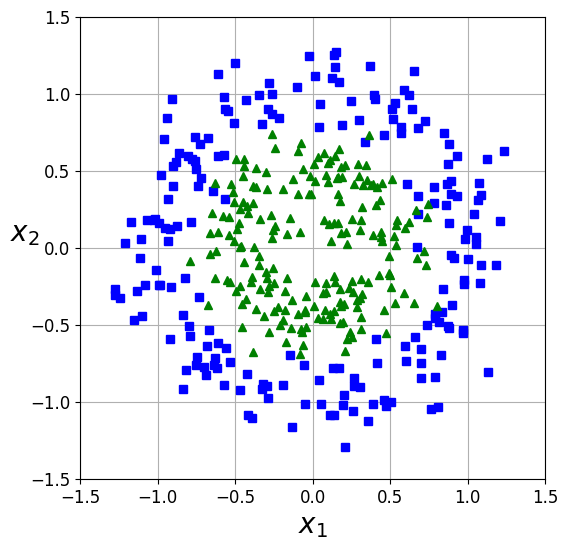

In [ ]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=400, noise=0.15, factor=0.5, random_state=8)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=8)

def plot_dataset(X, y, axes):
    plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], "bs")   # blue squares  = outer ring
    plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], "g^")   # green triangles = inner ring
    plt.axis(axes)
    plt.grid(True, which="both")
    plt.xlabel(r"$x_1$", fontsize=20)
    plt.ylabel(r"$x_2$", fontsize=20, rotation=0)

axes_range = [-1.5, 1.5, -1.5, 1.5]
plt.figure(figsize=(6, 6))
plot_dataset(X, y, axes_range)
plt.show()

> **Code explained:** Trains a plain `LinearSVC` on the rings and draws its prediction regions. The poor accuracy shows the limit of linear models.

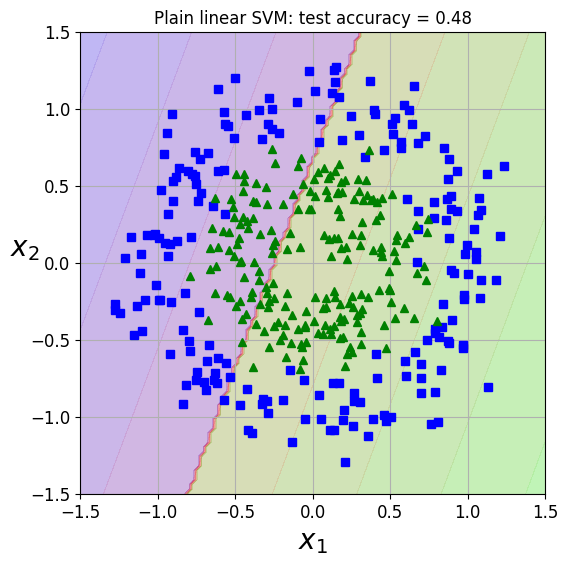

In [ ]:
def plot_predictions(clf, axes):
    x0s = np.linspace(axes[0], axes[1], 100)
    x1s = np.linspace(axes[2], axes[3], 100)
    x0, x1 = np.meshgrid(x0s, x1s)
    X_grid = np.c_[x0.ravel(), x1.ravel()]
    y_pred = clf.predict(X_grid).reshape(x0.shape)
    y_decision = clf.decision_function(X_grid).reshape(x0.shape)
    plt.contourf(x0, x1, y_pred, cmap=plt.cm.brg, alpha=0.2)
    plt.contourf(x0, x1, y_decision, cmap=plt.cm.brg, alpha=0.1)

linear_only = Pipeline([("scaler", StandardScaler()),
                        ("svm_clf", LinearSVC(C=5, loss="hinge", max_iter=100000, random_state=42))])
linear_only.fit(X_train, y_train)

plt.figure(figsize=(6, 6))
plot_predictions(linear_only, axes_range)
plot_dataset(X, y, axes_range)
plt.title(f"Plain linear SVM: test accuracy = {linear_only.score(X_test, y_test):.2f}")
plt.show()

A straight line can only do slightly better than guessing on rings.

## Problem Statement B2 — Non-linear SVM with polynomial features
Adding degree-2 features ($x_1^2, x_1x_2, x_2^2$) makes the rings linearly separable, because the circle $x_1^2 + x_2^2 = r^2$ is a **linear** equation in those new features.

> **Code explained:** Adds degree-2 polynomial features before the linear SVM. In the new feature space the rings *are* linearly separable, so accuracy shoots up.

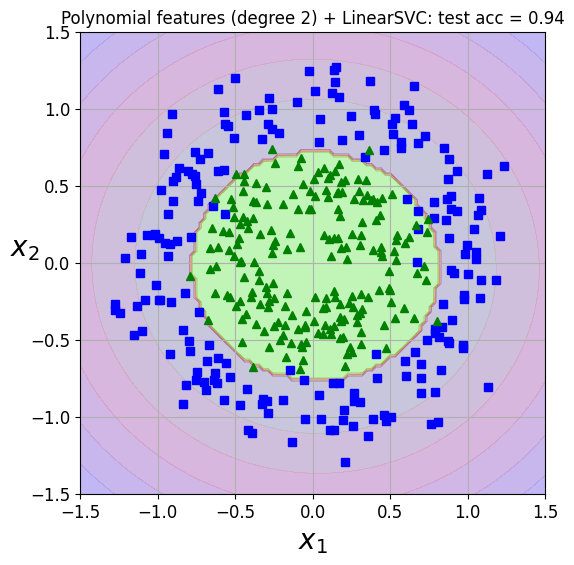

In [ ]:
polynomial_svm_clf = Pipeline([
    ("poly_features", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("svm_clf", LinearSVC(C=5, loss="hinge", max_iter=100000, random_state=42)),
])
polynomial_svm_clf.fit(X_train, y_train)

plt.figure(figsize=(6, 6))
plot_predictions(polynomial_svm_clf, axes_range)
plot_dataset(X, y, axes_range)
plt.title(f"Polynomial features (degree 2) + LinearSVC: test acc = {polynomial_svm_clf.score(X_test, y_test):.2f}")
plt.show()

### The kernel trick: same effect without actually creating the features

> **Code explained:** Uses `SVC(kernel="poly", degree=3)`: the **kernel trick** gives the same effect without actually creating the extra columns.

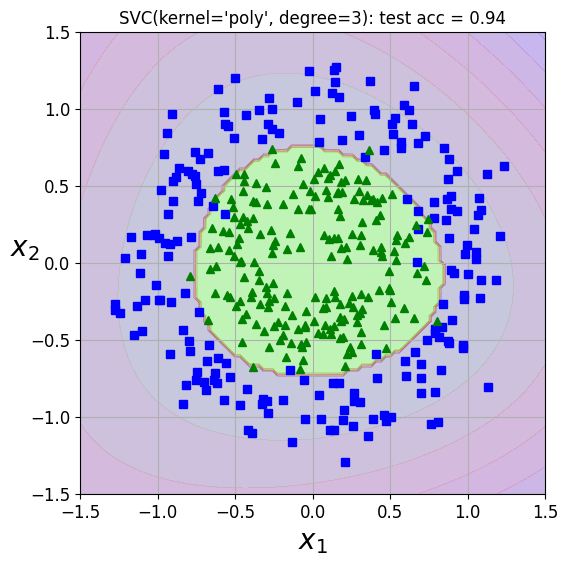

In [ ]:
poly_kernel_svm_clf = Pipeline([("scaler", StandardScaler()),
                                ("svm_clf", SVC(kernel="poly", degree=3, coef0=1, C=3))])
poly_kernel_svm_clf.fit(X_train, y_train)

plt.figure(figsize=(6, 6))
plot_predictions(poly_kernel_svm_clf, axes_range)
plot_dataset(X, y, axes_range)
plt.title(f"SVC(kernel='poly', degree=3): test acc = {poly_kernel_svm_clf.score(X_test, y_test):.2f}")
plt.show()

### Gaussian RBF kernel — effect of `gamma` and `C`
- **gamma ↑** → each training point's influence is narrower → wigglier boundary (risk of overfitting)
- **C ↑** → less regularisation → fewer margin violations allowed

> **Code explained:** Trains an RBF-kernel SVM for four combinations of `gamma` and `C` and draws all four. High `gamma` gives wiggly, overfit boundaries; low `gamma` gives smooth ones.

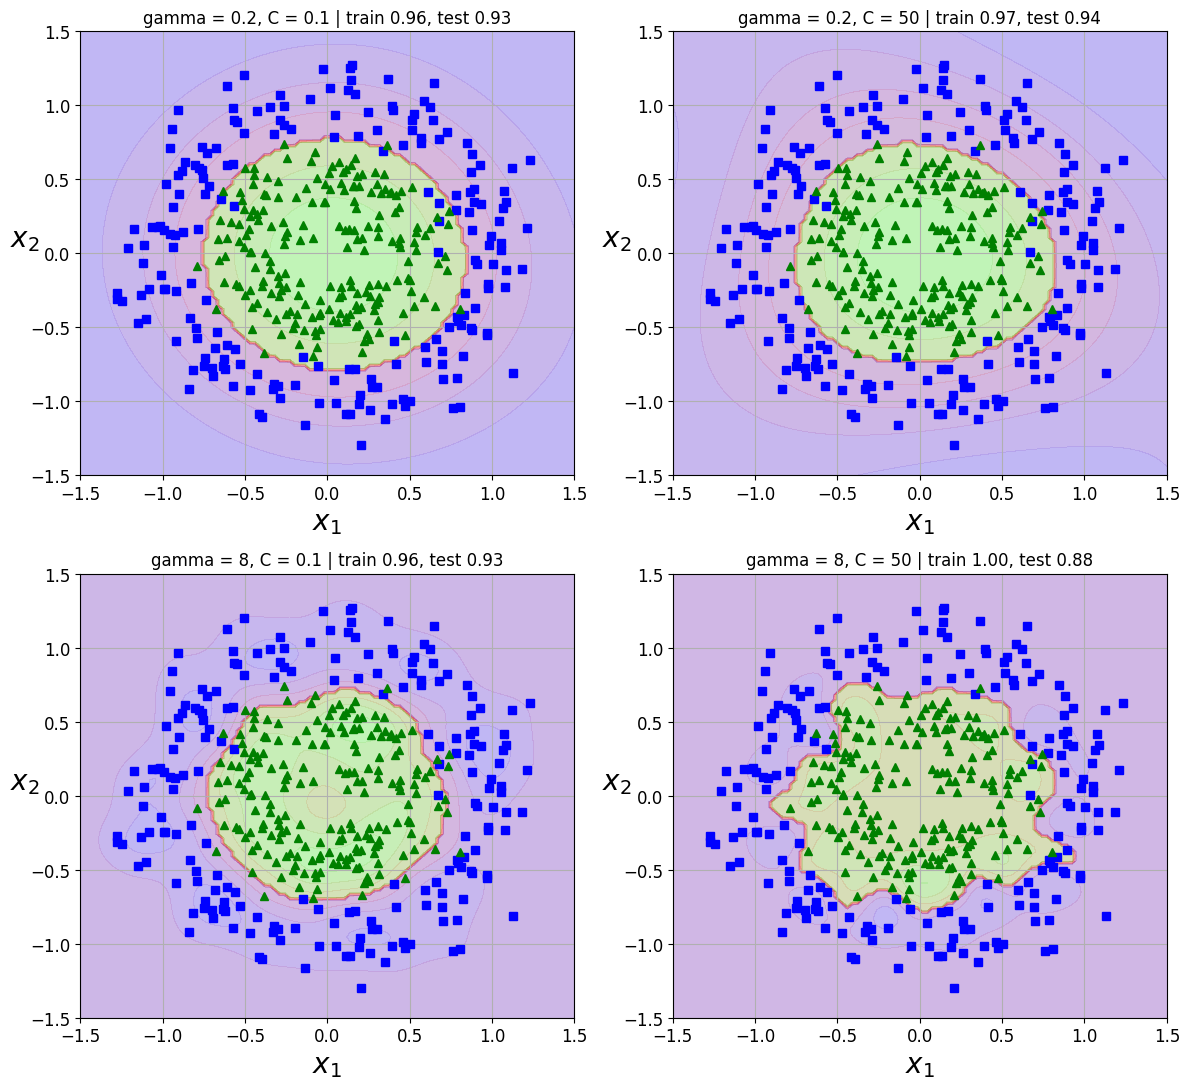

In [ ]:
settings = [(0.2, 0.1), (0.2, 50), (8, 0.1), (8, 50)]
plt.figure(figsize=(12, 11))
for i, (gamma, C) in enumerate(settings, 1):
    rbf_clf = Pipeline([("scaler", StandardScaler()), ("svm_clf", SVC(kernel="rbf", gamma=gamma, C=C))])
    rbf_clf.fit(X_train, y_train)
    plt.subplot(2, 2, i)
    plot_predictions(rbf_clf, axes_range)
    plot_dataset(X, y, axes_range)
    plt.title(f"gamma = {gamma}, C = {C} | train {rbf_clf.score(X_train, y_train):.2f}, "
              f"test {rbf_clf.score(X_test, y_test):.2f}", fontsize=12)
plt.tight_layout()
plt.show()

### SVM vs k-NN when the rings get noisier
We keep the same two-ring data but increase the noise step by step and compare an RBF-kernel SVM with a k-NN classifier.

> **Code explained:** For each noise level we generate a new circles dataset, split it, train a scaled `SVC` and a scaled `KNeighborsClassifier`, and store the test accuracy of each. The table and line plot compare them; the last lines count which model wins more often.

 noise  SVM (RBF) test acc  k-NN (k=7) test acc
  0.05               1.000                1.000
  0.15               0.950                0.950
  0.30               0.842                0.817
  0.45               0.708                0.692


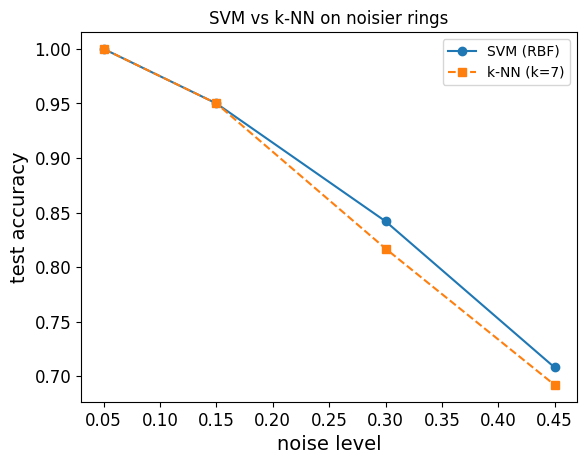


Conclusion: SVM won 2 noise levels, k-NN won 0, the rest were ties.


In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

rows = []
for noise in [0.05, 0.15, 0.30, 0.45]:
    Xn, yn = make_circles(n_samples=400, noise=noise, factor=0.5, random_state=8)
    Xtr, Xte, ytr, yte = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=8)
    svm_m = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf", gamma="scale", C=1))]).fit(Xtr, ytr)
    knn_m = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=7))]).fit(Xtr, ytr)
    rows.append([noise, svm_m.score(Xte, yte), knn_m.score(Xte, yte)])

noise_table = pd.DataFrame(rows, columns=["noise", "SVM (RBF) test acc", "k-NN (k=7) test acc"]).round(3)
print(noise_table.to_string(index=False))

plt.plot(noise_table["noise"], noise_table["SVM (RBF) test acc"], "o-", label="SVM (RBF)")
plt.plot(noise_table["noise"], noise_table["k-NN (k=7) test acc"], "s--", label="k-NN (k=7)")
plt.xlabel("noise level")
plt.ylabel("test accuracy")
plt.title("SVM vs k-NN on noisier rings")
plt.legend()
plt.show()

svm_wins = int((noise_table.iloc[:, 1] > noise_table.iloc[:, 2]).sum())
knn_wins = int((noise_table.iloc[:, 1] < noise_table.iloc[:, 2]).sum())
print(f"\nConclusion: SVM won {svm_wins} noise levels, k-NN won {knn_wins}, the rest were ties.")

**Conclusion:** both models handle clean rings well, and both lose accuracy as noise grows because the rings start to overlap. The table shows which one degrades more slowly; neither can beat the noise itself, which sets an upper limit on accuracy.

---
## Lab 7 summary
| Model | Where it works | Key hyper-parameters |
|---|---|---|
| `LinearSVC` | linearly separable data (Wine class_0 with 2 features) | `C` |
| Polynomial features + `LinearSVC` | curved boundaries; you choose the degree | `degree`, `C` |
| `SVC(kernel="poly")` | same, without creating features (kernel trick) | `degree`, `coef0`, `C` |
| `SVC(kernel="rbf")` | most non-linear problems | `gamma`, `C` |

Always **scale** features before an SVM.

**Our addition:** SVM (RBF) vs k-NN on noisy rings.

---

# Lab 8 — Naive Bayes Classifier

Naive Bayes uses **Bayes' rule**: P(class | features) ∝ P(class) × P(features | class), and 'naively' assumes the features are independent given the class. Gaussian NB models each numeric feature as a bell curve per class.

| | Part A | Part B |
|---|---|---|
| Data | Wine (real, 3 balanced classes, 13 numeric features) | Synthetic **telecom customer churn** CSV (5,000 customers, imbalanced) |
| Skills | basic NB, `predict_proba`, what the model learned | `get_dummies`, imbalance, priors, threshold tuning |

**Our own addition (end of Part A):** we change the `var_smoothing` parameter of Gaussian NB and see how accuracy reacts.

*Note:* metrics are always called as `metric(y_true, y_pred)` (true values first).

> **Code explained:** Imports NumPy, Pandas, Matplotlib, Seaborn, `GaussianNB`, the splitter and all metrics used in this lab.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, classification_report, precision_score, recall_score)

---
# Part A — Naive Bayes on the Wine Dataset

**Load the data**

> **Code explained:** Loads the Wine data and prints its shape, class names and the number of samples per class.

In [ ]:
from sklearn.datasets import load_wine

wine = load_wine()
X, y = wine.data, wine.target
print("X shape:", X.shape)
print("Classes:", wine.target_names.tolist(), "| counts:", np.bincount(y).tolist())

X shape: (178, 13)
Classes: ['class_0', 'class_1', 'class_2'] | counts: [59, 71, 48]


**Visualise two features** (alcohol vs colour intensity), coloured by class.

> **Code explained:** Scatter plot of two features (alcohol vs colour intensity) coloured by class. If the classes form different clouds, a probabilistic model should work well.

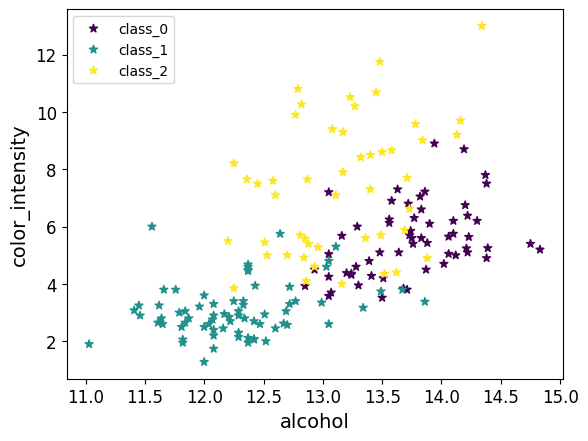

In [ ]:
scatter = plt.scatter(X[:, 0], X[:, 9], c=y, marker="*", cmap="viridis")
plt.xlabel("alcohol")
plt.ylabel("color_intensity")
plt.legend(scatter.legend_elements()[0], wine.target_names)
plt.show()

**Train/test split** (70% train, 30% test)

> **Code explained:** Splits the data 70/30 and prints the shapes of the two parts.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=11)
print(X_train.shape, X_test.shape)

(124, 13) (54, 13)


**Model building and training**

Gaussian NB assumes each feature is normally distributed within each class and that features are independent given the class. It learns one mean and one variance **per feature per class**.

> **Code explained:** Creates and trains `GaussianNB`. For one test sample it prints the actual class, the predicted class and the **posterior probabilities** — the model's confidence in each class.

In [ ]:
model = GaussianNB()
model.fit(X_train, y_train)

# Predict a single test sample
predicted = model.predict([X_test[3]])
print("Actual Value:", y_test[3])
print("Predicted Value:", predicted[0])

# Variation: posterior probabilities P(class | features) for that sample
posterior = model.predict_proba([X_test[3]])[0]
print("Posterior probabilities:", {c: round(float(p), 4) for c, p in zip(wine.target_names.tolist(), posterior)})

Actual Value: 0
Predicted Value: 0
Posterior probabilities: {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}


> **Code explained:** Shows what the model learned: `theta_` holds the mean of each feature for every class. We print three features to see how the classes differ.

In [ ]:
# What did the model learn? Per-class means of three features
pd.DataFrame(model.theta_[:, [0, 9, 12]], index=wine.target_names,
             columns=["alcohol (mean)", "color_intensity (mean)", "proline (mean)"]).round(2)

,alcohol (mean),color_intensity (mean),proline (mean)
class_0,13.68,5.37,1081.32
class_1,12.33,3.06,524.57
class_2,13.14,7.06,625.41


**Model evaluation**

> **Code explained:** Predicts the whole test set and prints accuracy and weighted F1 score.

In [ ]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", round(accuracy, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.9444
F1 Score: 0.9442


> **Code explained:** Draws the confusion matrix, showing which classes are mixed up (diagonal = correct).

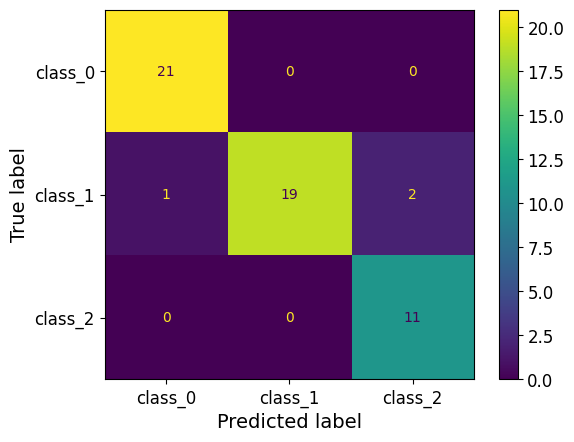

In [ ]:
labels = [0, 1, 2]
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
disp.plot();

Even though the 'naive' independence assumption is clearly false for Wine (e.g. flavanoids and total phenols are strongly correlated), Gaussian NB usually does very well here.

### The `var_smoothing` parameter
Gaussian NB adds a tiny amount (`var_smoothing` × the largest feature variance) to every variance to avoid dividing by zero. What if we make that amount large?

> **Code explained:** For seven values of `var_smoothing` we run 5-fold cross-validation on the Wine data and plot the mean accuracy on a log scale. The last lines name the best value and the worst.

var_smoothing =   1e-09: mean CV accuracy = 0.966
var_smoothing =   1e-06: mean CV accuracy = 0.967
var_smoothing =   0.001: mean CV accuracy = 0.764
var_smoothing =     0.1: mean CV accuracy = 0.703
var_smoothing =       1: mean CV accuracy = 0.646
var_smoothing =      10: mean CV accuracy = 0.545
var_smoothing =     100: mean CV accuracy = 0.399


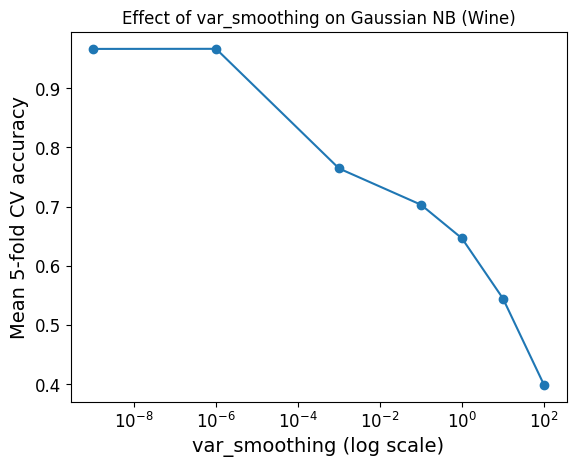


Conclusion: best var_smoothing = 1e-06 (0.967); worst = 100 (0.399).


In [ ]:
from sklearn.model_selection import cross_val_score

smoothing_values = [1e-9, 1e-6, 1e-3, 1e-1, 1, 10, 100]
mean_acc = [cross_val_score(GaussianNB(var_smoothing=v), X, y, cv=5).mean() for v in smoothing_values]

for v, a in zip(smoothing_values, mean_acc):
    print(f"var_smoothing = {v:>7}: mean CV accuracy = {a:.3f}")

plt.semilogx(smoothing_values, mean_acc, "o-")
plt.xlabel("var_smoothing (log scale)")
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("Effect of var_smoothing on Gaussian NB (Wine)")
plt.show()

best_v = smoothing_values[int(np.argmax(mean_acc))]
worst_v = smoothing_values[int(np.argmin(mean_acc))]
print(f"\nConclusion: best var_smoothing = {best_v} ({max(mean_acc):.3f}); worst = {worst_v} ({min(mean_acc):.3f}).")

**Conclusion:** small values (the default is 1e-9) work fine, but a very large `var_smoothing` makes every feature's bell curve extremely wide, so the model can no longer tell the classes apart and accuracy falls.

---
# Part B — Naive Bayes for Predicting Customer Churn

A telecom company wants to predict which customers will **leave** (churn). Only a minority of customers churn, so the target is **imbalanced**.

**Create the CSV file** (synthetic data, generated once and saved to disk)

> **Code explained:** Generates a synthetic telecom customer table (contract, payment, internet type, tenure, charges, support calls...) where the chance of leaving depends on those features, and saves it as a CSV file.

In [ ]:
rng = np.random.default_rng(12)
n = 5000
contract = rng.choice(["Month-to-month", "One year", "Two year"], n, p=[0.55, 0.25, 0.20])
payment = rng.choice(["UPI", "Credit card", "Net banking", "Cash"], n, p=[0.40, 0.25, 0.20, 0.15])
internet = rng.choice(["Fiber", "DSL", "No internet"], n, p=[0.45, 0.40, 0.15])
senior = rng.binomial(1, 0.15, n)
tenure = rng.integers(1, 73, n)
monthly = (np.select([internet == "Fiber", internet == "DSL"], [900, 600], 300) + rng.normal(0, 120, n)).clip(150).round(2)
total = (monthly * tenure * rng.uniform(0.95, 1.05, n)).round(2)
support_calls = rng.poisson(1.5, n)

logit = (-2.9 + 1.6 * (contract == "Month-to-month") - 0.9 * (contract == "Two year")
         + 0.5 * (internet == "Fiber") + 0.35 * support_calls - 0.03 * tenure
         + 0.4 * senior + 0.3 * (payment == "Cash"))
churned = rng.binomial(1, 1 / (1 + np.exp(-logit)))

pd.DataFrame({"tenure_months": tenure, "contract_type": contract, "payment_method": payment,
              "internet_service": internet, "senior_citizen": senior, "monthly_charges": monthly,
              "total_charges": total, "support_calls": support_calls, "churned": churned}
             ).to_csv("telecom_churn.csv", index=False)

**Data loading**

> **Code explained:** Loads the CSV into a DataFrame and shows the first rows.

In [ ]:
df = pd.read_csv("telecom_churn.csv")
df.head()

,tenure_months,contract_type,payment_method,internet_service,senior_citizen,monthly_charges,total_charges,support_calls,churned
0,42,Month-to-month,Credit card,No internet,0,362.72,14832.49,1,0
1,5,Two year,UPI,Fiber,0,788.14,4006.41,2,0
2,42,Month-to-month,UPI,DSL,1,711.13,28976.68,1,0
3,3,Month-to-month,Credit card,DSL,0,720.08,2064.97,1,1
4,65,Month-to-month,UPI,Fiber,0,952.37,63810.80,3,0


**Data exploration**

> **Code explained:** `info()` shows column types, and tells us 3 columns are text.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tenure_months     5000 non-null   int64  
 1   contract_type     5000 non-null   object 
 2   payment_method    5000 non-null   object 
 3   internet_service  5000 non-null   object 
 4   senior_citizen    5000 non-null   int64  
 5   monthly_charges   5000 non-null   float64
 6   total_charges     5000 non-null   float64
 7   support_calls     5000 non-null   int64  
 8   churned           5000 non-null   int64  
dtypes: float64(2), int64(4), object(3)
memory usage: 351.7+ KB


> **Code explained:** Counts churned vs staying customers and prints the churn rate — the data is imbalanced.

In [ ]:
print(df["churned"].value_counts())
print(f"\nChurn rate: {df['churned'].mean():.1%}")

churned
0    4329
1     671
Name: count, dtype: int64

Churn rate: 13.4%


> **Code explained:** Two count plots: churn by contract type and by payment method. They give visual hints about what drives churn.

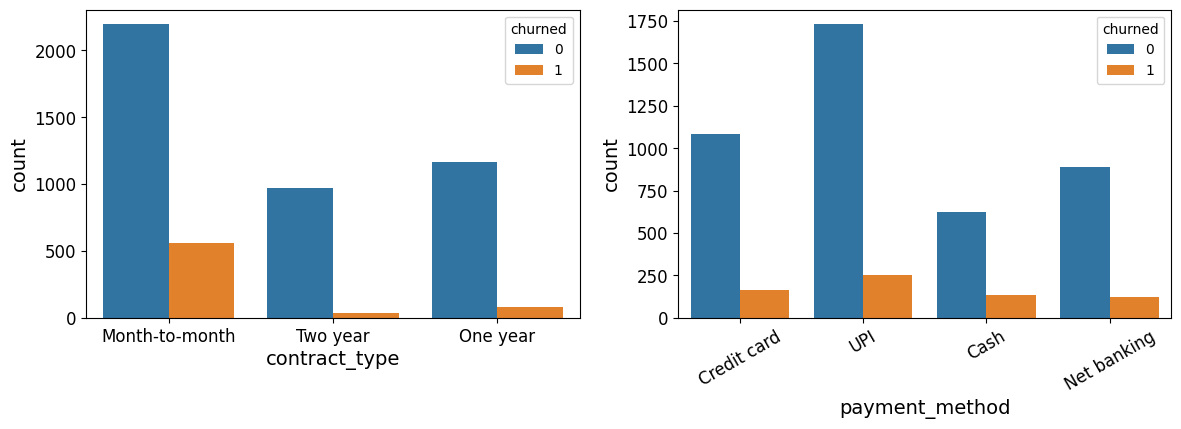

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x="contract_type", hue="churned", ax=axes[0])
sns.countplot(data=df, x="payment_method", hue="churned", ax=axes[1])
axes[1].tick_params(axis="x", rotation=30)
plt.show()

Month-to-month customers churn far more often than customers on 1- or 2-year contracts.

**Data processing** — convert the three categorical columns to dummy (0/1) columns.

> **Code explained:** `pd.get_dummies` turns the three text columns into 0/1 columns (`drop_first=True` avoids a redundant column).

In [ ]:
pre_df = pd.get_dummies(df, columns=["contract_type", "payment_method", "internet_service"], drop_first=True)
pre_df.head()

,tenure_months,senior_citizen,monthly_charges,total_charges,support_calls,churned,contract_type_One year,contract_type_Two year,payment_method_Credit card,payment_method_Net banking,payment_method_UPI,internet_service_Fiber,internet_service_No internet
0,42,0,362.72,14832.49,1,0,False,False,True,False,False,False,True
1,5,0,788.14,4006.41,2,0,False,True,False,False,True,True,False
2,42,1,711.13,28976.68,1,0,False,False,False,False,True,False,False
3,3,0,720.08,2064.97,1,1,False,False,True,False,False,False,False
4,65,0,952.37,63810.80,3,0,False,False,False,False,True,True,False


> **Code explained:** Separates features and target, then makes a 70/30 split with `stratify=y` so both parts keep the same churn rate.

In [ ]:
X = pre_df.drop("churned", axis=1)
y = pre_df["churned"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=5, stratify=y)
print(X_train.shape, X_test.shape)

(3500, 12) (1500, 12)


**Model building and training** (default hyper-parameters)

> **Code explained:** Trains a default `GaussianNB` and prints the class priors it learned from the data.

In [ ]:
model = GaussianNB()
model.fit(X_train, y_train)
print("Learned class priors:", model.class_prior_.round(3))

Learned class priors: [0.866 0.134]


**Model evaluation**

> **Code explained:** Predicts the test set and prints accuracy and weighted F1.

In [ ]:
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("F1 Score (weighted):", round(f1_score(y_test, y_pred, average="weighted"), 4))

Accuracy: 0.864
F1 Score (weighted): 0.8143


> **Code explained:** Confusion matrix for churn (Stayed vs Churned).

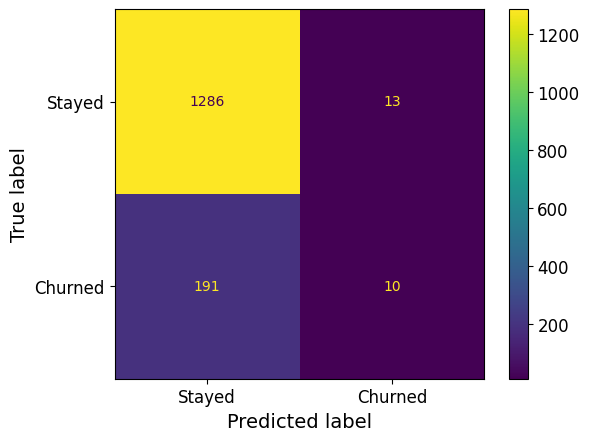

In [ ]:
labels = ["Stayed", "Churned"]
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot();

> **Code explained:** Prints a full classification report. For imbalanced data, precision and recall of the **minority** class matter more than accuracy.

In [ ]:
print(classification_report(y_test, y_pred, target_names=labels))

              precision    recall  f1-score   support

      Stayed       0.87      0.99      0.93      1299
     Churned       0.43      0.05      0.09       201

    accuracy                           0.86      1500
   macro avg       0.65      0.52      0.51      1500
weighted avg       0.81      0.86      0.81      1500



Accuracy can look fine on imbalanced data. The number to check is the **recall for "Churned"**: it tells how many of the customers who really leave the model catches. That is the class the business cares about.

**Variation: equal class priors**

GaussianNB multiplies the likelihood by the prior P(class). With the learned priors, "Stayed" starts with a big advantage. Setting `priors=[0.5, 0.5]` removes that advantage.

> **Code explained:** Trains a second model with **equal priors** (`priors=[0.5, 0.5]`), so 'Stayed' no longer gets a head start, then shows its confusion matrix and report.

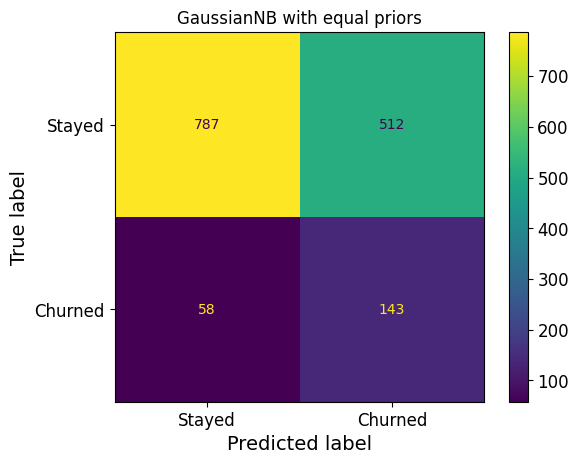

              precision    recall  f1-score   support

      Stayed       0.93      0.61      0.73      1299
     Churned       0.22      0.71      0.33       201

    accuracy                           0.62      1500
   macro avg       0.57      0.66      0.53      1500
weighted avg       0.84      0.62      0.68      1500



In [ ]:
balanced_model = GaussianNB(priors=[0.5, 0.5])
balanced_model.fit(X_train, y_train)
y_pred_bal = balanced_model.predict(X_test)

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred_bal), display_labels=labels).plot();
plt.title("GaussianNB with equal priors")
plt.show()
print(classification_report(y_test, y_pred_bal, target_names=labels))

> **Code explained:** Builds a table comparing accuracy, churn precision and churn recall of both models.

In [ ]:
comparison = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_bal)],
    "Churn precision": [precision_score(y_test, y_pred), precision_score(y_test, y_pred_bal)],
    "Churn recall": [recall_score(y_test, y_pred), recall_score(y_test, y_pred_bal)],
}, index=["Learned priors", "Equal priors"]).round(3)
comparison

,Accuracy,Churn precision,Churn recall
Learned priors,0.864,0.435,0.050
Equal priors,0.620,0.218,0.711


Equal priors usually push churn **recall** up a lot, but at a price: more loyal customers get flagged too, so precision and overall accuracy fall. Neither extreme is ideal.

**Variation: choose the decision threshold instead**

`predict` labels a customer "Churned" when P(churn) > 0.5. Using `predict_proba` from the original model we can try lower thresholds and pick the trade-off we want.

> **Code explained:** Instead of `predict` (threshold 0.5), we use `predict_proba` and try several lower thresholds. The table shows the trade-off between customers flagged, precision and recall.

In [ ]:
p_churn = model.predict_proba(X_test)[:, 1]
rows = []
for threshold in [0.5, 0.35, 0.25, 0.18, 0.12]:
    pred = (p_churn >= threshold).astype(int)
    rows.append([threshold, accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred), int(pred.sum())])
pd.DataFrame(rows, columns=["Threshold", "Accuracy", "Churn precision", "Churn recall",
                            "Customers flagged"]).round(3)

,Threshold,Accuracy,Churn precision,Churn recall,Customers flagged
0,0.50,0.864,0.435,0.050,23
1,0.35,0.848,0.374,0.199,107
2,0.25,0.784,0.290,0.423,293
3,0.18,0.699,0.246,0.602,492
4,0.12,0.586,0.210,0.756,724


For a retention campaign, a moderate threshold is usually preferred: calling a customer who wasn't going to leave costs a little, losing one who was costs a lot.

---
## Lab 8 summary
| | Part A (Wine) | Part B (Churn) |
|---|---|---|
| Classes | 3, roughly balanced | 2, imbalanced |
| Preprocessing | none | `get_dummies(drop_first=True)` |
| Best metric to watch | accuracy / weighted F1 | recall & precision of the minority class |
| Variation | `predict_proba`, per-class means `theta_`, `var_smoothing` experiment | `priors=[0.5, 0.5]`, threshold tuning |

---

# Lab 9 — Ensemble Learning (Voting, Bagging, Random Forest, AdaBoost)

An **ensemble** combines many models to get a better one than any single member.

| Method | Idea |
|---|---|
| Voting | different models vote (hard) or average their probabilities (soft) |
| Bagging | same model on random bootstrap samples, then vote |
| Random Forest | bagging of trees + random feature subsets |
| AdaBoost | weak learners trained one after another, focusing on earlier mistakes |

| | Part A | Part B |
|---|---|---|
| Data | Synthetic 2-D data (can be drawn) | Breast Cancer Wisconsin (real, 30 features) |

**Our own addition (Part B):** how many trees does a Random Forest really need? We train forests with 5 to 400 trees and compare out-of-bag and test accuracy.

> **Code explained:** Imports the ensemble classes, base models, pipelines, scaler and accuracy metric. It also hides one harmless scikit-learn warning about `SVC(probability=True)` so the output stays clean.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import (RandomForestClassifier, VotingClassifier, BaggingClassifier,
                              AdaBoostClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# scikit-learn >= 1.9 warns that SVC(probability=True) will be replaced by CalibratedClassifierCV.
# It still works (and is what older versions expect), so we hide that one warning.
import warnings
warnings.filterwarnings("ignore", message=".*probability.*deprecated", category=FutureWarning)

---
# Part A — Synthetic 2-D Data

## 0. Explore the dataset and split it

> **Code explained:** Creates a 2-feature dataset where each class consists of two clusters and 7% of labels are noisy, then splits it and plots it. Two features mean we can later draw decision boundaries.

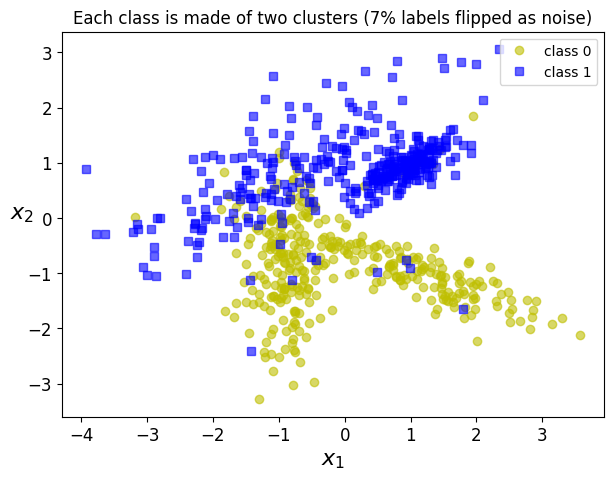

train = 525, test = 175


In [ ]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=700, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=2, class_sep=0.9, flip_y=0.07, random_state=11)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5)

plt.figure(figsize=(7, 5))
plt.plot(X[:, 0][y == 0], X[:, 1][y == 0], "yo", alpha=0.6, label="class 0")
plt.plot(X[:, 0][y == 1], X[:, 1][y == 1], "bs", alpha=0.6, label="class 1")
plt.xlabel(r"$x_1$", fontsize=16)
plt.ylabel(r"$x_2$", fontsize=16, rotation=0)
plt.legend()
plt.title("Each class is made of two clusters (7% labels flipped as noise)")
plt.show()
print(f"train = {len(X_train)}, test = {len(X_test)}")

## 1. Voting Classifier
Train three different classifiers and let them vote.

> **Code explained:** Builds a **hard-voting** ensemble of Logistic Regression, Random Forest and SVC — each model gets one vote and the majority wins — and prints its accuracy.

In [ ]:
log_clf = LogisticRegression(random_state=42)
rnd_clf = RandomForestClassifier(random_state=42)
svm_clf = SVC(random_state=42)

voting_clf = VotingClassifier(
    estimators=[("lr", log_clf), ("rf", rnd_clf), ("sv", svm_clf)],
    voting="hard")
voting_clf.fit(X_train, y_train)

ensemble_y_pred = voting_clf.predict(X_test)
print("Hard-voting ensemble accuracy:", accuracy_score(y_test, ensemble_y_pred))

Hard-voting ensemble accuracy: 0.8971428571428571


Comparing the accuracy of the individual classifiers with the ensemble:

> **Code explained:** Prints the test accuracy of each individual model and of the voting ensemble, so we can see whether voting helps.

In [ ]:
for clf in (log_clf, rnd_clf, svm_clf, voting_clf):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(f"{clf.__class__.__name__:24s} {accuracy_score(y_test, y_pred):.3f}")

LogisticRegression       0.857
RandomForestClassifier   0.886
SVC                      0.909
VotingClassifier         0.897


**Variation — soft voting:** average the predicted class probabilities instead of counting votes. `SVC` needs `probability=True` to provide probabilities.

> **Code explained:** **Soft voting**: instead of counting votes, average the predicted class probabilities (the SVC needs `probability=True` for this).

In [ ]:
soft_voting_clf = VotingClassifier(
    estimators=[("lr", LogisticRegression(random_state=42)),
                ("rf", RandomForestClassifier(random_state=42)),
                ("sv", SVC(probability=True, random_state=42))],
    voting="soft")
soft_voting_clf.fit(X_train, y_train)
print("Soft-voting ensemble accuracy:", accuracy_score(y_test, soft_voting_clf.predict(X_test)))

Soft-voting ensemble accuracy: 0.8971428571428571


## 2. Bagging Classifier
300 decision trees, each trained on 120 random samples **drawn with replacement** (bootstrap). Because each tree never sees roughly a third of the training samples, those *out-of-bag* samples give a free validation score.

> **Code explained:** **Bagging** with 300 trees, each on 120 random samples drawn *with replacement*. `oob_score=True` gives a free validation score from the samples each tree did not see. **Pasting** (without replacement) and a single tree are shown for comparison.

In [ ]:
bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, max_samples=120,
                            bootstrap=True, oob_score=True, n_jobs=-1, random_state=42)
bag_clf.fit(X_train, y_train)
y_pred = bag_clf.predict(X_test)
print(f"Bagging test accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Bagging OOB score     : {bag_clf.oob_score_:.3f}   (estimated without touching the test set)")

# Variation: pasting = sampling WITHOUT replacement
paste_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, max_samples=120,
                              bootstrap=False, n_jobs=-1, random_state=42)
paste_clf.fit(X_train, y_train)
print(f"Pasting test accuracy : {accuracy_score(y_test, paste_clf.predict(X_test)):.3f}")

single_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print(f"Single tree test acc  : {accuracy_score(y_test, single_tree.predict(X_test)):.3f}")

Bagging test accuracy : 0.891
Bagging OOB score     : 0.922   (estimated without touching the test set)
Pasting test accuracy : 0.891
Single tree test acc  : 0.834


## 3. Random Forest Classifier
A random forest = bagging of decision trees + a random subset of features considered at every split.

> **Code explained:** A Random Forest = bagging of decision trees + a random subset of features at each split. `max_leaf_nodes=12` keeps each tree small.

In [ ]:
rnd_clf = RandomForestClassifier(n_estimators=300, max_leaf_nodes=12, n_jobs=-1, random_state=42)
rnd_clf.fit(X_train, y_train)
y_pred = rnd_clf.predict(X_test)
print(f"Random Forest test accuracy: {accuracy_score(y_test, y_pred):.3f}")

Random Forest test accuracy: 0.880


## 4. AdaBoost with 150 Decision Stumps
A **decision stump** is a tree with `max_depth=1` (one split, two leaves). AdaBoost trains stumps one after another, each focusing on the samples the previous ones got wrong.

> **Code explained:** **AdaBoost** with 150 decision stumps (trees of depth 1) and a single stump for comparison. Each new stump gives more weight to the samples the previous ones got wrong.

In [ ]:
ada_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=150,
                             learning_rate=0.8, random_state=42)
ada_clf.fit(X_train, y_train)

ds_clf = DecisionTreeClassifier(max_depth=1, random_state=42)
ds_clf.fit(X_train, y_train)

print(f"{ds_clf.__class__.__name__} (single stump) {accuracy_score(y_test, ds_clf.predict(X_test)):.3f}")
print(f"{ada_clf.__class__.__name__} (150 stumps)    {accuracy_score(y_test, ada_clf.predict(X_test)):.3f}")

DecisionTreeClassifier (single stump) 0.851
AdaBoostClassifier (150 stumps)    0.903


### Visualising the decision boundaries

> **Code explained:** A helper that colours the plane by predicted class, then plots the boundary of six models in a 2×3 grid with their test accuracy — a visual comparison of all methods.

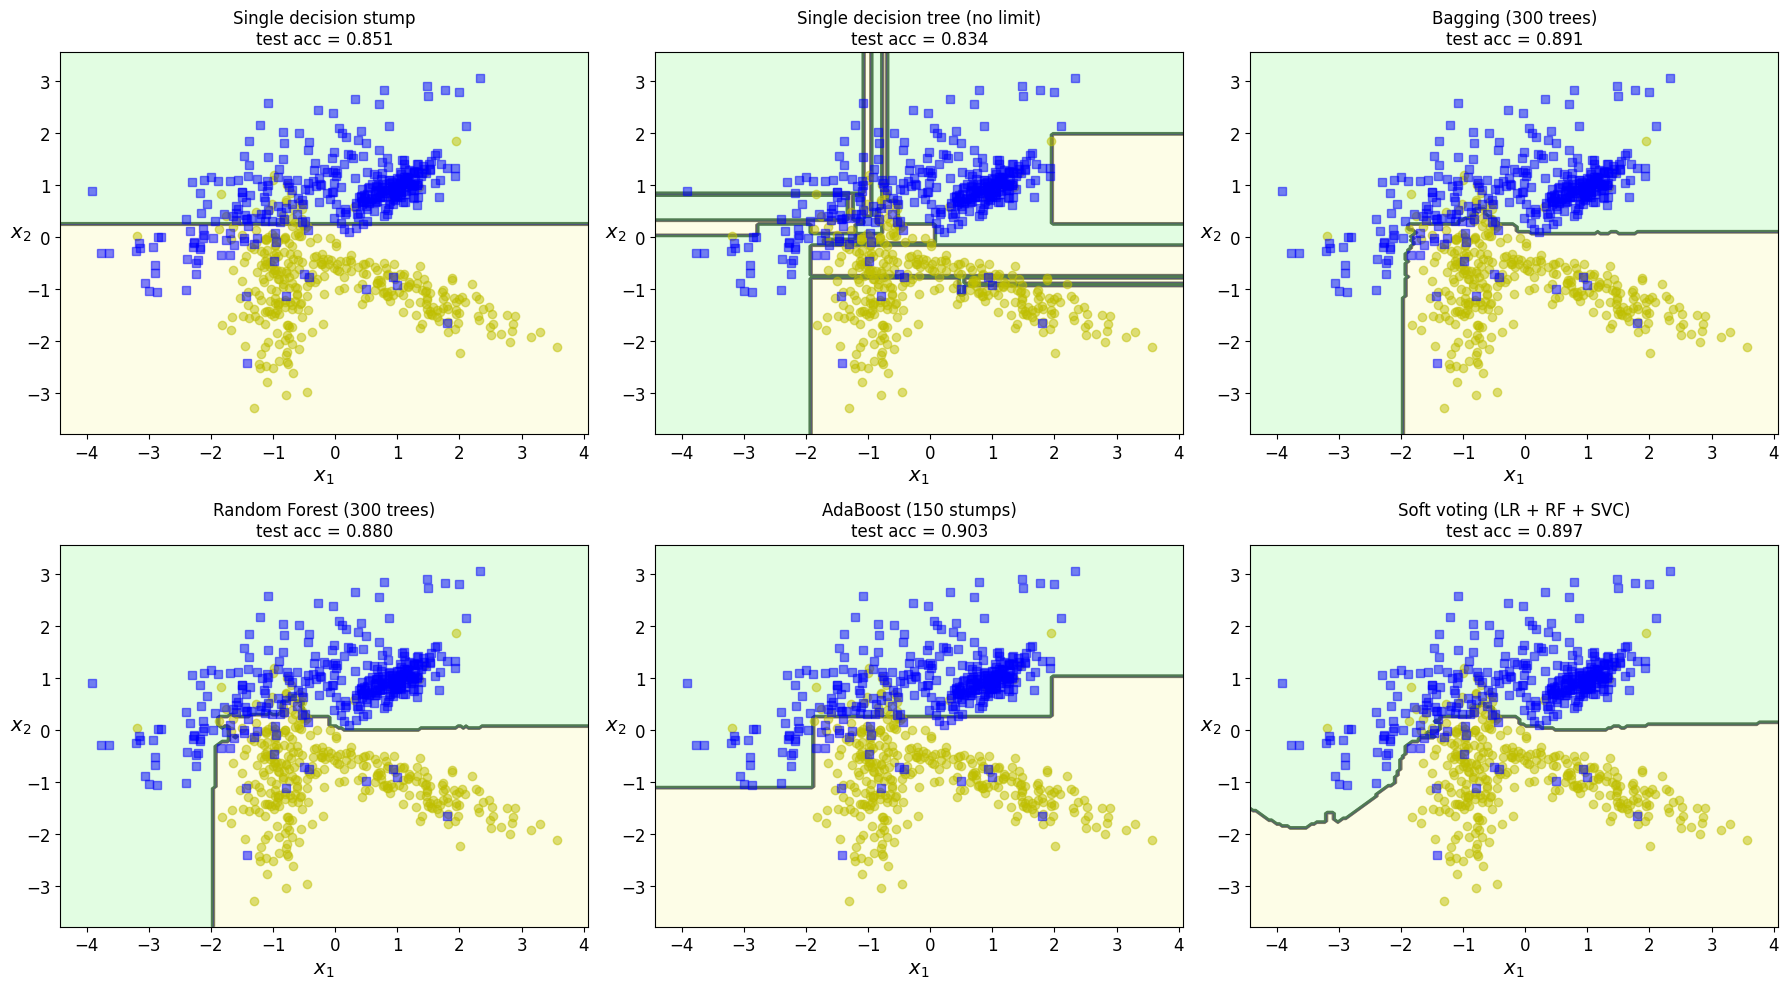

In [ ]:
def plot_decision_boundary(clf, X, y, alpha=0.5, contour=True, ax=None):
    ax = ax or plt.gca()
    pad = 0.5
    axes = [X[:, 0].min() - pad, X[:, 0].max() + pad, X[:, 1].min() - pad, X[:, 1].max() + pad]
    x1s = np.linspace(axes[0], axes[1], 200)
    x2s = np.linspace(axes[2], axes[3], 200)
    x1, x2 = np.meshgrid(x1s, x2s)
    X_new = np.c_[x1.ravel(), x2.ravel()]
    y_pred = clf.predict(X_new).reshape(x1.shape)
    custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
    ax.contourf(x1, x2, y_pred, alpha=0.3, cmap=custom_cmap)
    if contour:
        custom_cmap2 = ListedColormap(["#7d7d58", "#4c4c7f", "#507d50"])
        ax.contour(x1, x2, y_pred, cmap=custom_cmap2, alpha=0.8)
    ax.plot(X[:, 0][y == 0], X[:, 1][y == 0], "yo", alpha=alpha)
    ax.plot(X[:, 0][y == 1], X[:, 1][y == 1], "bs", alpha=alpha)
    ax.axis(axes)
    ax.set_xlabel(r"$x_1$", fontsize=14)
    ax.set_ylabel(r"$x_2$", fontsize=14, rotation=0)

models_to_plot = [("Single decision stump", ds_clf), ("Single decision tree (no limit)", single_tree),
                  ("Bagging (300 trees)", bag_clf), ("Random Forest (300 trees)", rnd_clf),
                  ("AdaBoost (150 stumps)", ada_clf), ("Soft voting (LR + RF + SVC)", soft_voting_clf)]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, clf) in zip(axes.ravel(), models_to_plot):
    plot_decision_boundary(clf, X, y, ax=ax)
    ax.set_title(f"{name}\ntest acc = {accuracy_score(y_test, clf.predict(X_test)):.3f}")
plt.tight_layout()
plt.show()

The single stump can only make one straight cut. The unrestricted tree builds a jagged boundary around the noisy points (overfitting). Bagging and Random Forest **average** many trees into a smoother boundary, and AdaBoost **adds up** many stumps into a step-shaped but flexible boundary.

---
# Part B — Breast Cancer Wisconsin (30 features)

## 0. Load and split

> **Code explained:** Loads the Breast Cancer dataset (30 features, malignant vs benign), makes a stratified split and prints shapes and class counts.

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=9)
print(f"X shape: {X.shape} | classes: {cancer.target_names.tolist()} | counts: {np.bincount(y).tolist()}")
print(f"train = {len(X_train)}, test = {len(X_test)}")

X shape: (569, 30) | classes: ['malignant', 'benign'] | counts: [212, 357]
train = 426, test = 143


## 1. Voting Classifier (hard and soft)
Logistic Regression and SVC are sensitive to feature scale, so they are wrapped in a `StandardScaler` pipeline (trees don't need scaling).

> **Code explained:** Hard and soft voting on real data. Logistic Regression and SVC are wrapped in a scaling pipeline (trees don't need scaling). Prints a result for each model.

In [ ]:
log_clf = make_pipeline(StandardScaler(), LogisticRegression(random_state=42))
rnd_clf = RandomForestClassifier(random_state=42)
svm_clf = make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))

results_B = {}
for voting in ["hard", "soft"]:
    vc = VotingClassifier(estimators=[("lr", log_clf), ("rf", rnd_clf), ("sv", svm_clf)], voting=voting)
    vc.fit(X_train, y_train)
    results_B[f"Voting ({voting})"] = accuracy_score(y_test, vc.predict(X_test))

for name, clf in [("Logistic Regression", log_clf), ("Random Forest", rnd_clf), ("SVC", svm_clf)]:
    clf.fit(X_train, y_train)
    results_B[name] = accuracy_score(y_test, clf.predict(X_test))

for name in ["Logistic Regression", "Random Forest", "SVC", "Voting (hard)", "Voting (soft)"]:
    print(f"{name:20s} {results_B[name]:.3f}")

Logistic Regression  0.979
Random Forest        0.958
SVC                  0.972
Voting (hard)        0.972
Voting (soft)        0.972


Compare the voting results with the best single model: the scaled Logistic Regression is usually already very strong here, so voting tends to land close to it rather than beat it. An ensemble helps most when its members are good **and make different mistakes** (as in Part A).

## 2. Bagging Classifier with out-of-bag evaluation

> **Code explained:** Bagging of 300 trees with out-of-bag evaluation and a single decision tree for comparison; results are stored in `results_B`.

In [ ]:
bag_clf = BaggingClassifier(DecisionTreeClassifier(), n_estimators=300, max_samples=120,
                            bootstrap=True, oob_score=True, n_jobs=-1, random_state=42)
bag_clf.fit(X_train, y_train)
results_B["Bagging"] = accuracy_score(y_test, bag_clf.predict(X_test))
print(f"Bagging test accuracy: {results_B['Bagging']:.3f} | OOB score: {bag_clf.oob_score_:.3f}")

single_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
results_B["Single decision tree"] = accuracy_score(y_test, single_tree.predict(X_test))
print(f"Single tree test accuracy: {results_B['Single decision tree']:.3f}")

Bagging test accuracy: 0.958 | OOB score: 0.953
Single tree test accuracy: 0.930


## 3. Random Forest + feature importances

> **Code explained:** Trains a Random Forest, stores its accuracy and plots the 10 most important features.

Random Forest test accuracy: 0.951


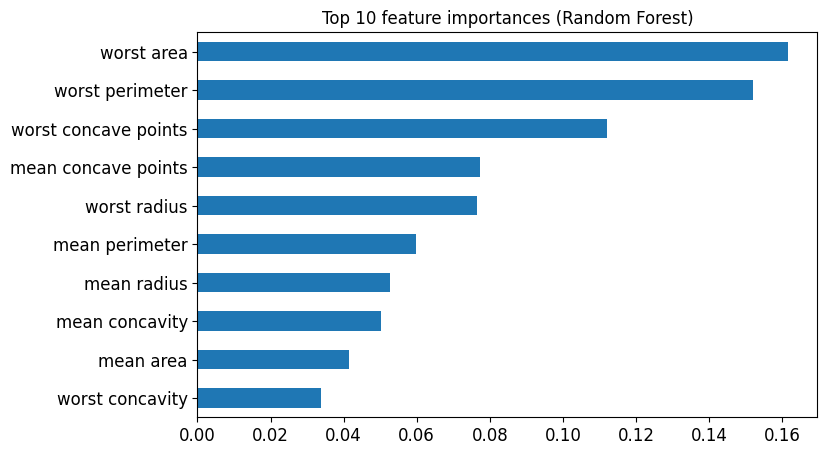

In [ ]:
rnd_clf = RandomForestClassifier(n_estimators=300, max_leaf_nodes=12, n_jobs=-1, random_state=42)
rnd_clf.fit(X_train, y_train)
results_B["Random Forest (300, 12 leaves)"] = accuracy_score(y_test, rnd_clf.predict(X_test))
print(f"Random Forest test accuracy: {results_B['Random Forest (300, 12 leaves)']:.3f}")

importances = pd.Series(rnd_clf.feature_importances_, index=cancer.feature_names).sort_values()
importances.tail(10).plot(kind="barh", figsize=(8, 5), title="Top 10 feature importances (Random Forest)")
plt.show()

### How many trees does a Random Forest need?
More trees usually help, but only up to a point. We train forests with different numbers of trees and compare the free **out-of-bag (OOB)** score with the test accuracy.

> **Code explained:** For each forest size we train a `RandomForestClassifier(oob_score=True)` and store OOB and test accuracy. Very small forests may print harmless warnings that some samples had no OOB prediction, so they are silenced. The plot shows both curves and the last lines report the result.

 trees  OOB accuracy  test accuracy
     5         0.892          0.944
    10         0.927          0.944
    25         0.946          0.958
    50         0.958          0.951
   100         0.962          0.958
   200         0.962          0.958
   400         0.965          0.958


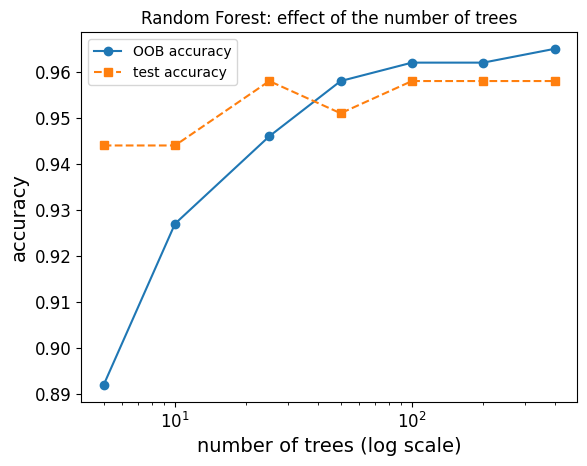


Conclusion: going from 5 to 400 trees changed test accuracy by +0.014; the OOB score (0.965 with 400 trees) is a good no-test-set estimate.


In [ ]:
import warnings

tree_counts = [5, 10, 25, 50, 100, 200, 400]
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for n_trees in tree_counts:
        rf = RandomForestClassifier(n_estimators=n_trees, oob_score=True, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        rows.append([n_trees, rf.oob_score_, rf.score(X_test, y_test)])

forest_table = pd.DataFrame(rows, columns=["trees", "OOB accuracy", "test accuracy"]).round(3)
print(forest_table.to_string(index=False))

plt.plot(forest_table["trees"], forest_table["OOB accuracy"], "o-", label="OOB accuracy")
plt.plot(forest_table["trees"], forest_table["test accuracy"], "s--", label="test accuracy")
plt.xscale("log")
plt.xlabel("number of trees (log scale)")
plt.ylabel("accuracy")
plt.title("Random Forest: effect of the number of trees")
plt.legend()
plt.show()

gain = forest_table["test accuracy"].iloc[-1] - forest_table["test accuracy"].iloc[0]
print(f"\nConclusion: going from {tree_counts[0]} to {tree_counts[-1]} trees changed test accuracy by {gain:+.3f}; "
      f"the OOB score ({forest_table['OOB accuracy'].iloc[-1]:.3f} with {tree_counts[-1]} trees) is a good no-test-set estimate.")

**Conclusion:** accuracy rises quickly over the first few dozen trees and then flattens — adding hundreds more trees costs time but gains almost nothing. The OOB score follows the test accuracy closely, so it is a handy way to judge a forest without touching the test set.

## 4. AdaBoost with 150 Decision Stumps vs a single stump
With 30 features we can't draw a 2-D boundary, so instead we plot **test accuracy after each boosting round**.

> **Code explained:** AdaBoost with 150 stumps vs a single stump; also prints which feature the single stump splits on.

In [ ]:
ada_clf = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=150,
                             learning_rate=0.8, random_state=42)
ada_clf.fit(X_train, y_train)
ds_clf = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_train, y_train)

results_B["Decision stump"] = accuracy_score(y_test, ds_clf.predict(X_test))
results_B["AdaBoost (150 stumps)"] = accuracy_score(y_test, ada_clf.predict(X_test))
print(f"DecisionTreeClassifier (single stump) {results_B['Decision stump']:.3f}")
print(f"AdaBoostClassifier (150 stumps)       {results_B['AdaBoost (150 stumps)']:.3f}")
print(f"\nThe single stump splits on: '{cancer.feature_names[ds_clf.tree_.feature[0]]}' "
      f"<= {ds_clf.tree_.threshold[0]:.3f}")

DecisionTreeClassifier (single stump) 0.902
AdaBoostClassifier (150 stumps)       0.972

The single stump splits on: 'worst perimeter' <= 110.400


> **Code explained:** Uses `staged_predict` to get the accuracy after every boosting round and plots training vs test accuracy as stumps are added.

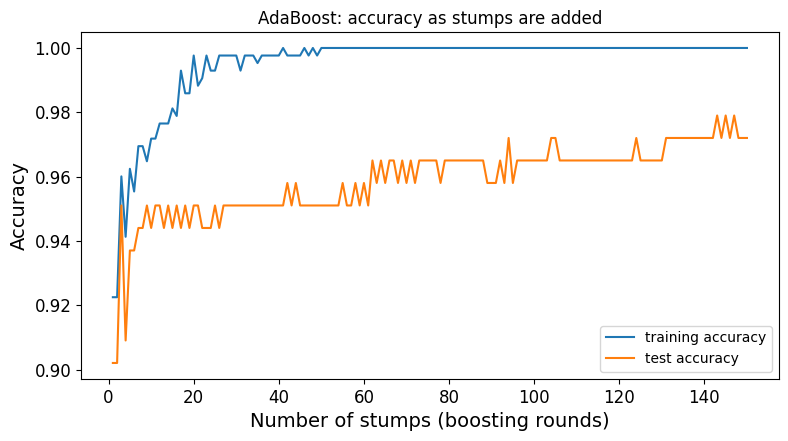

Best test accuracy 0.979 reached after 143 stumps


In [ ]:
staged_test = [accuracy_score(y_test, p) for p in ada_clf.staged_predict(X_test)]
staged_train = [accuracy_score(y_train, p) for p in ada_clf.staged_predict(X_train)]

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(staged_train) + 1), staged_train, label="training accuracy")
plt.plot(range(1, len(staged_test) + 1), staged_test, label="test accuracy")
plt.xlabel("Number of stumps (boosting rounds)")
plt.ylabel("Accuracy")
plt.title("AdaBoost: accuracy as stumps are added")
plt.legend()
plt.show()
print(f"Best test accuracy {max(staged_test):.3f} reached after {int(np.argmax(staged_test)) + 1} stumps")

## Final comparison (Dataset B)

> **Code explained:** Puts the test accuracy of every model into one sorted table — the final comparison.

In [ ]:
pd.Series(results_B, name="Test accuracy").sort_values(ascending=False).round(3).to_frame()

,Test accuracy
Logistic Regression,0.979
Voting (hard),0.972
Voting (soft),0.972
SVC,0.972
AdaBoost (150 stumps),0.972
Random Forest,0.958
Bagging,0.958
"Random Forest (300, 12 leaves)",0.951
Single decision tree,0.930
Decision stump,0.902


---
## Lab 9 summary
| Method | Idea | Reduces mainly | Variation tried |
|---|---|---|---|
| Voting | different models vote (hard) or average probabilities (soft) | errors of individual models | soft voting |
| Bagging | same model on bootstrap samples, then vote | **variance** | OOB score, pasting |
| Random Forest | bagging + random feature subsets at each split | **variance** | feature importances, **number of trees (our addition)** |
| AdaBoost | sequential weak learners, re-weighting mistakes | **bias** | accuracy per boosting round |

---

# Lab 10 — Feed-Forward Neural Network with Keras

A neural network is layers of small units; each unit takes a weighted sum of its inputs and applies an activation (e.g. ReLU). Training adjusts the weights with gradient descent.

| | Part A | Part B |
|---|---|---|
| Data | **Fashion-MNIST** (70,000 clothing images, 28×28) | sklearn **Digits** (1,797 images, 8×8) |
| Network | Dense(256, relu) → Dense(10, softmax) | Dense(48) → Dropout(0.25) → Dense(24) → Dense(10, softmax) |
| Optimizer / loss | `adam` / `categorical_crossentropy` (one-hot labels) | `adam` / `sparse_categorical_crossentropy` (integer labels) |
| Extras | validation split, confusion matrix | EarlyStopping, Dropout, learning curves |

**Our own addition (end of lab):** we compare three **optimizers** (`adam`, `rmsprop`, `sgd`) on the Digits network.

> Fashion-MNIST is downloaded automatically by Keras the first time (≈30 MB). The Digits dataset ships with scikit-learn.

### Step 1 — Setting up Keras and NumPy

> **Code explained:** Imports NumPy, Matplotlib, TensorFlow/Keras and `to_categorical`. `set_random_seed(42)` makes weight initialisation and shuffling repeatable.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers
from tensorflow.keras.utils import to_categorical

keras.utils.set_random_seed(42)   # reproducible weight initialisation & shuffling
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


---
# Part A — Fashion-MNIST: Clothing Recognition

**Problem Description:** Build a neural network in Keras and train it on Fashion-MNIST to recognise 10 kinds of clothing. Evaluate it on the test set.

### Step 2 — Load the Fashion-MNIST dataset

> **Code explained:** Downloads (first time only) and loads Fashion-MNIST: 60,000 training and 10,000 test images with labels 0–9, and defines the readable class names.

In [ ]:
from tensorflow.keras.datasets import fashion_mnist
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Step 3 — Have a look at the data

> **Code explained:** Prints the array shapes, the pixel value range, the label of one image and the number of images per class.

In [ ]:
print("train_images.shape:", train_images.shape)
print("test_images.shape :", test_images.shape)
print("dtype:", train_images.dtype, "| pixel range:", train_images.min(), "-", train_images.max())
print("Label of image 4:", train_labels[4], "->", class_names[train_labels[4]])
print("Images per class in training set:", np.bincount(train_labels))

train_images.shape: (60000, 28, 28)
test_images.shape : (10000, 28, 28)
dtype: uint8 | pixel range: 0 - 255
Label of image 4: 0 -> T-shirt/top
Images per class in training set: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


> **Code explained:** Shows one training image with its class name and a colour bar of pixel intensities.

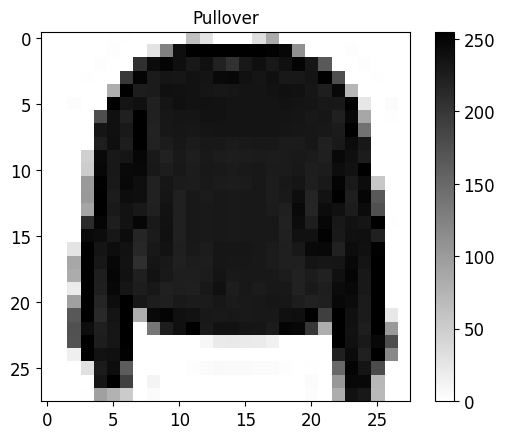

In [ ]:
# Plot one sample image
i = 7
plt.imshow(train_images[i], cmap=plt.cm.binary)
plt.title(class_names[train_labels[i]])
plt.colorbar()
plt.show()

> **Code explained:** Plots the first 15 training images with their class names in a 3×5 grid.

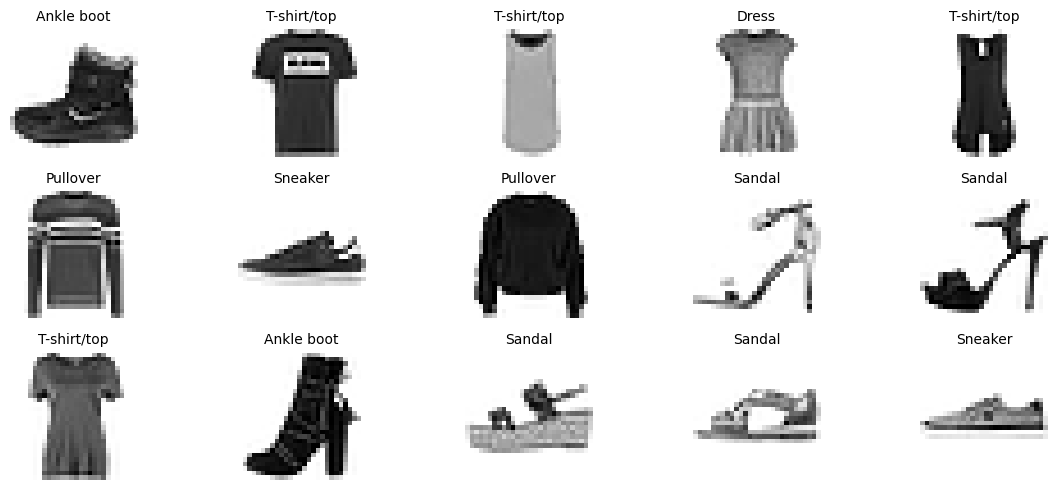

In [ ]:
# Plot the first 15 training images with their class names
plt.figure(figsize=(12, 5))
for k in range(15):
    plt.subplot(3, 5, k + 1)
    plt.imshow(train_images[k], cmap=plt.cm.binary)
    plt.title(class_names[train_labels[k]], fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Step 4 — Build the layered Neural Network model
784 inputs → 256 ReLU units → 10 softmax outputs.

> **Code explained:** Builds the model: input of 784 values → one hidden layer of 256 ReLU units → 10 softmax outputs (one probability per class). `summary()` lists layers and parameter counts.

In [ ]:
network = models.Sequential([
    layers.Input(shape=(28 * 28,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

Parameters: (784 × 256 + 256) + (256 × 10 + 10) = 200,960 + 2,570 = **203,530**.

### Step 5 — Compile the model

> **Code explained:** Compiles the model: the **optimizer** (`adam`) updates the weights, the **loss** (`categorical_crossentropy`) measures the error for one-hot labels, and **accuracy** is tracked as a metric.

In [ ]:
network.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

### Step 6 — Input data preparation
Flatten each 28×28 image into a vector of 784 values and scale pixels from 0–255 to 0–1.

> **Code explained:** Flattens each 28×28 image to 784 numbers and scales pixels from 0–255 to 0–1 (networks train better on small values). Labels are converted to **one-hot** vectors.

In [ ]:
train_images = train_images.reshape((60000, 28 * 28)).astype("float32") / 255
test_images = test_images.reshape((10000, 28 * 28)).astype("float32") / 255

print(train_labels[0], test_labels[0])

# Prepare the labels using One-Hot Encoding (fixed import)
train_labels_oh = to_categorical(train_labels)
test_labels_oh = to_categorical(test_labels)
print(train_labels_oh[0])

9 9
[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### Step 7 — Train the network
15% of the training images are held back as a validation set, so we can watch for overfitting.

> **Code explained:** Trains for 6 epochs in batches of 256, holding back 15% of the training data as a validation set so we can watch for overfitting.

In [ ]:
history = network.fit(train_images, train_labels_oh, epochs=6, batch_size=256,
                      validation_split=0.15, verbose=2)

Epoch 1/6
200/200 - 4s - 21ms/step - accuracy: 0.7956 - loss: 0.5919 - val_accuracy: 0.8270 - val_loss: 0.4934
Epoch 2/6
200/200 - 2s - 10ms/step - accuracy: 0.8551 - loss: 0.4147 - val_accuracy: 0.8476 - val_loss: 0.4394
Epoch 3/6
200/200 - 2s - 10ms/step - accuracy: 0.8690 - loss: 0.3734 - val_accuracy: 0.8578 - val_loss: 0.3988
Epoch 4/6
200/200 - 2s - 10ms/step - accuracy: 0.8790 - loss: 0.3435 - val_accuracy: 0.8683 - val_loss: 0.3740
Epoch 5/6
200/200 - 3s - 14ms/step - accuracy: 0.8852 - loss: 0.3216 - val_accuracy: 0.8727 - val_loss: 0.3608
Epoch 6/6
200/200 - 4s - 18ms/step - accuracy: 0.8916 - loss: 0.3048 - val_accuracy: 0.8761 - val_loss: 0.3502


### Step 8 — Evaluate on the test data

> **Code explained:** Evaluates the trained network on the 10,000 unseen test images and prints loss and accuracy.

In [ ]:
test_loss, test_acc = network.evaluate(test_images, test_labels_oh, verbose=0)
print("test loss    :", round(test_loss, 4))
print("test accuracy:", round(test_acc, 4))

test loss    : 0.3682
test accuracy: 0.8672


Fashion-MNIST is harder than the classic MNIST digits: the same kind of network that reaches about 98% on digits usually lands in the high 80s here, mostly because shirts, T-shirts, pullovers and coats look alike.

### Step 9 — Use the trained model to predict

> **Code explained:** Predicts one test image: shows the 10 class probabilities, the predicted vs actual class, and the image.

Probabilities: [[0.    0.    0.    0.    0.    0.007 0.    0.054 0.001 0.938]]
Predicted class: Ankle boot | Actual: Ankle boot


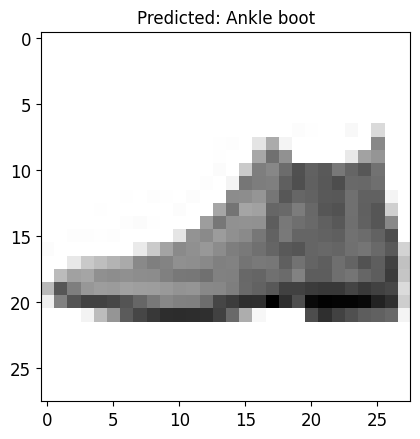

In [ ]:
probs = network.predict(test_images[0:1], verbose=0)
print("Probabilities:", probs.round(3))
print("Predicted class:", class_names[np.argmax(probs)], "| Actual:", class_names[test_labels[0]])

plt.imshow(test_images[0].reshape(28, 28), cmap=plt.cm.binary)
plt.title(f"Predicted: {class_names[np.argmax(probs)]}")
plt.show()

> **Code explained:** Predicts the first 20 test images and shows them in a grid with the title in green if correct and red if wrong.

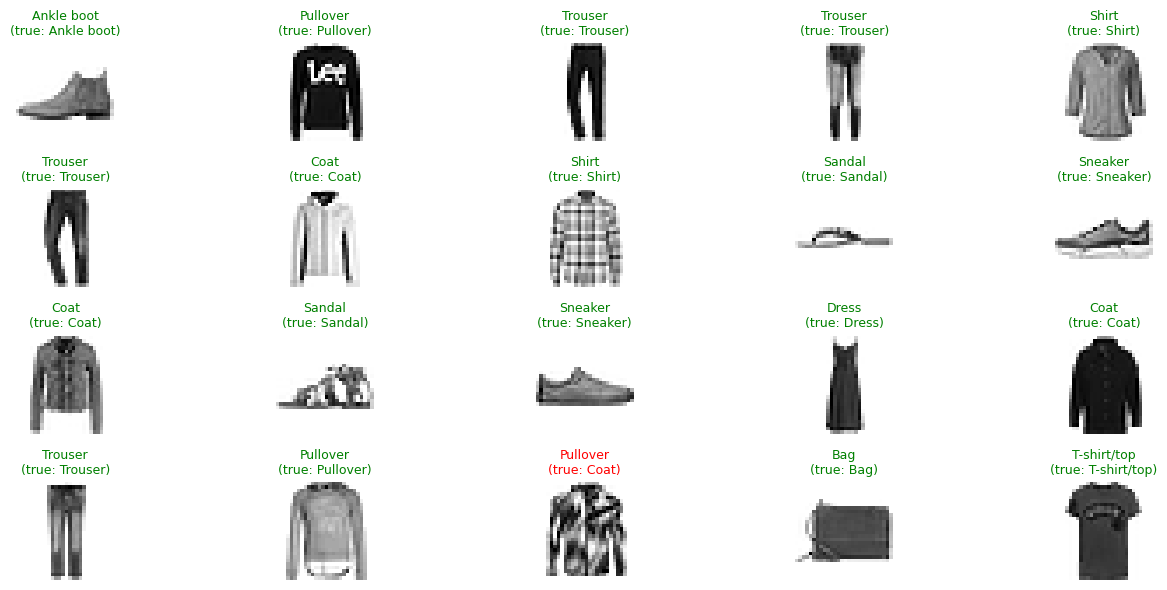

In [ ]:
# Variation: a grid of predictions (green = correct, red = wrong)
pred_labels = np.argmax(network.predict(test_images[:20], verbose=0), axis=1)
plt.figure(figsize=(14, 6))
for k in range(20):
    plt.subplot(4, 5, k + 1)
    plt.imshow(test_images[k].reshape(28, 28), cmap=plt.cm.binary)
    colour = "green" if pred_labels[k] == test_labels[k] else "red"
    plt.title(f"{class_names[pred_labels[k]]}\n(true: {class_names[test_labels[k]]})", color=colour, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

> **Code explained:** Computes predictions for the full test set and draws a confusion matrix, which shows which clothes get confused (e.g. shirt vs T-shirt).

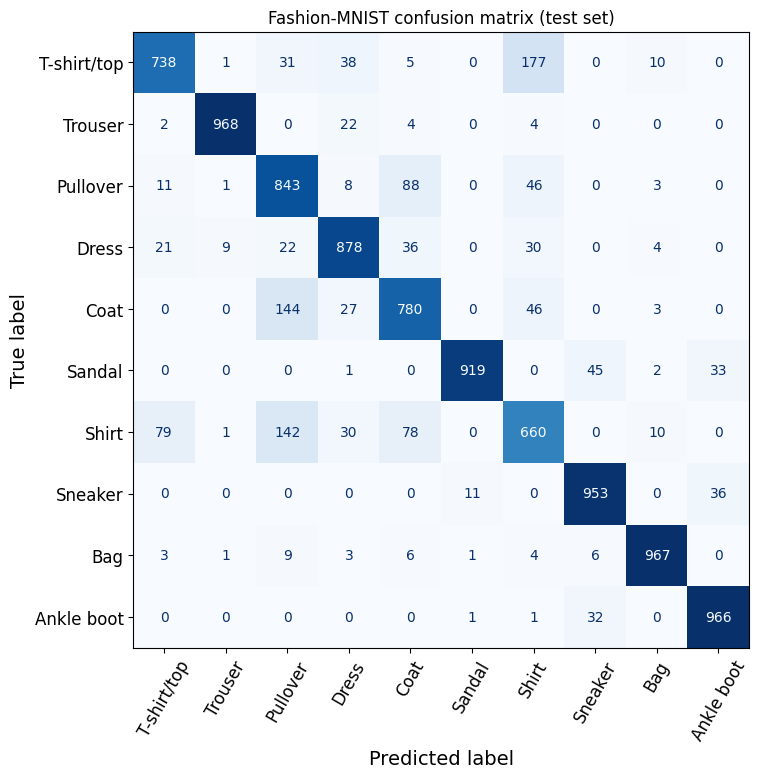

In [ ]:
# Which classes get confused?
from sklearn.metrics import ConfusionMatrixDisplay
all_preds = np.argmax(network.predict(test_images, verbose=0), axis=1)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(test_labels, all_preds, display_labels=class_names,
                                        xticks_rotation=60, cmap="Blues", ax=ax, colorbar=False)
plt.title("Fashion-MNIST confusion matrix (test set)")
plt.show()

---
# Part B — sklearn Digits (8×8 handwritten digits)

**Problem Description:** Recognise handwritten digits from the small 8×8 Digits dataset (1,797 images). With so little data a large network would overfit, so we use a smaller network with Dropout and early stopping.

### Step 2 — Load the data and split it

> **Code explained:** Loads the sklearn Digits dataset (8×8 images), checks shapes and pixel range, and makes a stratified 75/25 train/test split.

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
print("images shape:", digits.images.shape, "| pixel range:", digits.images.min(), "-", digits.images.max())

X_train, X_test, y_train, y_test = train_test_split(
    digits.images, digits.target, test_size=0.25, stratify=digits.target, random_state=3)
print("train:", X_train.shape, "test:", X_test.shape)

images shape: (1797, 8, 8) | pixel range: 0.0 - 16.0
train: (1347, 8, 8) test: (450, 8, 8)


### Step 3 — Have a look at the data

> **Code explained:** Prints one raw image array and its label and displays the first 10 training digits.

[[ 0.  0. 12. 16. 15.  6.  0.  0.]
 [ 0.  0. 15. 12.  7. 15.  1.  0.]
 [ 0.  1. 15. 15.  7. 16.  4.  0.]
 [ 0.  1. 12. 16. 16. 14.  1.  0.]
 [ 0.  0.  0.  4. 10. 13.  0.  0.]
 [ 0.  0.  0.  0.  1. 15.  3.  0.]
 [ 0.  0.  3.  0.  2. 16.  6.  0.]
 [ 0.  0. 13. 16. 16. 15.  1.  0.]]
label: 9


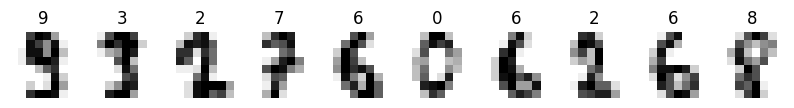

In [ ]:
print(X_train[0])
print("label:", y_train[0])

plt.figure(figsize=(10, 2.5))
for k in range(10):
    plt.subplot(1, 10, k + 1)
    plt.imshow(X_train[k], cmap=plt.cm.binary)
    plt.title(y_train[k])
    plt.axis("off")
plt.show()

### Step 4 — Build a smaller network with Dropout
`Dropout(0.25)` randomly switches off 25% of the units at each training step, which stops the network from relying on any single unit (regularisation).

> **Code explained:** Builds a smaller network with **Dropout**, which randomly switches off 25% of units during training so the network doesn't depend too much on any one unit.

In [ ]:
digit_net = models.Sequential([
    layers.Input(shape=(8 * 8,)),
    layers.Dense(48, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(24, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
digit_net.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 48)             │         3,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         1,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,546 (17.76 KB)

 Trainable params: 4,546 (17.76 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5 — Compile: `adam` + `sparse_categorical_crossentropy`
The *sparse* loss accepts integer labels (0–9) directly, so **no one-hot encoding** is needed.

> **Code explained:** Compiles with `adam` and `sparse_categorical_crossentropy`, which accepts integer labels directly (no one-hot needed).

In [ ]:
digit_net.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

### Step 6 — Prepare the inputs
Pixels in this dataset range from 0 to **16** (not 255), so we divide by 16.

> **Code explained:** Flattens the 8×8 images to 64 values and divides by 16 (the maximum pixel value in this dataset).

In [ ]:
X_train_flat = X_train.reshape((len(X_train), 64)).astype("float32") / 16
X_test_flat = X_test.reshape((len(X_test), 64)).astype("float32") / 16
print(X_train_flat.shape, X_train_flat.min(), X_train_flat.max())

(1347, 64) 0.0 1.0


### Step 7 — Train with early stopping
Training stops when the validation loss hasn't improved for 8 epochs, and the best weights are restored.

> **Code explained:** Trains with **EarlyStopping**: training stops when the validation loss has not improved for 8 epochs and the best weights are restored.

In [ ]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
history_b = digit_net.fit(X_train_flat, y_train, epochs=150, batch_size=32,
                          validation_split=0.2, callbacks=[early_stop], verbose=0)
print(f"Stopped after {len(history_b.history['loss'])} epochs")
print(f"Final training accuracy  : {history_b.history['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {history_b.history['val_accuracy'][-1]:.4f}")

Stopped after 81 epochs
Final training accuracy  : 0.9889
Final validation accuracy: 0.9630


> **Code explained:** Plots training vs validation loss and accuracy per epoch (learning curves). A growing gap between the curves signals overfitting.

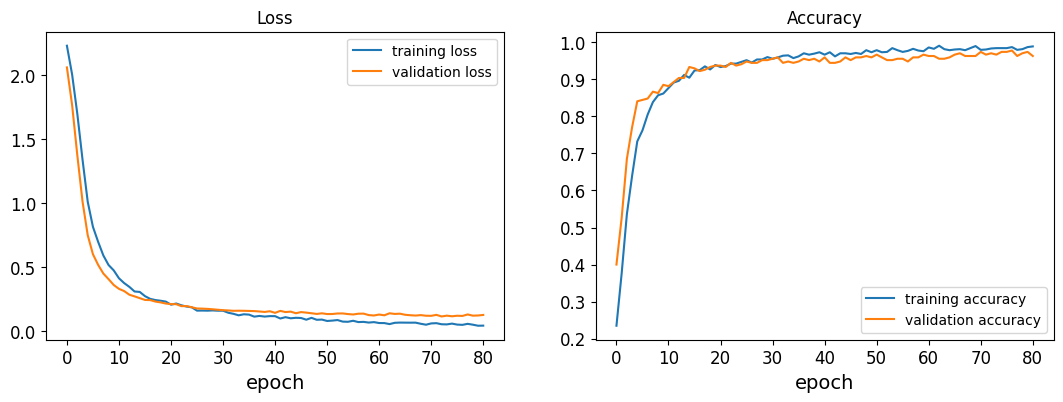

In [ ]:
# Learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_b.history["loss"], label="training loss")
axes[0].plot(history_b.history["val_loss"], label="validation loss")
axes[0].set_xlabel("epoch")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history_b.history["accuracy"], label="training accuracy")
axes[1].plot(history_b.history["val_accuracy"], label="validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_title("Accuracy")
axes[1].legend()
plt.show()

### Step 8 — Evaluate on the test data

> **Code explained:** Evaluates the network on the test set and prints loss and accuracy.

In [ ]:
test_loss_b, test_acc_b = digit_net.evaluate(X_test_flat, y_test, verbose=0)
print("test loss    :", round(test_loss_b, 4))
print("test accuracy:", round(test_acc_b, 4))

test loss    : 0.0845
test accuracy: 0.9733


> **Code explained:** Draws the confusion matrix of the digit classifier on the test set.

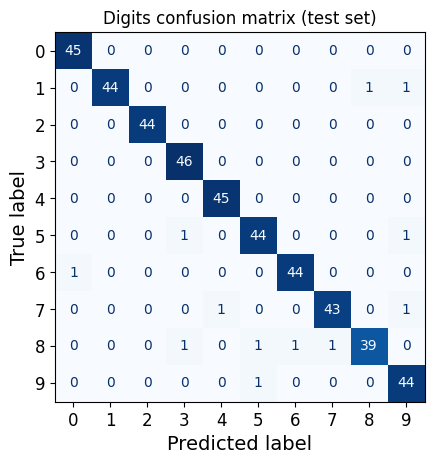

In [ ]:
pred_b = np.argmax(digit_net.predict(X_test_flat, verbose=0), axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, pred_b, cmap="Blues", colorbar=False)
plt.title("Digits confusion matrix (test set)")
plt.show()

### Step 9 — Predict a single image

> **Code explained:** Predicts a single test digit and shows the probabilities, the predicted vs actual digit and the image.

Probabilities: [[0.    0.    0.    0.001 0.    0.    0.    0.    0.999 0.   ]]
Predicted digit: 8 | Actual digit: 8


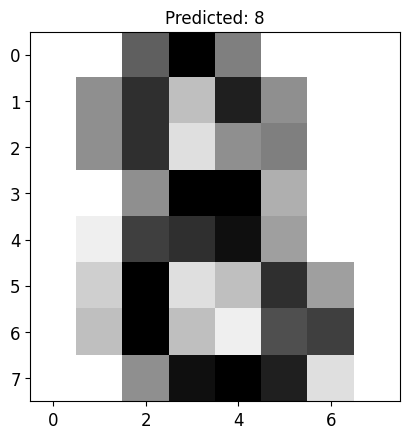

In [ ]:
idx = 0
probs = digit_net.predict(X_test_flat[idx:idx + 1], verbose=0)
print("Probabilities:", probs.round(3))
print("Predicted digit:", np.argmax(probs), "| Actual digit:", y_test[idx])

plt.imshow(X_test[idx], cmap=plt.cm.binary)
plt.title(f"Predicted: {np.argmax(probs)}")
plt.show()

### Which optimizer trains the digit network best?
The optimizer decides *how* the weights are updated. We train the same network with three optimizers and compare them.

> **Code explained:** A small function builds the same Digits network each time. For `adam`, `rmsprop` and `sgd` we fix the random seed, train for 30 epochs, and store the final validation accuracy, the test accuracy and the validation curve. The plot compares the learning speed; the last lines name the best optimizer.

optimizer  final val accuracy  test accuracy
     adam               0.959          0.973
  rmsprop               0.959          0.973
      sgd               0.874          0.911


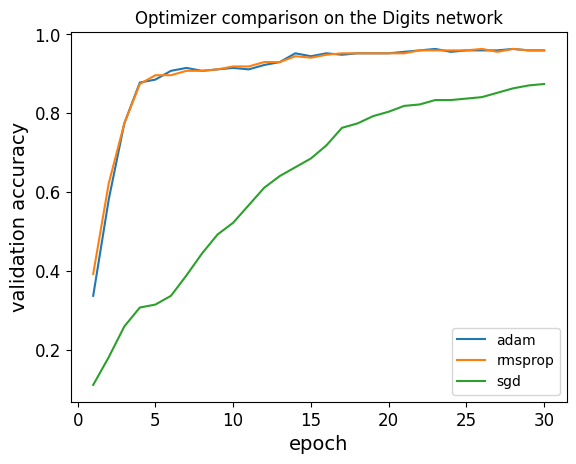


Conclusion: 'adam' reached the highest test accuracy (0.973).


In [ ]:
import pandas as pd

def make_digit_net():
    return models.Sequential([
        layers.Input(shape=(8 * 8,)),
        layers.Dense(48, activation="relu"),
        layers.Dropout(0.25),
        layers.Dense(24, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])

opt_rows, opt_curves = [], {}
for opt in ["adam", "rmsprop", "sgd"]:
    keras.utils.set_random_seed(42)
    net = make_digit_net()
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = net.fit(X_train_flat, y_train, epochs=30, batch_size=32, validation_split=0.2, verbose=0)
    _, test_acc_opt = net.evaluate(X_test_flat, y_test, verbose=0)
    opt_rows.append([opt, hist.history["val_accuracy"][-1], test_acc_opt])
    opt_curves[opt] = hist.history["val_accuracy"]

opt_table = pd.DataFrame(opt_rows, columns=["optimizer", "final val accuracy", "test accuracy"]).round(3)
print(opt_table.to_string(index=False))

for opt, curve in opt_curves.items():
    plt.plot(range(1, len(curve) + 1), curve, label=opt)
plt.xlabel("epoch")
plt.ylabel("validation accuracy")
plt.title("Optimizer comparison on the Digits network")
plt.legend()
plt.show()

best_opt = opt_table.sort_values("test accuracy", ascending=False).iloc[0]
print(f"\nConclusion: '{best_opt['optimizer']}' reached the highest test accuracy ({best_opt['test accuracy']}).")

**Conclusion:** `adam` and `rmsprop` adapt the step size for every weight, so they usually learn fast. Plain `sgd` uses one fixed step size and normally needs more epochs to catch up — the validation curves show this difference in learning speed.

---
## Lab 10 summary
| | Part A (Fashion-MNIST) | Part B (Digits 8×8) |
|---|---|---|
| Training images | 51,000 (+9,000 validation) | ~1,077 (+~270 validation) |
| Input size | 784 | 64 |
| Parameters | 203,530 | 4,546 |
| Labels | one-hot + `categorical_crossentropy` | integers + `sparse_categorical_crossentropy` |
| Overfitting control | validation monitoring | Dropout + EarlyStopping |
| Pixel scaling | ÷ 255 | ÷ 16 |
| Our addition | — | optimizer comparison (adam / rmsprop / sgd) |